# Reoneração da folha (Lei 14.973/2024) — código final usado no paper

Este notebook junta **o código que gerou cada número e figura do PDF final**, na ordem em que roda. Nada aqui foi reescrito: cada célula `%%writefile` é a cópia literal do script que rodou.

**Como conferir sem reestimar (minutos):** rode as células da seção *Conferência* no fim. Elas recalculam a Table 2 dos painéis e mostram a aba `Conferencia` do Excel `resultados_paper_conferencia.xlsx`, que põe cada número do PDF ao lado do valor do CSV (228 números, todos OK).

**Como reestimar tudo (horas, ~30+ GB de RAM):** descomente as linhas `!python ...` na ordem 00 → 10.

| Paper | Script | Saída (CSV) | Aba do Excel |
|---|---|---|---|
| Amostra (137 tratados, 248 controles; seções A e O fora; NEVER_DROP fora) | 00a, 00b, 01 | `painel_balanced_flows.parquet`, `painel_wage.parquet` | Tratados_lista |
| Table 2, Fig 1 | 08 (+ reviewer pack) | `tab_descritivas_recalc.csv` | T2_descritivas |
| Table 3 (β5, β10, Δ, Δ/5), abstract | 03 | `cgs_rodada2_sat_main/tab_att_principal.csv` | T3_ATT_principal |
| Table 4 (placebo 2024) | 03 | `tab_placebo2024.csv` | T4_placebo2024 |
| Table 5 (Tmax e Wald, leads 2023) | 03, 04 | `tab_tmax.csv`, `tab_joint.csv` | T5_Tmax_Wald |
| Table 6 (lean) | 03 | `tab_att_lean_comparacao.csv` | T6_lean |
| Table 7 (dose linear) | 03 | `tab_reta_comparacao.csv` | T7_dose_linear |
| Fig 2, 7–9 (dose-W, 2024 omitido) | 03 | `tab_es_dose_base2024.csv` | ES_dose_base2024 |
| Fig 3, 10–12 (2023 omitido, 2024 livre) | 03, 10 | `tab_es_dose_base2023.csv` | ES_dose_base2023 |
| Fig 4, 13–15 (binário) | 04 | `tab_es_binario_base2024.csv` | ES_binario_base2024 |
| Table 8, Figs 5–6, 16–21 (sem F; CNAE2) | 05, 06, 07 | `cgs_rodada2_sat_main_rob/*.csv` | T8_cortes, ES_dose_semF, ES_dose_cnae2 |
| Figuras em inglês | 09, 10 | `figuras_en_v3/*.png` | — |

Especificação principal: `feols(Y ~ beta5 + beta10 | cnae4^municipio^mes_cal + municipio^time_id + municipio^ano, vcov={'CRV1':'cnae4'})` (pyfixest). Lean: `cnae4^mes_cal + municipio + time_id`.

## 00a_download_caged.py
Download do Novo CAGED (microdados de movimentação) e agregação classe × município × mês.

In [1]:
%%writefile scripts/00a_download_caged.py
"""Download REAL Novo CAGED (FTP MTE) + agrega painel com fluxo e salario.

Painel: competencia x municipio x cnae4 x secao
Cols: admitidos, desligados, saldo, salario_admissao_medio, n_admissao_com_salario
"""
from __future__ import annotations

import argparse
import ftplib
import re
import shutil
import unicodedata
from pathlib import Path

import pandas as pd
import py7zr

ROOT = Path(__file__).resolve().parent
RAW = ROOT / "caged_raw"
SHARDS = ROOT / "caged_shards"
OUT = ROOT / "caged_movimentos.parquet"

FTP_HOST = "ftp.mtps.gov.br"
FTP_BASE = "pdet/microdados/NOVO CAGED"
START = "202301"
END = "202606"


def norm_col(c: str) -> str:
    c = c.replace("\xad", "").replace("\u00ad", "").replace("\xa0", " ")
    c = unicodedata.normalize("NFKD", c)
    c = "".join(ch for ch in c if not unicodedata.combining(ch))
    c = c.strip().lower()
    return re.sub(r"[^a-z0-9]+", "", c)


def map_col(nc: str) -> str | None:
    if nc.startswith("competencia") and "dec" not in nc:
        return "competencia"
    if "municip" in nc:
        return "municipio"
    if nc.startswith("secao") or nc == "secao":
        return "secao"
    if nc.startswith("subclasse"):
        return "subclasse"
    if "saldomoviment" in nc:
        return "saldo_mov"
    if nc == "salario" or (nc.startswith("salario") and "unidade" not in nc and "valor" not in nc and "fixo" not in nc):
        return "salario"
    return None


def month_range(start: str, end: str) -> list[str]:
    out = []
    y, m = int(start[:4]), int(start[4:])
    ye, me = int(end[:4]), int(end[4:])
    while (y < ye) or (y == ye and m <= me):
        out.append(f"{y:04d}{m:02d}")
        m += 1
        if m > 12:
            m = 1
            y += 1
    return out


def ftp_connect() -> ftplib.FTP:
    ftp = ftplib.FTP(FTP_HOST, timeout=180, encoding="latin-1")
    ftp.login()
    return ftp


def download_month(ym: str, dest_7z: Path) -> Path:
    year = ym[:4]
    if dest_7z.exists() and dest_7z.stat().st_size > 1000:
        print(f"[{ym}] ja existe {dest_7z.name} ({dest_7z.stat().st_size:,} bytes)")
        return dest_7z
    ftp = ftp_connect()
    try:
        ftp.cwd(f"{FTP_BASE}/{year}/{ym}")
        names = ftp.nlst()
        match = next((n for n in names if n.upper().startswith("CAGEDMOV") and n.lower().endswith(".7z")), None)
        if not match:
            raise FileNotFoundError(f"CAGEDMOV nao encontrado em {year}/{ym}: {names}")
        print(f"[{ym}] baixando {match} ...")
        with open(dest_7z, "wb") as f:
            ftp.retrbinary(f"RETR {match}", f.write)
        print(f"[{ym}] ok ({dest_7z.stat().st_size:,} bytes)")
    finally:
        try:
            ftp.quit()
        except Exception:
            ftp.close()
    return dest_7z


def extract_txt(archive: Path, out_dir: Path) -> Path:
    out_dir.mkdir(parents=True, exist_ok=True)
    existing = list(out_dir.glob("*.txt")) + list(out_dir.glob("*.TXT"))
    if existing:
        return existing[0]
    print(f"  extraindo {archive.name} ...")
    with py7zr.SevenZipFile(archive, mode="r") as z:
        z.extractall(path=out_dir)
    txts = list(out_dir.glob("*.txt")) + list(out_dir.glob("*.TXT"))
    if not txts:
        raise FileNotFoundError(f"Nenhum .txt em {out_dir}")
    return txts[0]


def parse_br_number(s: pd.Series) -> pd.Series:
    x = s.astype(str).str.strip()
    x = x.str.replace(r"\.", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(x, errors="coerce")


def aggregate_txt(txt_path: Path, ym: str) -> pd.DataFrame:
    with open(txt_path, "r", encoding="utf-8", errors="replace") as f:
        header = f.readline().rstrip("\n\r")
    sep = ";" if header.count(";") >= header.count(",") else ","
    raw_cols = header.split(sep)
    mapping: dict[int, str] = {}
    for i, c in enumerate(raw_cols):
        dest = map_col(norm_col(c))
        if dest and dest not in mapping.values():
            mapping[i] = dest
    needed = {"municipio", "subclasse", "saldo_mov", "secao", "salario"}
    if not needed.issubset(set(mapping.values())):
        normed = [norm_col(c) for c in raw_cols]
        raise ValueError(f"Cols faltando. needed={needed} map={mapping} normed={normed[:30]}")

    usecols = sorted(mapping.keys())
    names = [mapping[i] for i in usecols]
    chunks = []
    for chunk in pd.read_csv(
        txt_path,
        sep=sep,
        encoding="utf-8",
        usecols=usecols,
        names=names,
        header=0,
        dtype=str,
        chunksize=400_000,
        low_memory=False,
    ):
        chunk["municipio"] = chunk["municipio"].astype(str).str.replace(r"\D", "", regex=True).str.zfill(6)
        chunk["subclasse"] = chunk["subclasse"].astype(str).str.replace(r"\D", "", regex=True)
        chunk["cnae4"] = chunk["subclasse"].str[:4]
        chunk["secao"] = chunk["secao"].astype(str).str.strip().str.upper().str[:1]
        mov = pd.to_numeric(chunk["saldo_mov"], errors="coerce").fillna(0).astype("int32")
        sal = parse_br_number(chunk["salario"])
        adm = (mov > 0).astype("int32")
        des = (mov < 0).astype("int32")
        sal_adm = sal.where(adm == 1)
        tmp = pd.DataFrame(
            {
                "competencia": ym,
                "municipio": chunk["municipio"],
                "cnae4": chunk["cnae4"],
                "secao": chunk["secao"],
                "admitidos": adm,
                "desligados": des,
                "saldo": mov,
                "sal_sum": sal_adm.fillna(0.0),
                "sal_n": sal_adm.notna().astype("int32"),
            }
        )
        g = tmp.groupby(["competencia", "municipio", "cnae4", "secao"], as_index=False).sum(numeric_only=True)
        chunks.append(g)

    out = pd.concat(chunks, ignore_index=True)
    out = out.groupby(["competencia", "municipio", "cnae4", "secao"], as_index=False).sum(numeric_only=True)
    out["salario_admissao_medio"] = out["sal_sum"] / out["sal_n"].where(out["sal_n"] > 0)
    out = out.drop(columns=["sal_sum"]).rename(columns={"sal_n": "n_admissao_com_salario"})
    for c in ["admitidos", "desligados", "saldo", "n_admissao_com_salario"]:
        out[c] = out[c].astype("int64")
    return out


def process_month(ym: str, keep_raw: bool = False, force: bool = False) -> Path:
    RAW.mkdir(parents=True, exist_ok=True)
    SHARDS.mkdir(parents=True, exist_ok=True)
    shard = SHARDS / f"caged_{ym}.parquet"
    if shard.exists() and shard.stat().st_size > 1000 and not force:
        cols = set(pd.read_parquet(shard).columns)
        need = {"admitidos", "desligados", "salario_admissao_medio", "secao"}
        if need.issubset(cols):
            print(f"[{ym}] shard completo ja existe")
            return shard
        print(f"[{ym}] shard antigo — reprocessando")
    dest_7z = RAW / f"CAGEDMOV{ym}.7z"
    download_month(ym, dest_7z)
    extract_dir = RAW / ym
    txt = extract_txt(dest_7z, extract_dir)
    df = aggregate_txt(txt, ym)
    df.to_parquet(shard, index=False)
    print(f"[{ym}] shard {shard.name}: {len(df):,} linhas; cols={list(df.columns)}")
    if not keep_raw:
        shutil.rmtree(extract_dir, ignore_errors=True)
        try:
            dest_7z.unlink(missing_ok=True)
        except Exception:
            pass
    return shard


def stack_shards(months: list[str] | None = None) -> Path:
    files = sorted(SHARDS.glob("caged_*.parquet"))
    if months:
        want = {f"caged_{m}.parquet" for m in months}
        files = [f for f in files if f.name in want]
    if not files:
        raise FileNotFoundError("Nenhum shard em caged_shards/")
    dfs = []
    for f in files:
        d = pd.read_parquet(f)
        if "admitidos" not in d.columns:
            raise ValueError(f"Shard antigo sem fluxo: {f.name}. Rode com --force")
        dfs.append(d)
    df = pd.concat(dfs, ignore_index=True)
    df["wsal"] = df["salario_admissao_medio"].fillna(0) * df["n_admissao_com_salario"].fillna(0)
    num = ["admitidos", "desligados", "saldo", "n_admissao_com_salario", "wsal"]
    out = df.groupby(["competencia", "municipio", "cnae4", "secao"], as_index=False)[num].sum()
    out["salario_admissao_medio"] = out["wsal"] / out["n_admissao_com_salario"].where(out["n_admissao_com_salario"] > 0)
    out = out.drop(columns=["wsal"])
    out.to_parquet(OUT, index=False)
    print(
        f"Empilhado {OUT.name}: {len(out):,} linhas, {OUT.stat().st_size:,} bytes, meses={out['competencia'].nunique()}"
    )
    return OUT


def main(start: str = START, end: str = END, keep_raw: bool = False, force: bool = False):
    months = month_range(start, end)
    print(f"Baixando/agregando {len(months)} meses: {months[0]}..{months[-1]} force={force}")
    for ym in months:
        process_month(ym, keep_raw=keep_raw, force=force)
    stack_shards(months)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--start", default=START)
    ap.add_argument("--end", default=END)
    ap.add_argument("--keep-raw", action="store_true")
    ap.add_argument("--only-stack", action="store_true")
    ap.add_argument("--force", action="store_true", help="reprocessa shards antigos")
    args = ap.parse_args()
    if args.only_stack:
        stack_shards(month_range(args.start, args.end))
    else:
        main(args.start, args.end, keep_raw=args.keep_raw, force=args.force)


Overwriting scripts/00a_download_caged.py


In [2]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/00a_download_caged.py

## 00b_amostra_estimacao.py
Amostra de estimação: tratados da lista + controles na mesma seção CNAE; tira seções A e O.

In [3]:
%%writefile scripts/00b_amostra_estimacao.py
﻿"""Monta amostra de estimacao da reoneracao.

Regra (paper):
- mantem CNAEs tratados (lista arts. 7/8 preliminar)
- mantem CNAEs de controle na MESMA secao CNAE dos tratados
- exclui secoes sem vizinho comparavel: A (agro) e O (admin publica)
"""
from __future__ import annotations

from pathlib import Path
import pandas as pd

ROOT = Path(__file__).resolve().parent
EXCLUDE_SECOES = {"A", "O"}


def load_tratados(path: Path | None = None) -> pd.DataFrame:
    path = path or (ROOT / "cnaes_tratados.csv")
    t = pd.read_csv(path)
    t["cnae4"] = t["cnae4"].astype(str).str.zfill(4)
    return t


def build_estimation_sample(
    painel: pd.DataFrame,
    tratados: pd.DataFrame | None = None,
    exclude_secoes: set[str] | None = None,
) -> pd.DataFrame:
    exclude_secoes = exclude_secoes or EXCLUDE_SECOES
    tratados = tratados if tratados is not None else load_tratados()
    df = painel.copy()
    df["cnae4"] = df["cnae4"].astype(str).str.zfill(4)
    if "secao" not in df.columns:
        raise ValueError("painel sem coluna secao — rode download_caged.py --force")
    df["secao"] = df["secao"].astype(str).str.strip().str.upper().str[:1]
    df["tratado"] = df["cnae4"].isin(set(tratados["cnae4"])).astype(int)

    secoes_com_tratado = set(df.loc[df["tratado"] == 1, "secao"].unique())
    secoes_ok = secoes_com_tratado - set(exclude_secoes)

    out = df[df["secao"].isin(secoes_ok)].copy()
    return out.reset_index(drop=True)


def sample_report(df_full: pd.DataFrame, df_est: pd.DataFrame) -> str:
    lines = [
        f"universo: {len(df_full):,} celulas",
        f"amostra estimacao: {len(df_est):,} celulas",
        f"meses: {df_est['competencia'].nunique()} | munis: {df_est['municipio'].nunique()} | cnae4: {df_est['cnae4'].nunique()}",
        f"tratado=1: {(df_est['tratado']==1).sum():,} | controle: {(df_est['tratado']==0).sum():,}",
        "secoes:\n" + df_est.groupby(["secao", "tratado"]).size().unstack(fill_value=0).to_string(),
    ]
    return "\n".join(lines)


if __name__ == "__main__":
    full = pd.read_parquet(ROOT / "caged_movimentos.parquet")
    est = build_estimation_sample(full)
    print(sample_report(full, est))
    est.to_parquet(ROOT / "painel_estimacao.parquet", index=False)
    print("salvou painel_estimacao.parquet")



Overwriting scripts/00b_amostra_estimacao.py


In [4]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/00b_amostra_estimacao.py

## 01_build_panels_run_cristine_att_ano.py
Monta os painéis balanceados (zeros preenchidos, 42 meses, tira NEVER_DROP) e o painel de salário (filtro 0,3–150 SM, tira ago–set/2023). Só a parte `build_panels()` é usada pelo paper; as estimações S1–S6 deste arquivo são da rodada antiga.

In [5]:
%%writefile scripts/01_build_panels_run_cristine_att_ano.py
#!/usr/bin/env python3
"""Cristine / Callaway–Goodman-Bacon–Sant'Anna DiD for reoneração (Lei 14.973/2024).

S1: ATT by year (t2025, t2026) — MAIN
S2: dose×year interactions — check vs S1×dose levels
S3: ES with EVENTUAL dose D̄_s∈{0,10} × 1{k} (so pre PT is testable)
S4: binary ES (annex)
S5/S6: extra FE robustness
Tests: studentized max T (Roth), linearity β2026=2*β2025, placebo 2024
"""
from __future__ import annotations

import gc
import json
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyfixest.estimation import feols
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/workspace/notebook_outputs/cristine_callaway")
OUT.mkdir(parents=True, exist_ok=True)
PANEL_SRC = Path("/workspace/sdid/painel_estimacao.parquet")
PANEL_BAL = OUT / "painel_balanced_flows.parquet"
PANEL_WAGE = OUT / "painel_wage.parquet"
NEVER_DROP = {"1521", "1529", "4911", "5212", "5231", "5510"}
SM = {2023: 1320.0, 2024: 1412.0, 2025: 1518.0, 2026: 1518.0}
FE_PREF = "cnae4^mes_cal + municipio + time_id"
VCOV = {"CRV1": "cnae4"}
RNG = np.random.default_rng(20250301)
PANEL_VERSION = "never_drop_v1"


def _mem(tag: str = "") -> None:
    try:
        import resource

        rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        # Linux: KB
        print(f"[mem] {tag}: maxrss={rss/1e6:.2f} GB", flush=True)
    except Exception:
        pass


def make_kes(k: pd.Series, base_year: int) -> tuple[pd.Series, int]:
    """Map all k belonging to base_year to a single reference value."""
    # k=0 at 202501; year from k: 2025 + floor(k/12), month = k%12 + 1
    # For base 2024: k in [-12, -1]; base 2023: k in [-24, -13]
    if base_year == 2024:
        lo, hi, ref = -12, -1, -12
    elif base_year == 2023:
        lo, hi, ref = -24, -13, -24
    else:
        raise ValueError(base_year)
    kes = k.astype(np.int16).copy()
    kes = kes.where(~((kes >= lo) & (kes <= hi)), other=np.int16(ref))
    return kes, ref


def build_panels() -> dict:
    """Build preferred balanced flow panel + wage sample. Save to disk."""
    if PANEL_BAL.exists() and PANEL_WAGE.exists():
        meta_path = OUT / "panel_meta.json"
        if meta_path.exists():
            cached = json.loads(meta_path.read_text())
            if cached.get("panel_version") == PANEL_VERSION and cached.get("never_drop_applied"):
                print("Using cached balanced panels", flush=True)
                return cached
            print("Cached balanced panels predate NEVER_DROP filter; rebuilding", flush=True)

    print("Loading raw panel...", flush=True)
    cols = [
        "competencia",
        "municipio",
        "cnae4",
        "secao",
        "admitidos",
        "desligados",
        "saldo",
        "n_admissao_com_salario",
        "salario_admissao_medio",
        "tratado",
    ]
    raw = pd.read_parquet(PANEL_SRC, columns=cols)
    raw["cnae4"] = raw["cnae4"].astype(str).str.zfill(4)
    raw["municipio"] = raw["municipio"].astype(str)
    raw["competencia"] = raw["competencia"].astype(str)
    raw["secao"] = raw["secao"].astype(str)

    # Drop sections A/O and NEVER_DROP before pair metadata and balanced grid.
    n0 = len(raw)
    never_before = sorted(NEVER_DROP & set(raw["cnae4"].unique()))
    keep = (~raw["secao"].isin(["A", "O"])) & (~raw["cnae4"].isin(NEVER_DROP))
    raw = raw.loc[keep].copy()
    print(f"Drop A/O + NEVER_DROP: {n0} -> {len(raw)} (removed {n0 - len(raw)})", flush=True)
    print(f"NEVER_DROP removed from flows: {never_before}", flush=True)

    comps = sorted(raw["competencia"].unique())
    assert len(comps) == 42, len(comps)
    assert comps[0] == "202301" and comps[-1] == "202606"

    # Pair-level meta
    meta = (
        raw.groupby(["cnae4", "municipio"], sort=False)
        .agg(secao=("secao", "first"), tratado=("tratado", "max"))
        .reset_index()
    )
    n_pairs = len(meta)
    print(f"Pairs: {n_pairs}", flush=True)

    # Observed flow keys
    raw["admitidos"] = raw["admitidos"].fillna(0).astype(np.int32)
    raw["desligados"] = raw["desligados"].fillna(0).astype(np.int32)
    raw["saldo"] = raw["saldo"].fillna(0).astype(np.int32)

    flow = raw[
        ["cnae4", "municipio", "competencia", "admitidos", "desligados", "saldo"]
    ].copy()
    del raw
    gc.collect()

    print("Building full grid (zeros for silent)...", flush=True)
    # Efficient: MultiIndex from product via merge
    meta["key"] = 1
    comp_df = pd.DataFrame({"competencia": comps, "key": 1})
    grid = meta.merge(comp_df, on="key", how="inner").drop(columns="key")
    # Expected N
    N = len(grid)
    print(f"Grid N={N}; N%42==0 -> {N % 42 == 0}; pairs*42={n_pairs * 42}", flush=True)

    bal = grid.merge(flow, on=["cnae4", "municipio", "competencia"], how="left")
    del grid, flow
    gc.collect()
    for c in ("admitidos", "desligados", "saldo"):
        bal[c] = bal[c].fillna(0).astype(np.int32)

    # Calendar features
    bal["ano"] = bal["competencia"].str[:4].astype(np.int16)
    bal["mes_cal"] = bal["competencia"].str[4:6].astype(np.int8)
    # time_id from sorted competencias
    comp_to_tid = {c: i for i, c in enumerate(comps)}
    bal["time_id"] = bal["competencia"].map(comp_to_tid).astype(np.int16)
    # k relative to 202501 (k=0)
    bal["k"] = ((bal["ano"] - 2025) * 12 + (bal["mes_cal"] - 1)).astype(np.int16)

    # Dose calendar (S1/S2/post): 0 in 2023-24; 5 in 2025 if tratado; 10 in 2026+ if tratado
    bal["tratado"] = bal["tratado"].astype(np.int8)
    bal["dose"] = np.int8(0)
    bal.loc[(bal["tratado"] == 1) & (bal["ano"] == 2025), "dose"] = np.int8(5)
    bal.loc[(bal["tratado"] == 1) & (bal["ano"] >= 2026), "dose"] = np.int8(10)

    # Eventual dose for S3 PT-testable ES: D̄_s ∈ {0, 10}
    bal["dose_bar"] = np.where(bal["tratado"] == 1, np.int8(10), np.int8(0)).astype(np.int8)

    # S1 indicators
    bal["t2025"] = ((bal["ano"] == 2025) & (bal["tratado"] == 1)).astype(np.int8)
    bal["t2026"] = ((bal["ano"] == 2026) & (bal["tratado"] == 1)).astype(np.int8)
    # S2: dose × year (dose already 0 outside treated×year, but explicit)
    bal["dose_2025"] = np.where(bal["ano"] == 2025, bal["dose"], 0).astype(np.int8)
    bal["dose_2026"] = np.where(bal["ano"] == 2026, bal["dose"], 0).astype(np.int8)

    # Lean cats
    for c in ("cnae4", "municipio", "secao", "competencia"):
        bal[c] = bal[c].astype("category")

    print(f"Balanced flows: N={len(bal)}, mem≈{bal.memory_usage(deep=True).sum()/1e9:.2f} GB", flush=True)
    bal.to_parquet(PANEL_BAL, index=False)
    print(f"Saved {PANEL_BAL}", flush=True)

    # Wage sample from ORIGINAL (nonzero salary rows) — re-read raw salary cols
    print("Building wage sample...", flush=True)
    wraw = pd.read_parquet(
        PANEL_SRC,
        columns=[
            "competencia",
            "municipio",
            "cnae4",
            "secao",
            "n_admissao_com_salario",
            "salario_admissao_medio",
            "tratado",
        ],
    )
    wraw["cnae4"] = wraw["cnae4"].astype(str).str.zfill(4)
    wraw["municipio"] = wraw["municipio"].astype(str)
    wraw["competencia"] = wraw["competencia"].astype(str)
    wraw["secao"] = wraw["secao"].astype(str)
    wraw = wraw.loc[
        (~wraw["secao"].isin(["A", "O"])) & (~wraw["cnae4"].isin(NEVER_DROP))
    ].copy()
    wraw["ano"] = wraw["competencia"].str[:4].astype(np.int16)
    wraw["mes_cal"] = wraw["competencia"].str[4:6].astype(np.int8)
    wraw["sm"] = wraw["ano"].map(SM).astype(float)
    wraw["sal"] = pd.to_numeric(wraw["salario_admissao_medio"], errors="coerce")
    wraw["n_adm"] = pd.to_numeric(wraw["n_admissao_com_salario"], errors="coerce").fillna(0)
    # Keep 0.3*SM < sal ≤ 150*SM
    ok = (wraw["sal"] > 0.3 * wraw["sm"]) & (wraw["sal"] <= 150 * wraw["sm"])
    # if n_admissao≤2 and sal>50k → missing
    bad_tiny = (wraw["n_adm"] <= 2) & (wraw["sal"] > 50_000)
    wraw = wraw.loc[ok & ~bad_tiny].copy()
    wraw["log_salario"] = np.log(wraw["sal"].astype(float))
    # Drop 202308–202309 ONLY for salary
    n_before = len(wraw)
    wraw = wraw.loc[~wraw["competencia"].isin(["202308", "202309"])].copy()
    print(
        f"Wage: kept after SM filter then drop 202308-09: final N={len(wraw)} (dropped {n_before - len(wraw)} months 08-09)",
        flush=True,
    )
    wraw["time_id"] = wraw["competencia"].map(comp_to_tid).astype(np.int16)
    wraw["k"] = ((wraw["ano"] - 2025) * 12 + (wraw["mes_cal"] - 1)).astype(np.int16)
    wraw["tratado"] = wraw["tratado"].astype(np.int8)
    wraw["dose"] = np.int8(0)
    wraw.loc[(wraw["tratado"] == 1) & (wraw["ano"] == 2025), "dose"] = np.int8(5)
    wraw.loc[(wraw["tratado"] == 1) & (wraw["ano"] >= 2026), "dose"] = np.int8(10)
    wraw["dose_bar"] = np.where(wraw["tratado"] == 1, np.int8(10), np.int8(0)).astype(np.int8)
    wraw["t2025"] = ((wraw["ano"] == 2025) & (wraw["tratado"] == 1)).astype(np.int8)
    wraw["t2026"] = ((wraw["ano"] == 2026) & (wraw["tratado"] == 1)).astype(np.int8)
    wraw["dose_2025"] = np.where(wraw["ano"] == 2025, wraw["dose"], 0).astype(np.int8)
    wraw["dose_2026"] = np.where(wraw["ano"] == 2026, wraw["dose"], 0).astype(np.int8)
    for c in ("cnae4", "municipio", "secao", "competencia"):
        wraw[c] = wraw[c].astype("category")
    keep_w = [
        "competencia",
        "municipio",
        "cnae4",
        "secao",
        "ano",
        "mes_cal",
        "time_id",
        "k",
        "tratado",
        "dose",
        "dose_bar",
        "t2025",
        "t2026",
        "dose_2025",
        "dose_2026",
        "log_salario",
    ]
    wraw[keep_w].to_parquet(PANEL_WAGE, index=False)
    del wraw
    gc.collect()

    info = {
        "panel_version": PANEL_VERSION,
        "never_drop_applied": True,
        "never_drop": sorted(NEVER_DROP),
        "n_pairs": int(n_pairs),
        "N_flows": int(N),
        "N_mod_42": int(N % 42),
        "n_comps": 42,
        "comps_first": comps[0],
        "comps_last": comps[-1],
        "never_drop_present": sorted(NEVER_DROP & set(meta["cnae4"].astype(str))),
        "never_drop_missing": sorted(NEVER_DROP - set(meta["cnae4"].astype(str))),
        "salary_drop_months": ["202308", "202309"],
        "s3_note": (
            "S3 uses time-invariant eventual dose dose_bar∈{0,10} × 1{k_es}; "
            "NOT calendar Dose (which is 0 in 2023-24 and would make pre interactions identically zero)."
        ),
    }
    (OUT / "panel_meta.json").write_text(json.dumps(info, indent=2))
    del bal, meta
    gc.collect()
    return info


def load_flows(cols: list[str] | None = None) -> pd.DataFrame:
    return pd.read_parquet(PANEL_BAL, columns=cols)


def load_wage(cols: list[str] | None = None) -> pd.DataFrame:
    return pd.read_parquet(PANEL_WAGE, columns=cols)


def fit(fml: str, data: pd.DataFrame, label: str = ""):
    print(f"  FIT {label}: {fml}", flush=True)
    _mem(label + " before")
    try:
        m = feols(
            fml,
            data=data,
            vcov=VCOV,
            lean=True,
            copy_data=False,
            store_data=False,
        )
        return m
    except Exception as e:
        print(f"  FAIL {label}: {type(e).__name__}: {e}", flush=True)
        return None


def tidy_row(m, names: list[str], outcome: str, spec: str) -> list[dict]:
    if m is None:
        return []
    t = m.tidy()
    rows = []
    for name in names:
        if name not in t.index:
            # try alternate index forms
            matches = [i for i in t.index if name in str(i)]
            if not matches:
                continue
            name = matches[0]
        r = t.loc[name]
        rows.append(
            {
                "outcome": outcome,
                "spec": spec,
                "term": name,
                "coef": float(r["Estimate"]),
                "se": float(r["Std. Error"]),
                "t": float(r["t value"]),
                "p": float(r["Pr(>|t|)"]),
                "ci_lo": float(r["2.5%"]),
                "ci_hi": float(r["97.5%"]),
            }
        )
    return rows


def run_S1(df: pd.DataFrame, outcome: str, fe: str = FE_PREF, tag: str = "S1") -> list[dict]:
    fml = f"{outcome} ~ t2025 + t2026 | {fe}"
    m = fit(fml, df, f"{tag}/{outcome}")
    rows = tidy_row(m, ["t2025", "t2026"], outcome, tag)
    # stash model briefly for linearity via returned dict
    return rows, m


def run_S2(df: pd.DataFrame, outcome: str) -> list[dict]:
    fml = f"{outcome} ~ dose_2025 + dose_2026 | {FE_PREF}"
    m = fit(fml, df, f"S2/{outcome}")
    return tidy_row(m, ["dose_2025", "dose_2026"], outcome, "S2"), m


def prepare_es(df: pd.DataFrame, base_year: int) -> pd.DataFrame:
    kes, ref = make_kes(df["k"], base_year)
    out = df.copy()
    out["k_es"] = kes
    out.attrs["ref"] = ref
    out.attrs["base_year"] = base_year
    return out


def run_S3_dose_bar(df: pd.DataFrame, outcome: str, base_year: int = 2024) -> tuple[pd.DataFrame, object]:
    """Event study with eventual dose_bar × i(k_es). PT-testable in pre."""
    kes, ref = make_kes(df["k"], base_year)
    # avoid full copy: attach temporary columns
    df = df.copy(deep=False)
    df["k_es"] = kes
    fml = f"{outcome} ~ i(k_es, ref={ref}):dose_bar | {FE_PREF}"
    m = fit(fml, df, f"S3_b{base_year}/{outcome}")
    rows = []
    levels = []
    if m is not None:
        t = m.tidy()
        for name in t.index:
            # name like k_es::-24:dose_bar
            s = str(name)
            if "k_es::" not in s:
                continue
            try:
                kk = int(s.split("k_es::")[1].split(":")[0])
            except Exception:
                continue
            levels.append(kk)
            r = t.loc[name]
            rows.append(
                {
                    "outcome": outcome,
                    "spec": f"S3_dose_bar_base{base_year}",
                    "k": kk,
                    "term": s,
                    "coef": float(r["Estimate"]),
                    "se": float(r["Std. Error"]),
                    "t": float(r["t value"]),
                    "p": float(r["Pr(>|t|)"]),
                    "ci_lo": float(r["2.5%"]),
                    "ci_hi": float(r["97.5%"]),
                    "ref_k": ref,
                    "base_year": base_year,
                    "scaler": "dose_bar_0_10",
                }
            )
    cols_add = [r["term"] for r in rows]
    return pd.DataFrame(rows), m, sorted(levels), cols_add


def run_S4_binary(df: pd.DataFrame, outcome: str, base_year: int = 2024) -> pd.DataFrame:
    kes, ref = make_kes(df["k"], base_year)
    df = df.copy(deep=False)
    df["k_es"] = kes
    fml = f"{outcome} ~ i(k_es, ref={ref}):tratado | {FE_PREF}"
    m = fit(fml, df, f"S4_b{base_year}/{outcome}")
    rows = []
    if m is not None:
        t = m.tidy()
        for name in t.index:
            s = str(name)
            if "k_es::" not in s:
                continue
            try:
                kk = int(s.split("k_es::")[1].split(":")[0])
            except Exception:
                continue
            r = t.loc[name]
            rows.append(
                {
                    "outcome": outcome,
                    "spec": f"S4_binary_base{base_year}",
                    "k": kk,
                    "term": s,
                    "coef": float(r["Estimate"]),
                    "se": float(r["Std. Error"]),
                    "t": float(r["t value"]),
                    "p": float(r["Pr(>|t|)"]),
                    "ci_lo": float(r["2.5%"]),
                    "ci_hi": float(r["97.5%"]),
                    "ref_k": ref,
                }
            )
    return pd.DataFrame(rows)


def studentized_max_test(m, pre_names: list[str], n_draws: int = 10_000) -> dict:
    """Roth §4.4.1 studentized max pre-trend test using coef VCOV correlation."""
    if m is None or not pre_names:
        return {"error": "no model/pre"}
    t = m.tidy()
    names = [n for n in pre_names if n in t.index]
    if len(names) < 1:
        return {"error": "no pre coefs", "looked_for": pre_names[:5]}
    tvals = np.array([float(t.loc[n, "t value"]) for n in names], dtype=float)
    T_obs = float(np.max(np.abs(tvals)))
    # correlation from VCOV
    coef_idx = list(m.coef().index)
    ix = [coef_idx.index(n) for n in names]
    V = np.asarray(m._vcov, dtype=float)
    Vsub = V[np.ix_(ix, ix)]
    se = np.sqrt(np.clip(np.diag(Vsub), 1e-18, None))
    corr = Vsub / np.outer(se, se)
    # stabilize
    corr = np.clip(corr, -1, 1)
    np.fill_diagonal(corr, 1.0)
    # draws
    try:
        Z = RNG.multivariate_normal(mean=np.zeros(len(names)), cov=corr, size=n_draws)
    except np.linalg.LinAlgError:
        # jitter
        corr2 = corr + np.eye(len(names)) * 1e-8
        Z = RNG.multivariate_normal(mean=np.zeros(len(names)), cov=corr2, size=n_draws)
    max_abs = np.max(np.abs(Z), axis=1)
    p = float(np.mean(max_abs >= T_obs))
    crit = float(np.quantile(max_abs, 0.95))
    return {
        "T_max": T_obs,
        "p": p,
        "crit_5pct": crit,
        "n_pre": len(names),
        "pre_names": names,
        "pre_t": tvals.tolist(),
    }


def linearity_test_S1(m) -> dict:
    """H0: t2026 = 2*t2025 from S1 (dose 10 vs 5 ⇒ ATT_2026 = 2*ATT_2025 under linearity)."""
    if m is None:
        return {"error": "no model"}
    coef = m.coef()
    if "t2025" not in coef.index or "t2026" not in coef.index:
        return {"error": "missing coefs"}
    b5 = float(coef["t2025"])
    b6 = float(coef["t2026"])
    idx = list(coef.index)
    i5, i6 = idx.index("t2025"), idx.index("t2026")
    V = np.asarray(m._vcov, dtype=float)
    # delta: g = b6 - 2*b5; Var = [ -2, 1 ] V [ -2; 1 ]
    R = np.zeros(len(idx))
    R[i5] = -2.0
    R[i6] = 1.0
    g = b6 - 2.0 * b5
    vg = float(R @ V @ R)
    se = float(np.sqrt(max(vg, 0.0)))
    if se > 0:
        z = g / se
        p = float(2 * (1 - stats.norm.cdf(abs(z))))
    else:
        z, p = np.nan, np.nan
    # also try Wald F
    wald_p = np.nan
    try:
        Rm = R.reshape(1, -1)
        w = m.wald_test(R=Rm, q=np.array([0.0]), distribution="chi2")
        wald_p = float(w.get("p_value", w.iloc[-1] if hasattr(w, "iloc") else np.nan))
    except Exception as e:
        wald_p = f"fail:{e}"
    return {
        "b2025": b5,
        "b2026": b6,
        "g_b6_minus_2b5": g,
        "se_g": se,
        "z": z,
        "p_delta": p,
        "wald": wald_p,
        "ratio_b6_over_b5": (b6 / b5) if b5 != 0 else np.nan,
    }


def plot_es(es_df: pd.DataFrame, outcome: str, title_suffix: str, path: Path):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)  # between k=-1 and 0
    ax.errorbar(
        sub["k"],
        sub["coef"],
        yerr=1.96 * sub["se"],
        fmt="o",
        ms=3,
        capsize=2,
        color="C0",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel("Coefficient (per unit eventual dose)")
    ax.set_title(
        f"S3 ES ({outcome}) — eventual dose D̄∈{{0,10}}\n"
        f"ITT of listed class, not ACRT unless linearity+SPT — {title_suffix}"
    )
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def plot_forest_S1(s1_df: pd.DataFrame, path: Path):
    # γ2025/γ2026 for 4 outcomes
    fig, ax = plt.subplots(figsize=(8, 5))
    outcomes = ["saldo", "admitidos", "desligados", "log_salario"]
    ylabels = []
    y = 0
    ys, coefs, ses, colors = [], [], [], []
    for o in outcomes:
        for term, col in [("t2025", "C0"), ("t2026", "C1")]:
            r = s1_df.loc[(s1_df["outcome"] == o) & (s1_df["term"] == term)]
            if r.empty:
                continue
            ys.append(y)
            coefs.append(float(r["coef"].iloc[0]))
            ses.append(float(r["se"].iloc[0]))
            colors.append(col)
            ylabels.append(f"{o} {term}")
            y += 1
    ax.errorbar(coefs, ys, xerr=[1.96 * s for s in ses], fmt="o", color="black", ecolor="gray", capsize=3)
    for yi, c, col in zip(ys, coefs, colors):
        ax.plot(c, yi, "o", color=col)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(ys)
    ax.set_yticklabels(ylabels)
    ax.set_xlabel("ATT (binary treated × year)")
    ax.set_title("S1 forest — ITT of listed class, not ACRT unless linearity+SPT")
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def main():
    print("=== Cristine ATT-by-year pipeline ===", flush=True)
    info = build_panels()
    print(json.dumps(info, indent=2), flush=True)

    flow_cols = [
        "cnae4",
        "municipio",
        "secao",
        "ano",
        "mes_cal",
        "time_id",
        "k",
        "tratado",
        "dose",
        "dose_bar",
        "t2025",
        "t2026",
        "dose_2025",
        "dose_2026",
        "saldo",
        "admitidos",
        "desligados",
    ]

    # Resume: skip S1/S2 if already saved
    s1_path = OUT / "tab_S1_year_att.csv"
    SKIP_S1S2 = s1_path.exists() and (OUT / "tab_S2_dose_year.csv").exists() and (OUT / "tab_linearidade.csv").exists()

    print("Loading balanced flows...", flush=True)
    flows = load_flows(flow_cols)
    print(f"flows N={len(flows)}", flush=True)
    _mem("flows loaded")

    outcomes_flow = ["saldo", "admitidos", "desligados"]
    print("Loading wage...", flush=True)
    wage = load_wage()
    print(f"wage N={len(wage)}", flush=True)

    if SKIP_S1S2:
        print("SKIP S1/S2 — loading existing CSVs", flush=True)
        s1_df = pd.read_csv(OUT / "tab_S1_year_att.csv")
        s2_df = pd.read_csv(OUT / "tab_S2_dose_year.csv")
        s2_check = pd.read_csv(OUT / "tab_S2_vs_S1_check.csv").to_dict("records")
        lin_rows = pd.read_csv(OUT / "tab_linearidade.csv").to_dict("records")
        s1_models = {}
    else:
        s1_rows = []
        s1_models = {}
        s2_rows = []
        lin_rows = []
        for y in outcomes_flow:
            rows, m = run_S1(flows, y)
            s1_rows.extend(rows)
            s1_models[y] = m
            lin = linearity_test_S1(m)
            lin["outcome"] = y
            lin["spec"] = "S1"
            lin_rows.append(lin)
            rows2, m2 = run_S2(flows, y)
            s2_rows.extend(rows2)
            del m2
            gc.collect()
        rows, m = run_S1(wage, "log_salario")
        s1_rows.extend(rows)
        s1_models["log_salario"] = m
        lin = linearity_test_S1(m)
        lin["outcome"] = "log_salario"
        lin["spec"] = "S1"
        lin_rows.append(lin)
        rows2, m2 = run_S2(wage, "log_salario")
        s2_rows.extend(rows2)
        del m2
        gc.collect()
        s1_df = pd.DataFrame(s1_rows)
        s2_df = pd.DataFrame(s2_rows)
        s1_df.to_csv(OUT / "tab_S1_year_att.csv", index=False)
        s2_df.to_csv(OUT / "tab_S2_dose_year.csv", index=False)
        s2_check = []
        for y in ["saldo", "admitidos", "desligados", "log_salario"]:
            b5 = s1_df.loc[(s1_df.outcome == y) & (s1_df.term == "t2025"), "coef"]
            b6 = s1_df.loc[(s1_df.outcome == y) & (s1_df.term == "t2026"), "coef"]
            g5 = s2_df.loc[(s2_df.outcome == y) & (s2_df.term == "dose_2025"), "coef"]
            g6 = s2_df.loc[(s2_df.outcome == y) & (s2_df.term == "dose_2026"), "coef"]
            if b5.empty or g5.empty:
                s2_check.append({"outcome": y, "ok": False, "note": "missing coefs"})
                continue
            b5, b6, g5, g6 = map(float, (b5.iloc[0], b6.iloc[0], g5.iloc[0], g6.iloc[0]))
            ok5 = np.isclose(b5, 5 * g5, rtol=1e-4, atol=1e-6)
            ok6 = np.isclose(b6, 10 * g6, rtol=1e-4, atol=1e-6)
            s2_check.append(
                {
                    "outcome": y,
                    "b2025": b5,
                    "g2025": g5,
                    "5g": 5 * g5,
                    "match_b_eq_5g": bool(ok5),
                    "b2026": b6,
                    "g2026": g6,
                    "10g": 10 * g6,
                    "match_b_eq_10g": bool(ok6),
                    "note": "Identity is β=level*γ (ATT). User text γ≈5β is inverted; we check β≈5γ / β≈10γ.",
                }
            )
            if not (ok5 and ok6):
                print(f"S2 mismatch for {y}: b5={b5} vs 5g={5*g5}; b6={b6} vs 10g={10*g6}", flush=True)
        pd.DataFrame(s2_check).to_csv(OUT / "tab_S2_vs_S1_check.csv", index=False)
        pd.DataFrame(lin_rows).to_csv(OUT / "tab_linearidade.csv", index=False)

    # ---- S3 eventual-dose ES base 2024 (MAIN) ----
    print("=== S3 eventual-dose ES base 2024 ===", flush=True)
    es_all = []
    tmax_rows = []
    for y in outcomes_flow:
        # Need dose_bar, k, FEs, y
        es_df, m, levels, cols_add = run_S3_dose_bar(flows, y, base_year=2024)
        es_all.append(es_df)
        # pre = k in 2023 => original k in [-24,-13]; after make_kes base2024 those stay
        pre_names = [f"k_es::{kk}:dose_bar" for kk in levels if -24 <= kk <= -13]
        tm = studentized_max_test(m, pre_names)
        tm["outcome"] = y
        tm["spec"] = "S3_dose_bar_base2024"
        tm["note"] = "Tests PT in Y(0), NOT SPT. Uses eventual dose_bar so pre interactions ≠ 0."
        tmax_rows.append(tm)
        del m
        gc.collect()

    es_df_w, m_w, levels_w, cols_w = run_S3_dose_bar(wage, "log_salario", base_year=2024)
    es_all.append(es_df_w)
    pre_w = [f"k_es::{kk}:dose_bar" for kk in levels_w if -24 <= kk <= -13]
    tm = studentized_max_test(m_w, pre_w)
    tm["outcome"] = "log_salario"
    tm["spec"] = "S3_dose_bar_base2024"
    tm["note"] = "Tests PT in Y(0), NOT SPT. Wage sample drops 202308-09."
    tmax_rows.append(tm)
    del m_w
    gc.collect()

    es2024 = pd.concat(es_all, ignore_index=True)
    es2024.to_csv(OUT / "tab_es_dose_base2024.csv", index=False)
    # serialize tmax (drop long lists partially)
    tmax_out = []
    for r in tmax_rows:
        rr = {k: v for k, v in r.items() if k not in ("pre_names", "pre_t")}
        rr["pre_names"] = json.dumps(r.get("pre_names", []))
        tmax_out.append(rr)
    pd.DataFrame(tmax_out).to_csv(OUT / "tab_tmax_S3.csv", index=False)

    for y in ["saldo", "admitidos", "desligados", "log_salario"]:
        plot_es(es2024, y, "base 2024", OUT / f"fig_es_S3_base2024_{y}.png")
    plot_forest_S1(s1_df, OUT / "fig_forest_S1.png")

    # S3 base 2023 (also)
    print("=== S3 base 2023 ===", flush=True)
    es23 = []
    for y in outcomes_flow:
        es_df, m, _, _ = run_S3_dose_bar(flows, y, base_year=2023)
        es23.append(es_df)
        del m
        gc.collect()
    es_df, m, _, _ = run_S3_dose_bar(wage, "log_salario", base_year=2023)
    es23.append(es_df)
    del m
    gc.collect()
    pd.concat(es23, ignore_index=True).to_csv(OUT / "tab_es_dose_base2023.csv", index=False)

    # S4 annex binary ES base 2024 — saldo only to save time/mem (or all 4)
    print("=== S4 binary ES annex ===", flush=True)
    s4 = []
    for y in outcomes_flow:
        s4.append(run_S4_binary(flows, y, 2024))
        gc.collect()
    s4.append(run_S4_binary(wage, "log_salario", 2024))
    pd.concat(s4, ignore_index=True).to_csv(OUT / "tab_es_binary_base2024_S4.csv", index=False)
    gc.collect()

    # S5: S1 + municipio^mes_cal
    print("=== S5 municipio^mes_cal ===", flush=True)
    s5_rows = []
    fe5 = "cnae4^mes_cal + municipio^mes_cal + time_id"
    try:
        for y in outcomes_flow:
            rows, m = run_S1(flows, y, fe=fe5, tag="S5")
            s5_rows.extend(rows)
            del m
            gc.collect()
        rows, m = run_S1(wage, "log_salario", fe=fe5, tag="S5")
        s5_rows.extend(rows)
        del m
        s5_note = "ok"
    except Exception as e:
        s5_note = f"OOM/skip: {e}"
        print(s5_note, flush=True)
    if s5_rows:
        pd.DataFrame(s5_rows).to_csv(OUT / "tab_S5.csv", index=False)
    (OUT / "S5_status.txt").write_text(s5_note)

    # S6: S1 + municipio^ano
    print("=== S6 municipio^ano ===", flush=True)
    s6_rows = []
    fe6 = "cnae4^mes_cal + municipio^ano + time_id"
    for y in outcomes_flow:
        rows, m = run_S1(flows, y, fe=fe6, tag="S6")
        s6_rows.extend(rows)
        del m
        gc.collect()
    rows, m = run_S1(wage, "log_salario", fe=fe6, tag="S6")
    s6_rows.extend(rows)
    del m
    pd.DataFrame(s6_rows).to_csv(OUT / "tab_S6.csv", index=False)
    gc.collect()

    # Placebo: through 202412; fake treated×2024
    print("=== Placebo 2024 ===", flush=True)
    pre = flows.loc[flows["ano"] <= 2024].copy()
    pre["t_placebo"] = ((pre["ano"] == 2024) & (pre["tratado"] == 1)).astype(np.int8)
    # ref 2023: only estimate placebo year vs 2023
    placebo_rows = []
    for y in outcomes_flow:
        fml = f"{y} ~ t_placebo | {FE_PREF}"
        # restrict to 2023-2024 already
        m = fit(fml, pre, f"placebo/{y}")
        placebo_rows.extend(tidy_row(m, ["t_placebo"], y, "placebo2024"))
        del m
        gc.collect()
    # wage placebo (wage already dropped 08-09 2023)
    wp = wage.loc[wage["ano"] <= 2024].copy()
    wp["t_placebo"] = ((wp["ano"] == 2024) & (wp["tratado"] == 1)).astype(np.int8)
    m = fit(f"log_salario ~ t_placebo | {FE_PREF}", wp, "placebo/log_salario")
    placebo_rows.extend(tidy_row(m, ["t_placebo"], "log_salario", "placebo2024"))
    del m, pre, wp
    pd.DataFrame(placebo_rows).to_csv(OUT / "tab_placebo2024.csv", index=False)
    gc.collect()

    # Robustness S1 + T_max of S3
    print("=== Robustness ===", flush=True)
    # treated cnae2 divisions
    flows["cnae2"] = flows["cnae4"].astype(str).str[:2]
    treated_div = set(flows.loc[flows["tratado"] == 1, "cnae2"].astype(str).unique())
    rob_specs = {
        "R1_same_cnae2": flows["cnae2"].astype(str).isin(treated_div),
        "R2_drop_F": flows["secao"].astype(str) != "F",
        "R3_drop_FCN": ~flows["secao"].astype(str).isin(["F", "C", "N"]),
    }
    rob_s1 = []
    rob_tmax = []
    for rname, mask in rob_specs.items():
        sub = flows.loc[mask].copy()
        print(f"  {rname} N={len(sub)}", flush=True)
        for y in outcomes_flow:
            rows, m = run_S1(sub, y, tag=rname)
            rob_s1.extend(rows)
            del m
            gc.collect()
        # T_max on saldo S3
        es_df, m, levels, cols_add = run_S3_dose_bar(sub, "saldo", base_year=2024)
        pre_names = [f"k_es::{kk}:dose_bar" for kk in levels if -24 <= kk <= -13]
        tm = studentized_max_test(m, pre_names)
        tm["outcome"] = "saldo"
        tm["spec"] = rname
        rob_tmax.append({k: v for k, v in tm.items() if k not in ("pre_names", "pre_t")})
        del m, sub
        gc.collect()

    # wage robustness R1-R3 for S1 only
    wage["cnae2"] = wage["cnae4"].astype(str).str[:2]
    w_rob = {
        "R1_same_cnae2": wage["cnae2"].astype(str).isin(treated_div),
        "R2_drop_F": wage["secao"].astype(str) != "F",
        "R3_drop_FCN": ~wage["secao"].astype(str).isin(["F", "C", "N"]),
    }
    for rname, mask in w_rob.items():
        sub = wage.loc[mask]
        rows, m = run_S1(sub, "log_salario", tag=rname)
        rob_s1.extend(rows)
        del m
        gc.collect()

    pd.DataFrame(rob_s1).to_csv(OUT / "tab_robustez_S1.csv", index=False)
    pd.DataFrame(rob_tmax).to_csv(OUT / "tab_robustez_tmax.csv", index=False)

    # Optional discarded old anchor
    print("=== Old anchor (discarded) ===", flush=True)
    try:
        rows, m = run_S1(flows, "saldo", fe="cnae4 + municipio + time_id", tag="OLD_anchor_discarded")
        pd.DataFrame(rows).to_csv(OUT / "tab_old_anchor_discarded.csv", index=False)
        del m
    except Exception as e:
        print("old anchor fail", e, flush=True)

    # RESUMO
    write_resumo(info, s1_df, s2_df, s2_check, lin_rows, tmax_rows, placebo_rows, s5_note)
    print("DONE", flush=True)
    print("Outputs in", OUT, flush=True)


def write_resumo(info, s1_df, s2_df, s2_check, lin_rows, tmax_rows, placebo_rows, s5_note):
    lines = []
    lines.append("# RESUMO — Cristine / Callaway ATT-por-ano (Lei 14.973/2024)\n")
    lines.append("## Correção S3 (Econometrics Guy)\n")
    lines.append("Dose calendário = 0 para todos em 2023–24 ⇒ `1{k}·Dose ≡ 0` no pré ⇒ PT/`T_max` impossíveis.")
    lines.append("**S3 usa dose eventual** `dose_bar = 10·1{tratado}` (time-invariant) × `i(k_es)` (base 2024 principal; também base 2023).")
    lines.append("`T_max` testa **PT em Y(0), não SPT**. Não reivindicar ACRT a partir de β único em Dose.\n")
    lines.append("## Painel\n")
    lines.append(f"- Pares cnae4×municipio: **{info['n_pairs']}**")
    lines.append(f"- N flows (balanced zeros): **{info['N_flows']}** (N%42={info['N_mod_42']})")
    lines.append(f"- Competências: {info['comps_first']}–{info['comps_last']} (42)")
    lines.append(f"- NEVER_DROP removidos antes do painel: {info['never_drop']}; remanescentes: {info.get('never_drop_present', [])}")
    lines.append(f"- Salário: drop meses {info['salary_drop_months']} **apenas** em regressões de salário")
    lines.append(f"- S3: {info['s3_note']}\n")

    lines.append("## S1 MAIN — ATT por ano (t2025, t2026)\n")
    lines.append("| outcome | t2025 | se | p | t2026 | se | p |")
    lines.append("|---------|-------|----|---|-------|----|---|")
    for y in ["saldo", "admitidos", "desligados", "log_salario"]:
        r5 = s1_df.loc[(s1_df.outcome == y) & (s1_df.term == "t2025")]
        r6 = s1_df.loc[(s1_df.outcome == y) & (s1_df.term == "t2026")]
        if r5.empty:
            continue
        lines.append(
            f"| {y} | {r5.coef.iloc[0]:.4f} | {r5.se.iloc[0]:.4f} | {r5.p.iloc[0]:.4g} | "
            f"{r6.coef.iloc[0]:.4f} | {r6.se.iloc[0]:.4f} | {r6.p.iloc[0]:.4g} |"
        )

    lines.append("\n## Após dropar NEVER\n")
    old_2025, old_2026 = 0.0216, 0.0148
    s5 = s1_df.loc[(s1_df.outcome == "saldo") & (s1_df.term == "t2025")]
    s6 = s1_df.loc[(s1_df.outcome == "saldo") & (s1_df.term == "t2026")]
    if not s5.empty and not s6.empty:
        new_2025, new_2026 = float(s5.coef.iloc[0]), float(s6.coef.iloc[0])
        d5, d6 = new_2025 - old_2025, new_2026 - old_2026
        material = "movimento material" if max(abs(d5), abs(d6)) >= 0.005 else "sem movimento material (|Δ| < 0.005 em ambos)"
        lines.append(f"- saldo: γ_2025={new_2025:.6f}, γ_2026={new_2026:.6f}; antes 0.0216/0.0148; Δ={d5:+.6f}/{d6:+.6f} — {material}.")
    else:
        lines.append("- saldo: coeficientes S1 não disponíveis para comparação.")

    lines.append("\n## S2 vs S1×dose\n")
    lines.append("Identidade correta: β_YYYY ≈ dose_level × γ_YYYY (5 em 2025, 10 em 2026).")
    lines.append("Texto invertido γ≈5β **não** é a identidade; checamos β≈5γ / β≈10γ.\n")
    for c in s2_check:
        lines.append(
            f"- {c['outcome']}: match_b=5g={c.get('match_b_eq_5g')} match_b=10g={c.get('match_b_eq_10g')} "
            f"(b5={c.get('b2025')}, 5g={c.get('5g')}, b6={c.get('b2026')}, 10g={c.get('10g')})"
        )

    lines.append("\n## Linearidade (H0: β_2026 = 2·β_2025 em S1)\n")
    for r in lin_rows:
        lines.append(
            f"- {r.get('outcome')}: g={r.get('g_b6_minus_2b5'):.4g} se={r.get('se_g'):.4g} "
            f"z={r.get('z'):.4g} p_delta={r.get('p_delta')} ratio={r.get('ratio_b6_over_b5')}"
        )

    lines.append("\n## T_max (S3 dose_bar base2024, pre=k∈2023)\n")
    lines.append("Testa PT em Y(0), **não** SPT. Eventual dose D̄∈{0,10} garante 1{k}·D̄ ≠ 0 no pré.\n")
    for r in tmax_rows:
        lines.append(
            f"- {r.get('outcome')}: T_max={r.get('T_max')} p={r.get('p')} crit5%={r.get('crit_5pct')} n_pre={r.get('n_pre')}"
        )

    lines.append("\n## Placebo 2024 (amostra ≤202412; fake tratado×2024)\n")
    pdf = pd.DataFrame(placebo_rows)
    for _, r in pdf.iterrows():
        lines.append(f"- {r['outcome']}: coef={r['coef']:.4f} se={r['se']:.4f} p={r['p']:.4g}")

    lines.append(f"\n## S5 status: {s5_note}\n")
    lines.append("## Avisos\n")
    lines.append("- Não usar β único em Dose como principal.")
    lines.append("- Não reivindicar ACRT/Callaway contínuo sem SPT+linearidade.")
    lines.append("- S3 NÃO usa Dose calendário no pré (seria identicamente zero).")
    lines.append("- FE preferido: cnae4^mes_cal + municipio + time_id. Nunca cnae4^time_id.\n")

    (OUT / "RESUMO_CRISTINE.md").write_text("\n".join(lines))
    print("Wrote RESUMO_CRISTINE.md", flush=True)


if __name__ == "__main__":
    main()


Overwriting scripts/01_build_panels_run_cristine_att_ano.py


In [6]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/01_build_panels_run_cristine_att_ano.py

## 02_helpers_run_cgs_rodada2.py
Funções auxiliares (dados, FE, Tmax, Wald) importadas pelos scripts 03–07 como `r2`.

In [7]:
%%writefile scripts/02_helpers_run_cgs_rodada2.py
#!/usr/bin/env python3
"""CGS rodada2 — Moreschi reoneração Lei 14.973/2024.

Main: Y ~ t2025 + t2026 | FE  (β5, β10 vs base 2023–24; report Δ=β10−β5 and Δ/5)
Saturated FE side-by-side (FEs that do NOT absorb dose).
Linear Dose = comparison column only.
ES PRINCIPAL: i(k_es)×W_sk with W=0 control; W=5 listed 2023–25; W=10 listed 2026.
Binary tratado×k ES = exposure timing (beside, not principal).
T_max on binary ES 2023 leads = usual PT.
Joint θ_k=0 in 2023 on dose-W ES = common implication of both hyps (not SPT acceptance).

FE_BASE = cnae4^mes_cal + municipio + time_id; vcov CRV1 cnae4.
"""
from __future__ import annotations

import gc
import json
import shutil
import traceback
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyfixest.estimation import feols

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/workspace/notebook_outputs/cgs_rodada2")
OUT.mkdir(parents=True, exist_ok=True)
STAGING = OUT / "drive_staging"
STAGING.mkdir(parents=True, exist_ok=True)
CRISTINE = Path("/workspace/notebook_outputs/cristine_callaway")
PANEL_BAL = CRISTINE / "painel_balanced_flows.parquet"
PANEL_WAGE = CRISTINE / "painel_wage.parquet"
PANEL_META = CRISTINE / "panel_meta.json"

FE_BASE = "cnae4^mes_cal + municipio + time_id"
# Lean saturated first (brief OOM fallback order). Skip UF×time when muni×time present.
FE_SAT_LEAN = "cnae4^mes_cal + municipio^time_id + municipio^ano"
FE_SAT_FULL = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
VCOV = {"CRV1": "cnae4"}
RNG = np.random.default_rng(20250301)
OUTCOMES_FLOW = ["saldo", "admitidos", "desligados"]
OUTCOMES_ALL = OUTCOMES_FLOW + ["log_salario"]

FAILURES: list[str] = []
FE_SAT_USED: str | None = None


def _mem(tag: str = "") -> None:
    try:
        import resource

        rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        print(f"[mem] {tag}: maxrss={rss/1e6:.2f} GB", flush=True)
    except Exception:
        pass


def make_kes(k: pd.Series, base_year: int) -> tuple[pd.Series, int]:
    """Omit FULL base year by collapsing its months to a single ref k."""
    if base_year == 2024:
        lo, hi, ref = -12, -1, -12
    elif base_year == 2023:
        lo, hi, ref = -24, -13, -24
    else:
        raise ValueError(base_year)
    kes = k.astype(np.int16).copy()
    kes = kes.where(~((kes >= lo) & (kes <= hi)), other=np.int16(ref))
    return kes, ref


def assign_W(tratado: pd.Series, ano: pd.Series) -> pd.Series:
    """Assigned dose W_sk for dose-attributed ES.
    controls: 0; listed 2023–2025: 5; listed 2026: 10.
    Pre W=5 is LEAD SCALING (normalization), not calendar dose.
    """
    t = tratado.astype(np.int8)
    a = ano.astype(np.int16)
    w = np.where(t == 0, 0, np.where(a >= 2026, 10, 5)).astype(np.int8)
    return pd.Series(w, index=tratado.index, name="W")


def fit(fml: str, data: pd.DataFrame, label: str = ""):
    print(f"  FIT {label}: {fml}", flush=True)
    _mem(label + " before")
    try:
        return feols(
            fml,
            data=data,
            vcov=VCOV,
            lean=True,
            copy_data=False,
            store_data=False,
        )
    except Exception as e:
        msg = f"FAIL {label}: {type(e).__name__}: {e}"
        print(f"  {msg}", flush=True)
        FAILURES.append(msg)
        return None


def model_N(m) -> int:
    if m is None:
        return 0
    for attr in ("_N", "N", "nobs"):
        if hasattr(m, attr):
            try:
                return int(getattr(m, attr))
            except Exception:
                pass
    return 0


def contrast_delta(m, name5: str = "t2025", name10: str = "t2026") -> dict:
    """β5, β10, Δ=β10−β5, Δ/5 with CRV1 SEs from VCOV."""
    if m is None:
        return {}
    coef = m.coef()
    idx = list(coef.index)
    if name5 not in idx or name10 not in idx:
        return {"error": f"missing {name5}/{name10} in {idx}"}
    i5, i10 = idx.index(name5), idx.index(name10)
    b5 = float(coef[name5])
    b10 = float(coef[name10])
    V = np.asarray(m._vcov, dtype=float)
    se5 = float(np.sqrt(max(V[i5, i5], 0.0)))
    se10 = float(np.sqrt(max(V[i10, i10], 0.0)))
    var_d = V[i10, i10] + V[i5, i5] - 2.0 * V[i10, i5]
    se_d = float(np.sqrt(max(var_d, 0.0)))
    d = b10 - b5
    d5 = d / 5.0
    se_d5 = se_d / 5.0

    def _tp(c, s):
        if s <= 0:
            return float("nan"), float("nan")
        t = c / s
        # normal approx two-sided
        from math import erfc, sqrt

        p = float(erfc(abs(t) / sqrt(2.0)))
        return float(t), p

    t5, p5 = _tp(b5, se5)
    t10, p10 = _tp(b10, se10)
    td, pd_ = _tp(d, se_d)
    td5, pd5 = _tp(d5, se_d5)
    tidy = m.tidy()
    # prefer pyfixest p/t for the two main coefs when available
    if name5 in tidy.index:
        t5 = float(tidy.loc[name5, "t value"])
        p5 = float(tidy.loc[name5, "Pr(>|t|)"])
    if name10 in tidy.index:
        t10 = float(tidy.loc[name10, "t value"])
        p10 = float(tidy.loc[name10, "Pr(>|t|)"])
    return {
        "beta5": b5,
        "se5": se5,
        "t5": t5,
        "p5": p5,
        "beta10": b10,
        "se10": se10,
        "t10": t10,
        "p10": p10,
        "delta": d,
        "se_delta": se_d,
        "t_delta": td,
        "p_delta": pd_,
        "delta_over_5": d5,
        "se_delta_over_5": se_d5,
        "t_delta_over_5": td5,
        "p_delta_over_5": pd5,
        "N": model_N(m),
    }


def rows_from_contrast(c: dict, outcome: str, spec: str, fe: str) -> list[dict]:
    if not c or "beta5" not in c:
        return []
    out = []
    mapping = [
        ("beta5", "beta5", "se5", "t5", "p5"),
        ("beta10", "beta10", "se10", "t10", "p10"),
        ("delta", "delta", "se_delta", "t_delta", "p_delta"),
        ("delta_over_5", "delta_over_5", "se_delta_over_5", "t_delta_over_5", "p_delta_over_5"),
    ]
    for term, ck, sk, tk, pk in mapping:
        out.append(
            {
                "outcome": outcome,
                "spec": spec,
                "fe": fe,
                "term": term,
                "coef": c[ck],
                "se": c[sk],
                "t": c[tk],
                "p": c[pk],
                "N": c["N"],
            }
        )
    return out


def run_att(df: pd.DataFrame, outcome: str, fe: str, tag: str) -> tuple[list[dict], object]:
    fml = f"{outcome} ~ t2025 + t2026 | {fe}"
    m = fit(fml, df, f"{tag}/{outcome}")
    c = contrast_delta(m)
    return rows_from_contrast(c, outcome, tag, fe), m


def run_reta(df: pd.DataFrame, outcome: str, fe: str) -> list[dict]:
    fml = f"{outcome} ~ dose | {fe}"
    m = fit(fml, df, f"reta/{outcome}")
    rows = []
    if m is not None:
        t = m.tidy()
        if "dose" in t.index:
            r = t.loc["dose"]
            rows.append(
                {
                    "outcome": outcome,
                    "spec": "reta_comparacao",
                    "fe": fe,
                    "term": "dose",
                    "coef": float(r["Estimate"]),
                    "se": float(r["Std. Error"]),
                    "t": float(r["t value"]),
                    "p": float(r["Pr(>|t|)"]),
                    "N": model_N(m),
                    "note": "comparison column only; imposes linearity; NOT preferred",
                }
            )
    del m
    gc.collect()
    return rows


def run_es_dose_W(df: pd.DataFrame, outcome: str, base_year: int = 2024, fe: str = FE_BASE):
    """Principal ES: θ_k per-point via 1{t=t*+k}·W_sk."""
    kes, ref = make_kes(df["k"], base_year)
    d = df.copy(deep=False)
    d["k_es"] = kes
    if "W" not in d.columns:
        d["W"] = assign_W(d["tratado"], d["ano"])
    fml = f"{outcome} ~ i(k_es, ref={ref}):W | {fe}"
    m = fit(fml, d, f"ES_dose_W_b{base_year}/{outcome}")
    rows = []
    levels = []
    if m is not None:
        t = m.tidy()
        for name in t.index:
            s = str(name)
            if "k_es::" not in s:
                continue
            try:
                kk = int(s.split("k_es::")[1].split(":")[0])
            except Exception:
                continue
            levels.append(kk)
            r = t.loc[name]
            rows.append(
                {
                    "outcome": outcome,
                    "spec": f"ES_dose_W_base{base_year}",
                    "k": kk,
                    "term": s,
                    "coef": float(r["Estimate"]),
                    "se": float(r["Std. Error"]),
                    "t": float(r["t value"]),
                    "p": float(r["Pr(>|t|)"]),
                    "ci_lo": float(r["2.5%"]),
                    "ci_hi": float(r["97.5%"]),
                    "ref_k": ref,
                    "base_year": base_year,
                    "N": model_N(m),
                    "note": "θ_k per-point; pre W=5 is lead scaling not calendar dose; 5θ≈level 2025; 10θ≈level 2026",
                }
            )
    return pd.DataFrame(rows), m, sorted(levels)


def run_es_binary(df: pd.DataFrame, outcome: str, base_year: int = 2024, fe: str = FE_BASE):
    kes, ref = make_kes(df["k"], base_year)
    d = df.copy(deep=False)
    d["k_es"] = kes
    fml = f"{outcome} ~ i(k_es, tratado, ref={ref}) | {fe}"
    m = fit(fml, d, f"ES_bin_b{base_year}/{outcome}")
    rows = []
    levels = []
    if m is not None:
        t = m.tidy()
        for name in t.index:
            s = str(name)
            if "k_es::" not in s:
                continue
            try:
                kk = int(s.split("k_es::")[1].split(":")[0])
            except Exception:
                continue
            levels.append(kk)
            r = t.loc[name]
            rows.append(
                {
                    "outcome": outcome,
                    "spec": f"ES_binary_base{base_year}",
                    "k": kk,
                    "term": s,
                    "coef": float(r["Estimate"]),
                    "se": float(r["Std. Error"]),
                    "t": float(r["t value"]),
                    "p": float(r["Pr(>|t|)"]),
                    "ci_lo": float(r["2.5%"]),
                    "ci_hi": float(r["97.5%"]),
                    "ref_k": ref,
                    "base_year": base_year,
                    "N": model_N(m),
                    "note": "exposure timing; not principal",
                }
            )
    return pd.DataFrame(rows), m, sorted(levels)


def studentized_max_test(m, pre_names: list[str], n_draws: int = 10_000) -> dict:
    if m is None or not pre_names:
        return {"error": "no model/pre"}
    t = m.tidy()
    names = [n for n in pre_names if n in t.index]
    if len(names) < 1:
        return {"error": "no pre coefs", "looked_for": pre_names[:5]}
    tvals = np.array([float(t.loc[n, "t value"]) for n in names], dtype=float)
    T_obs = float(np.max(np.abs(tvals)))
    coef_idx = list(m.coef().index)
    ix = [coef_idx.index(n) for n in names]
    V = np.asarray(m._vcov, dtype=float)
    Vsub = V[np.ix_(ix, ix)]
    se = np.sqrt(np.clip(np.diag(Vsub), 1e-18, None))
    corr = Vsub / np.outer(se, se)
    corr = np.clip(corr, -1, 1)
    np.fill_diagonal(corr, 1.0)
    try:
        Z = RNG.multivariate_normal(mean=np.zeros(len(names)), cov=corr, size=n_draws)
    except np.linalg.LinAlgError:
        corr2 = corr + np.eye(len(names)) * 1e-8
        Z = RNG.multivariate_normal(mean=np.zeros(len(names)), cov=corr2, size=n_draws)
    max_abs = np.max(np.abs(Z), axis=1)
    p = float(np.mean(max_abs >= T_obs))
    crit = float(np.quantile(max_abs, 0.95))
    return {
        "T_max": T_obs,
        "p": p,
        "crit_5pct": crit,
        "n_pre": len(names),
        "pre_names": names,
        "note": "Usual PT on binary tratado×k ES (Y(0)). Not SPT.",
    }


def joint_theta_pre(m, pre_names: list[str]) -> dict:
    """Wald joint test θ_k=0 for 2023 leads on dose-W ES."""
    if m is None or not pre_names:
        return {"error": "no model/pre"}
    coef_idx = list(m.coef().index)
    names = [n for n in pre_names if n in coef_idx]
    if len(names) < 1:
        return {"error": "no pre coefs", "looked_for": pre_names[:5]}
    k = len(coef_idx)
    m_h = len(names)
    R = np.zeros((m_h, k))
    for i, n in enumerate(names):
        R[i, coef_idx.index(n)] = 1.0
    try:
        res = m.wald_test(R=R)
        stat = float(res["statistic"]) if "statistic" in res.index else float(res.iloc[0])
        pval = float(res["pvalue"]) if "pvalue" in res.index else float(res.iloc[1])
    except Exception as e:
        # manual Wald
        V = np.asarray(m._vcov, dtype=float)
        b = np.asarray(m.coef(), dtype=float)
        ix = [coef_idx.index(n) for n in names]
        Rb = b[ix]
        RVRT = V[np.ix_(ix, ix)]
        try:
            inv = np.linalg.inv(RVRT)
        except np.linalg.LinAlgError:
            inv = np.linalg.pinv(RVRT)
        stat = float(Rb @ inv @ Rb)
        # chi2 p
        from math import gamma

        # survival of chi2(m_h): use scipy if available else erfc approx for large
        try:
            from scipy.stats import chi2

            pval = float(chi2.sf(stat, m_h))
        except Exception:
            pval = float("nan")
            FAILURES.append(f"joint_theta_pre fallback p failed: {e}")
    return {
        "wald_stat": stat,
        "p": pval,
        "n_pre": len(names),
        "df": len(names),
        "pre_names": names,
        "note": (
            "Joint θ_k=0 in 2023 on dose-W ES: common implication of both hyps. "
            "Rejecting counts against that implication. Non-reject ≠ confirm strong hyp / SPT."
        ),
    }


def plot_es_dose(es_df: pd.DataFrame, outcome: str, path: Path):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    # shade 2025 (k=0..11) and 2026 (k=12..17)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08, label="2025 (dose 5)")
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10, label="2026 (dose 10)")
    ax.errorbar(
        sub["k"],
        sub["coef"],
        yerr=1.96 * sub["se"],
        fmt="o",
        ms=3.5,
        capsize=2,
        color="black",
        ecolor="gray",
        label=r"$\theta_k$ (per-point)",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel(r"$\theta_k$ (effect per dose point)")
    ax.set_title(
        f"ES dose-W ({outcome}) — principal; base 2024 omitted\n"
        r"Pre $W{=}5$ = lead scaling (not calendar dose). "
        r"$5\theta_k\approx$ level 2025; $10\theta_k\approx$ level 2026."
    )
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def plot_es_binary(es_df: pd.DataFrame, outcome: str, path: Path):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08)
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10)
    ax.errorbar(
        sub["k"],
        sub["coef"],
        yerr=1.96 * sub["se"],
        fmt="o",
        ms=3,
        capsize=2,
        color="C0",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel("ATT (binary treated × month)")
    ax.set_title(
        f"ES binary ({outcome}) — exposure timing (not principal); base 2024\n"
        "Used for usual PT / T_max on 2023 leads."
    )
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def try_saturated_fe(df: pd.DataFrame, outcome: str = "saldo") -> str:
    """Pick saturated FE that fits; document what ran."""
    global FE_SAT_USED
    for fe, label in [
        (FE_SAT_LEAN, "lean: cnae4^mes_cal + municipio^time_id + municipio^ano"),
        (FE_SAT_FULL, "full: cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"),
    ]:
        print(f"Trying saturated FE ({label})...", flush=True)
        _mem("sat try")
        m = fit(f"{outcome} ~ t2025 + t2026 | {fe}", df, f"sat_probe/{label}")
        if m is not None:
            FE_SAT_USED = fe
            del m
            gc.collect()
            print(f"Saturated FE selected: {fe}", flush=True)
            # Prefer lean if it works; only upgrade to full if lean worked AND full works
            # Brief: try lean first, then add triple if feasible.
            if fe == FE_SAT_LEAN:
                # try full upgrade
                print("Lean OK; probing full triple...", flush=True)
                m2 = fit(
                    f"{outcome} ~ t2025 + t2026 | {FE_SAT_FULL}",
                    df,
                    "sat_probe/full",
                )
                if m2 is not None:
                    FE_SAT_USED = FE_SAT_FULL
                    del m2
                    gc.collect()
                    print(f"Upgraded to full saturated: {FE_SAT_USED}", flush=True)
                else:
                    FAILURES.append(
                        "Full saturated FE (cnae4^municipio^mes_cal + ...) failed; using lean."
                    )
            return FE_SAT_USED
        gc.collect()
    # last resort: base only marked as failed sat
    FAILURES.append("All saturated FE probes failed; saturated table will be empty/partial.")
    FE_SAT_USED = None
    return FE_SAT_USED


def write_texts(info, att_base, att_sat, reta_df, tmax_rows, joint_rows, fe_sat):
    # pull saldo numbers
    def g(df, term, outcome="saldo"):
        r = df.loc[(df.outcome == outcome) & (df.term == term)]
        return None if r.empty else r.iloc[0]

    s5 = g(att_base, "beta5")
    s10 = g(att_base, "beta10")
    sd = g(att_base, "delta")
    sd5 = g(att_base, "delta_over_5")
    tm = next((r for r in tmax_rows if r.get("outcome") == "saldo"), {})
    jt = next((r for r in joint_rows if r.get("outcome") == "saldo"), {})

    # ---- RESUMO ----
    lines = []
    lines.append("# RESUMO_CGS_RODADA2 — Contrastes β5/β10 + ES dose-W\n")
    lines.append("## Identificação\n")
    lines.append(
        f"- Principal ATT: `Y ~ t2025 + t2026 | {FE_BASE}` (CRV1 cnae4)."
    )
    lines.append(
        "- D_s = 1 se classe listada (time-invariant). Base omitida: 2023–2024. "
        "2026 só até junho. β5 = 2025 vs base; β10 = 2026 vs **mesma** base (não vs 2025)."
    )
    lines.append(
        "- Reportamos também Δ=β10−β5 e (β10−β5)/5 com EP clusterizado do contraste."
    )
    lines.append(
        f"- FE saturada (lado a lado): `{fe_sat}` "
        "(FEs que não absorvem dose; sem class×year / class×civil month / class×2025–26). "
        "UF×time omitido quando municipio^time_id está presente."
    )
    lines.append(
        "- Reta linear em Dose: **coluna de comparação apenas** (não preferida)."
    )
    lines.append(
        "- ES **principal**: `i(k_es)×W_sk` com W=0 (controle); W=5 (listada 2023–2025); "
        "W=10 (listada 2026). Pré W=5 = **escala do lead** (normalização), não dose calendário."
    )
    lines.append(
        "- ES binário tratado×k: ao lado, timing de exposição (não principal). "
        "T_max nos leads 2023 do binário = PT usual."
    )
    lines.append(
        "- Teste conjunto θ_k=0 em 2023 no ES dose-W = implicação comum das duas hipóteses; "
        "não-rejeição ≠ confirmação da hipótese forte / SPT.\n"
    )
    lines.append("## Painel\n")
    lines.append(f"- Pares: **{info.get('n_pairs')}**; N flows: **{info.get('N_flows')}**")
    lines.append(f"- Competências: {info.get('comps_first')}–{info.get('comps_last')}")
    lines.append(f"- NEVER_DROP: {info.get('never_drop')}")
    lines.append(f"- Wage drop months: {info.get('salary_drop_months')}\n")

    lines.append("## Contrastes ATT (FE base)\n")
    lines.append("| outcome | β5 | se | β10 | se | Δ | se | Δ/5 | se | N |")
    lines.append("|---------|----|----|-----|----|---|----|-----|----|---|")
    for y in OUTCOMES_ALL:
        r5, r10, rd, rd5 = g(att_base, "beta5", y), g(att_base, "beta10", y), g(att_base, "delta", y), g(att_base, "delta_over_5", y)
        if r5 is None:
            continue
        lines.append(
            f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r10.coef:.4f} | {r10.se:.4f} | "
            f"{rd.coef:.4f} | {rd.se:.4f} | {rd5.coef:.4f} | {rd5.se:.4f} | {int(r5.N)} |"
        )

    lines.append("\n## Contrastes ATT (FE saturada)\n")
    if att_sat is not None and len(att_sat):
        lines.append(f"FE usada: `{fe_sat}`\n")
        lines.append("| outcome | β5 | se | β10 | se | Δ | se | Δ/5 | se | N |")
        lines.append("|---------|----|----|-----|----|---|----|-----|----|---|")
        for y in OUTCOMES_ALL:
            r5, r10, rd, rd5 = g(att_sat, "beta5", y), g(att_sat, "beta10", y), g(att_sat, "delta", y), g(att_sat, "delta_over_5", y)
            if r5 is None:
                continue
            lines.append(
                f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r10.coef:.4f} | {r10.se:.4f} | "
                f"{rd.coef:.4f} | {rd.se:.4f} | {rd5.coef:.4f} | {rd5.se:.4f} | {int(r5.N)} |"
            )
    else:
        lines.append("_Saturada não estimada (ver failures)._\n")

    lines.append("\n## Reta comparação (Dose linear)\n")
    for _, r in reta_df.iterrows():
        lines.append(
            f"- {r['outcome']}: coef={r['coef']:.6g} se={r['se']:.4g} p={r['p']:.4g} "
            "(comparison only; not preferred)"
        )

    lines.append("\n## T_max PT usual (ES binário base2024, k∈2023)\n")
    for r in tmax_rows:
        lines.append(
            f"- {r.get('outcome')}: T_max={r.get('T_max')} p={r.get('p')} "
            f"crit5%={r.get('crit_5pct')} n_pre={r.get('n_pre')} — PT usual, não SPT."
        )

    lines.append("\n## Joint θ_pre dose-W (2023)\n")
    for r in joint_rows:
        lines.append(
            f"- {r.get('outcome')}: Wald={r.get('wald_stat')} p={r.get('p')} "
            f"df={r.get('df')} — implicação comum; não-rejeição ≠ aceitar hipótese forte."
        )

    lines.append("\n## Caveats (linguagem)\n")
    lines.append(
        "1. W_sk=5 no pré é **escala do lead**, não dose real; θ_k pré é efeito por ponto sob essa normalização."
    )
    lines.append(
        "2. (β10−β5)/5 sob hipótese forte (CGS Thm 3.3(d)) seria ACRT, mas com dinâmica de 2026 "
        "(já um ano em dose 5) **não** declaramos ACRT limpo / hipótese validada."
    )
    lines.append(
        "3. T_max no ES binário = PT usual; joint θ_2023 no ES dose-W = implicação conjunta, não aceite da forte."
    )
    lines.append(
        "4. Não usamos β5/5 = β10/10 como teste da hipótese forte."
    )
    lines.append(
        "5. Wage: pre-trends já fracos na rodada anterior — manter caveat.\n"
    )

    if FAILURES:
        lines.append("## Failures\n")
        for f in FAILURES:
            lines.append(f"- {f}")
        lines.append("")

    (OUT / "RESUMO_CGS_RODADA2.md").write_text("\n".join(lines), encoding="utf-8")
    print("Wrote RESUMO_CGS_RODADA2.md", flush=True)

    # ---- TEXTO RESULTADOS (PT) with mandatory §3 paragraph ----
    if s5 is not None and sd5 is not None:
        b5, se5 = float(s5.coef), float(s5.se)
        b10, se10 = float(s10.coef), float(s10.se)
        dlt, sed = float(sd.coef), float(sd.se)
        d5, se_d5 = float(sd5.coef), float(sd5.se)
        p_d5 = float(sd5.p)
        N = int(s5.N)
        tmax_p = tm.get("p", float("nan"))
        tmax_v = tm.get("T_max", float("nan"))
        joint_p = jt.get("p", float("nan"))
        joint_w = jt.get("wald_stat", float("nan"))
    else:
        b5 = se5 = b10 = se10 = dlt = sed = d5 = se_d5 = p_d5 = N = float("nan")
        tmax_p = tmax_v = joint_p = joint_w = float("nan")

    texto = f"""# TEXTO_RESULTADOS_RODADA2 — Projeto Reoneração Folha (Lei 14.973/2024)

## 1. Especificação principal (contrastes anuais)

Estimamos
Y_smt = α_{{s,c(t)}} + μ_m + λ_t + β5 (D_s × 1{{2025}}) + β10 (D_s × 1{{2026}}) + ε,
com D_s = 1 se a classe CNAE está listada (invariante no tempo) e 0 caso contrário. A base omitida é 2023–2024; 2026 entra só até junho. Assim β5 é o ATT da listada em 2025 versus a base zero, e β10 é o ATT em 2026 versus a **mesma** base (não versus 2025). FE base: `{FE_BASE}`; erros CRV1 por cnae4. Também reportamos o contraste Δ = β10 − β5 e (β10 − β5)/5 com erro-padrão clusterizado do contraste.

Para **saldo**, β5 = {b5:.4f} (EP = {se5:.4f}), β10 = {b10:.4f} (EP = {se10:.4f}), Δ = {dlt:.4f} (EP = {sed:.4f}), (β10−β5)/5 = {d5:.4f} (EP = {se_d5:.4f}, p = {p_d5:.3f}), N = {N}. Análogos para admitidos, desligados e log do salário de admissão (amostra salarial com filtro 0,3–150 SM e exclusão de 202308–09; pre-trends de salário já fracos — caveat mantido).

A reta Y ~ Dose | FE é mantida apenas como **coluna de comparação** (impõe linearidade; não é a especificação preferida).

FE saturada lado a lado (sem absorver dose): `{fe_sat}`. Não incluímos class×year, class×mês civil nem dummies class×2025/2026. Com municipio^time_id presente, UF×time é omitido por colinearidade.

## 2. Estudo de eventos

O ES **principal** multiplica o mês de evento pela dose atribuída W_sk: controles W=0; listadas em 2023–2025 W=5; listadas em 2026 W=10. Base B = ano civil 2024 omitido por completo. Os coeficientes θ_k são efeitos **por ponto** daquele mês: 5θ_k ≈ nível em 2025 e 10θ_k ≈ nível em 2026. Importante: W=5 no período pré-tratamento é **escala do lead** (normalização para o lead não zerar), **não** dose calendário real — o θ_k pré interpreta-se como efeito por ponto sob essa normalização.

O ES binário tratado×k permanece ao lado como descrição do **timing de exposição**, não como especificação principal. A base-2023 com W=5 nas listadas serve de checagem de antecipação (sem afirmar que antecipação “não paga”).

## 3. Interpretação de (β10 − β5)/5 sob a hipótese forte (obrigatório)

Sob a hipótese forte de tendências paralelas em doses (CGS, Teorema 3.3(d)), a quantidade (β10 − β5)/5 = {d5:.4f} (EP = {se_d5:.4f}) identifica o ACRT — o efeito causal médio de um ponto adicional de dose entre 5 e 10. Sem a hipótese forte, o mesmo objeto é a soma de um termo de incremento de dose e um termo de seleção (Teorema 3.2). A razão para invocar a interpretação forte neste desenho é institucional: a Lei 14.973/2024 atribui mecanicamente dose 5 e depois dose 10 às **mesmas** classes listadas; não há duas subpopulações listadas escolhendo doses diferentes no mesmo mês civil — o termo de seleção, portanto, não tem um grupo observável em que se apoiar. **Caveat decisivo:** 2026 já carrega um ano inteiro sob dose 5; dinâmicas de ajuste, estoque e composição permanecem. Por isso reportamos (β10 − β5)/5 com o parágrafo da hipótese forte, mas **não** declaramos ACRT limpo nem validamos a hipótese forte / SPT. Em particular, **não** usamos o teste β5/5 = β10/10 como prova da hipótese forte.

## 4. Checagens de pré-tendência

- **Nível (PT usual):** T_max studentizado nos leads de 2023 do ES **binário** (base 2024). Para saldo, T_max = {tmax_v} (p = {tmax_p}). Isso é o teste usual de parallel trends em Y(0), não SPT.
- **Inclinação (implicação conjunta):** teste de Wald conjunto θ_k = 0 em 2023 no ES dose-W (análogo à Fig. 10). Para saldo, Wald = {joint_w} (p = {joint_p}). Rejeitar conta contra uma implicação comum das duas hipóteses; **não rejeitar não confirma** a hipótese forte.

## 5. Avisos finais

Wage: pre-trends já frágeis — manter cautela. Não destruir artefatos das rodadas anteriores (`cgs_saturado/`, `cristine_callaway/`). Não editar Overleaf nesta rodada.
"""
    (OUT / "TEXTO_RESULTADOS_RODADA2.md").write_text(texto, encoding="utf-8")
    print("Wrote TEXTO_RESULTADOS_RODADA2.md", flush=True)


def stage_drive():
    keep = [
        "tab_att_contrastes.csv",
        "tab_att_saturada.csv",
        "tab_reta_comparacao.csv",
        "tab_es_dose_base2024.csv",
        "tab_es_binario_base2024.csv",
        "tab_tmax_binario.csv",
        "tab_joint_theta_pre_dose.csv",
        "RESUMO_CGS_RODADA2.md",
        "TEXTO_RESULTADOS_RODADA2.md",
        "key_numbers.json",
        "run_cgs_rodada2.py",
        "notebook_reoneracao_cgs_rodada2.ipynb",
        "fig_es_dose_base2024_saldo.png",
        "fig_es_dose_base2024_admitidos.png",
        "fig_es_dose_base2024_desligados.png",
        "fig_es_dose_base2024_log_salario.png",
        "fig_es_binario_base2024_saldo.png",
    ]
    for name in keep:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, STAGING / name)
    print(f"Staged {len(list(STAGING.iterdir()))} files to drive_staging/", flush=True)


def main():
    print("=== CGS rodada2 pipeline ===", flush=True)
    info = json.loads(PANEL_META.read_text()) if PANEL_META.exists() else {}
    print(json.dumps({k: info.get(k) for k in ("n_pairs", "N_flows", "comps_first", "comps_last", "never_drop")}, indent=2), flush=True)

    flow_cols = [
        "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
        "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
    ]
    print("Loading flows...", flush=True)
    flows = pd.read_parquet(PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(PANEL_WAGE)
    flows["W"] = assign_W(flows["tratado"], flows["ano"])
    wage["W"] = assign_W(wage["tratado"], wage["ano"])
    # sanity: dose calendar still 0 in pre; W is 5 for listed pre
    pre_mask = flows["ano"].isin([2023, 2024])
    assert (flows.loc[pre_mask, "dose"] == 0).all(), "calendar dose nonzero in pre"
    listed_pre = pre_mask & (flows["tratado"] == 1)
    assert (flows.loc[listed_pre, "W"] == 5).all(), "W!=5 for listed pre"
    assert (flows.loc[flows["tratado"] == 0, "W"] == 0).all()
    print(f"flows N={len(flows)}; wage N={len(wage)}; W unique={sorted(flows['W'].unique())}", flush=True)
    _mem("loaded")

    # ---- ATT base contrasts ----
    print("=== ATT base contrasts ===", flush=True)
    att_rows = []
    for y in OUTCOMES_FLOW:
        rows, m = run_att(flows, y, FE_BASE, "att_base")
        att_rows.extend(rows)
        del m
        gc.collect()
    rows, m = run_att(wage, "log_salario", FE_BASE, "att_base")
    att_rows.extend(rows)
    del m
    gc.collect()
    att_base = pd.DataFrame(att_rows)
    att_base.to_csv(OUT / "tab_att_contrastes.csv", index=False)
    print(att_base.to_string(index=False), flush=True)

    # ---- Saturated FE ----
    print("=== Saturated FE probe + ATT ===", flush=True)
    fe_sat = try_saturated_fe(flows, "saldo")
    att_sat_rows = []
    if fe_sat:
        for y in OUTCOMES_FLOW:
            rows, m = run_att(flows, y, fe_sat, "att_saturada")
            att_sat_rows.extend(rows)
            del m
            gc.collect()
        rows, m = run_att(wage, "log_salario", fe_sat, "att_saturada")
        att_sat_rows.extend(rows)
        del m
        gc.collect()
    att_sat = pd.DataFrame(att_sat_rows)
    att_sat.to_csv(OUT / "tab_att_saturada.csv", index=False)

    # ---- Reta comparação ----
    print("=== Reta comparação ===", flush=True)
    reta_rows = []
    for y in OUTCOMES_FLOW:
        reta_rows.extend(run_reta(flows, y, FE_BASE))
        gc.collect()
    reta_rows.extend(run_reta(wage, "log_salario", FE_BASE))
    reta_df = pd.DataFrame(reta_rows)
    reta_df.to_csv(OUT / "tab_reta_comparacao.csv", index=False)

    # ---- ES dose-W PRINCIPAL base 2024 + joint θ_pre ----
    print("=== ES dose-W principal base2024 + joint θ_pre ===", flush=True)
    es_dose_all = []
    joint_rows = []
    for y in OUTCOMES_FLOW:
        es_df, m, levels = run_es_dose_W(flows, y, base_year=2024, fe=FE_BASE)
        es_dose_all.append(es_df)
        pre_names = [f"k_es::{kk}:W" for kk in levels if -24 <= kk <= -13]
        # also try alternate name patterns from pyfixest
        if m is not None:
            idx = list(m.coef().index)
            alt = [n for n in idx if "k_es::" in str(n) and any(f"::{kk}:" in str(n) or str(n).endswith(f"::{kk}") for kk in range(-24, -12))]
            # build pre_names from actual index
            pre_names = []
            for n in idx:
                s = str(n)
                if "k_es::" not in s:
                    continue
                try:
                    kk = int(s.split("k_es::")[1].split(":")[0])
                except Exception:
                    continue
                if -24 <= kk <= -13:
                    pre_names.append(s)
        jt = joint_theta_pre(m, pre_names)
        jt["outcome"] = y
        jt["spec"] = "ES_dose_W_base2024"
        joint_rows.append(jt)
        del m
        gc.collect()

    es_df, m, levels = run_es_dose_W(wage, "log_salario", base_year=2024, fe=FE_BASE)
    es_dose_all.append(es_df)
    pre_names = []
    if m is not None:
        for n in m.coef().index:
            s = str(n)
            if "k_es::" not in s:
                continue
            try:
                kk = int(s.split("k_es::")[1].split(":")[0])
            except Exception:
                continue
            if -24 <= kk <= -13:
                pre_names.append(s)
    jt = joint_theta_pre(m, pre_names)
    jt["outcome"] = "log_salario"
    jt["spec"] = "ES_dose_W_base2024"
    joint_rows.append(jt)
    del m
    gc.collect()

    es_dose = pd.concat([e for e in es_dose_all if e is not None and len(e)], ignore_index=True)
    es_dose.to_csv(OUT / "tab_es_dose_base2024.csv", index=False)
    joint_out = []
    for r in joint_rows:
        rr = {k: v for k, v in r.items() if k != "pre_names"}
        rr["pre_names"] = json.dumps(r.get("pre_names", []))
        joint_out.append(rr)
    pd.DataFrame(joint_out).to_csv(OUT / "tab_joint_theta_pre_dose.csv", index=False)

    for y in OUTCOMES_ALL:
        plot_es_dose(es_dose, y, OUT / f"fig_es_dose_base2024_{y}.png")

    # ES dose-W base 2023 anticipation (table only)
    print("=== ES dose-W base2023 (anticipation check) ===", flush=True)
    es23 = []
    for y in OUTCOMES_FLOW:
        es_df, m, _ = run_es_dose_W(flows, y, base_year=2023, fe=FE_BASE)
        es23.append(es_df)
        del m
        gc.collect()
    es_df, m, _ = run_es_dose_W(wage, "log_salario", base_year=2023, fe=FE_BASE)
    es23.append(es_df)
    del m
    gc.collect()
    pd.concat([e for e in es23 if e is not None and len(e)], ignore_index=True).to_csv(
        OUT / "tab_es_dose_base2023.csv", index=False
    )

    # ---- ES binary (timing) + T_max ----
    print("=== ES binary base2024 + T_max ===", flush=True)
    es_bin_all = []
    tmax_rows = []
    for y in OUTCOMES_FLOW:
        es_df, m, levels = run_es_binary(flows, y, base_year=2024, fe=FE_BASE)
        es_bin_all.append(es_df)
        pre_names = []
        if m is not None:
            for n in m.coef().index:
                s = str(n)
                if "k_es::" not in s:
                    continue
                try:
                    kk = int(s.split("k_es::")[1].split(":")[0])
                except Exception:
                    continue
                if -24 <= kk <= -13:
                    pre_names.append(s)
        tm = studentized_max_test(m, pre_names)
        tm["outcome"] = y
        tm["spec"] = "ES_binary_base2024"
        tmax_rows.append(tm)
        del m
        gc.collect()
    es_df, m, levels = run_es_binary(wage, "log_salario", base_year=2024, fe=FE_BASE)
    es_bin_all.append(es_df)
    pre_names = []
    if m is not None:
        for n in m.coef().index:
            s = str(n)
            if "k_es::" not in s:
                continue
            try:
                kk = int(s.split("k_es::")[1].split(":")[0])
            except Exception:
                continue
            if -24 <= kk <= -13:
                pre_names.append(s)
    tm = studentized_max_test(m, pre_names)
    tm["outcome"] = "log_salario"
    tm["spec"] = "ES_binary_base2024"
    tmax_rows.append(tm)
    del m
    gc.collect()

    es_bin = pd.concat([e for e in es_bin_all if e is not None and len(e)], ignore_index=True)
    es_bin.to_csv(OUT / "tab_es_binario_base2024.csv", index=False)
    tmax_out = []
    for r in tmax_rows:
        rr = {k: v for k, v in r.items() if k not in ("pre_names", "pre_t")}
        rr["pre_names"] = json.dumps(r.get("pre_names", []))
        tmax_out.append(rr)
    pd.DataFrame(tmax_out).to_csv(OUT / "tab_tmax_binario.csv", index=False)

    # at least saldo binary fig; also others if cheap
    plot_es_binary(es_bin, "saldo", OUT / "fig_es_binario_base2024_saldo.png")
    for y in ["admitidos", "desligados", "log_salario"]:
        plot_es_binary(es_bin, y, OUT / f"fig_es_binario_base2024_{y}.png")

    write_texts(info, att_base, att_sat, reta_df, tmax_rows, joint_rows, fe_sat or "NONE")

    # key numbers
    def grab(term):
        r = att_base.loc[(att_base.outcome == "saldo") & (att_base.term == term)]
        return float(r.coef.iloc[0]), float(r.se.iloc[0]), float(r.p.iloc[0])

    b5, se5, p5 = grab("beta5")
    b10, se10, p10 = grab("beta10")
    dlt, sed, pdlt = grab("delta")
    d5, sed5, pd5 = grab("delta_over_5")
    tm = next(r for r in tmax_rows if r.get("outcome") == "saldo")
    jt = next(r for r in joint_rows if r.get("outcome") == "saldo")
    summary = {
        "saldo_beta5": b5,
        "saldo_beta5_se": se5,
        "saldo_beta5_p": p5,
        "saldo_beta10": b10,
        "saldo_beta10_se": se10,
        "saldo_beta10_p": p10,
        "saldo_delta": dlt,
        "saldo_delta_se": sed,
        "saldo_delta_p": pdlt,
        "saldo_delta_over_5": d5,
        "saldo_delta_over_5_se": sed5,
        "saldo_delta_over_5_p": pd5,
        "saldo_N": int(att_base.loc[(att_base.outcome == "saldo") & (att_base.term == "beta5"), "N"].iloc[0]),
        "tmax_saldo": tm.get("T_max"),
        "tmax_p_saldo": tm.get("p"),
        "joint_theta_pre_wald_saldo": jt.get("wald_stat"),
        "joint_theta_pre_p_saldo": jt.get("p"),
        "fe_base": FE_BASE,
        "fe_sat_used": fe_sat,
        "failures": FAILURES,
        "out_dir": str(OUT),
    }
    (OUT / "key_numbers.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print("KEY", json.dumps(summary, indent=2), flush=True)

    stage_drive()
    print("DONE", flush=True)
    return summary


if __name__ == "__main__":
    try:
        main()
    except Exception:
        traceback.print_exc()
        (OUT / "run_FAILED.txt").write_text(traceback.format_exc(), encoding="utf-8")
        raise


Overwriting scripts/02_helpers_run_cgs_rodada2.py


In [8]:
!python scripts/02_helpers_run_cgs_rodada2.py

/usr/bin/sh: 1: python: not found


## 03_run_cgs_sat_main.py
**Principal.** β5/β10/Δ/Δ/5 (FE principal e lean), dose linear, placebo 2024, ES dose-W base 2024 + Wald, ES dose-W base 2023.

In [9]:
%%writefile scripts/03_run_cgs_sat_main.py
#!/usr/bin/env python3
"""CGS rodada2 sat-main — PROMOTE saturated FE to PRINCIPAL.

FE_MAIN = cnae4^municipio^mes_cal + municipio^time_id + municipio^ano
FE_LEAN = cnae4^mes_cal + municipio + time_id  (old principal → comparison only)

Reuses panels + helpers from cgs_rodada2/run_cgs_rodada2.py.
OUT = cgs_rodada2_sat_main/ (does NOT destroy cgs_rodada2).
vcov CRV1 cnae4. If FE_MAIN OOMs on ES, fall back to leaner and document.
"""
from __future__ import annotations

import gc
import json
import shutil
import sys
import traceback
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("/workspace/notebook_outputs/cgs_rodada2")
sys.path.insert(0, str(ROOT))

import run_cgs_rodada2 as r2  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main")
OUT.mkdir(parents=True, exist_ok=True)
REMODELADO = Path("/workspace/notebook_outputs/REMODELADO_expand_sat")
(REMODELADO / "tabs").mkdir(parents=True, exist_ok=True)
(REMODELADO / "figuras").mkdir(parents=True, exist_ok=True)

FE_MAIN = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
FE_LEAN = "cnae4^mes_cal + municipio + time_id"  # old principal → comparison
# Intermediate leaner saturated (no triple): for ES OOM fallback
FE_SAT_LEAN = "cnae4^mes_cal + municipio^time_id + municipio^ano"

OUTCOMES_FLOW = r2.OUTCOMES_FLOW
OUTCOMES_ALL = r2.OUTCOMES_ALL
PANEL_BAL = r2.PANEL_BAL
PANEL_WAGE = r2.PANEL_WAGE
PANEL_META = r2.PANEL_META

# Redirect rodada2 FAILURES list usage
FAILURES: list[str] = []
r2.FAILURES = FAILURES
r2.OUT = OUT  # so any leftover writes go here if called

ES_FE_USED: dict[str, str] = {}  # outcome -> fe actually used for ES


def _mem(tag: str = "") -> None:
    r2._mem(tag)


def fit(fml, data, label=""):
    return r2.fit(fml, data, label)


def pre_names_from_model(m, k_lo=-24, k_hi=-13):
    names = []
    if m is None:
        return names
    for n in m.coef().index:
        s = str(n)
        if "k_es::" not in s:
            continue
        try:
            kk = int(s.split("k_es::")[1].split(":")[0])
        except Exception:
            continue
        if k_lo <= kk <= k_hi:
            names.append(s)
    return names


def try_es(runner, df, outcome, base_year, fe_candidates, tag):
    """Try FE candidates in order; return (es_df, m, levels, fe_used)."""
    last_err = None
    for fe in fe_candidates:
        print(f"  Trying {tag}/{outcome} with FE={fe}", flush=True)
        try:
            es_df, m, levels = runner(df, outcome, base_year=base_year, fe=fe)
            if m is not None and es_df is not None and len(es_df):
                if fe != FE_MAIN:
                    FAILURES.append(
                        f"{tag}/{outcome}: FE_MAIN OOM/fail; used leaner FE=`{fe}`"
                    )
                ES_FE_USED[f"{tag}/{outcome}"] = fe
                return es_df, m, levels, fe
            del m
            gc.collect()
            last_err = f"null model under {fe}"
        except MemoryError as e:
            last_err = str(e)
            FAILURES.append(f"{tag}/{outcome} MemoryError under `{fe}`: {e}")
            gc.collect()
        except Exception as e:
            last_err = f"{type(e).__name__}: {e}"
            FAILURES.append(f"{tag}/{outcome} under `{fe}`: {last_err}")
            gc.collect()
    FAILURES.append(f"{tag}/{outcome}: ALL FE candidates failed ({last_err})")
    ES_FE_USED[f"{tag}/{outcome}"] = "FAILED"
    return pd.DataFrame(), None, [], "FAILED"


def plot_es_dose(es_df, outcome, path, fe_note=""):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08, label="2025 (dose 5)")
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10, label="2026 (dose 10)")
    ax.errorbar(
        sub["k"], sub["coef"], yerr=1.96 * sub["se"],
        fmt="o", ms=3.5, capsize=2, color="black", ecolor="gray",
        label=r"$\theta_k$ (per-point)",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel(r"$\theta_k$ (effect per dose point)")
    title = (
        f"ES dose-W ({outcome}) — PRINCIPAL | FE_MAIN; base 2024 omitted\n"
        r"Pre $W{=}5$ = lead scaling (not calendar dose). "
        r"$5\theta_k\approx$ level 2025; $10\theta_k\approx$ level 2026."
    )
    if fe_note:
        title += f"\n[{fe_note}]"
    ax.set_title(title)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def plot_es_binary(es_df, outcome, path, fe_note=""):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08)
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10)
    ax.errorbar(
        sub["k"], sub["coef"], yerr=1.96 * sub["se"],
        fmt="o", ms=3, capsize=2, color="C0",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel("ATT (binary treated × month)")
    title = (
        f"ES binary ({outcome}) | FE_MAIN; base 2024\n"
        "Exposure timing; used for usual PT / T_max on 2023 leads."
    )
    if fe_note:
        title += f"\n[{fe_note}]"
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def wide_att(att_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for y in OUTCOMES_ALL:
        sub = att_df.loc[att_df.outcome == y]
        if sub.empty:
            continue

        def g(term):
            r = sub.loc[sub.term == term]
            if r.empty:
                return None
            return r.iloc[0]

        r5, r10, rd, rd5 = g("beta5"), g("beta10"), g("delta"), g("delta_over_5")
        if r5 is None:
            continue
        rows.append(
            {
                "outcome": y,
                "b5": r5.coef,
                "se5": r5.se,
                "p5": r5.p,
                "b10": r10.coef,
                "se10": r10.se,
                "p10": r10.p,
                "d": rd.coef,
                "se_d": rd.se,
                "p_d": rd.p,
                "d5": rd5.coef,
                "se_d5": rd5.se,
                "p_d5": rd5.p,
                "N": int(r5.N),
                "fe": r5.fe,
                "spec": r5.spec,
            }
        )
    return pd.DataFrame(rows)


def write_texts(info, att_main, att_lean, reta_df, placebo_df, tmax_rows, joint_rows, es_fe_note):
    def g(df, term, outcome="saldo"):
        r = df.loc[(df.outcome == outcome) & (df.term == term)]
        return None if r.empty else r.iloc[0]

    s5 = g(att_main, "beta5")
    s10 = g(att_main, "beta10")
    sd = g(att_main, "delta")
    sd5 = g(att_main, "delta_over_5")
    tm = next((r for r in tmax_rows if r.get("outcome") == "saldo"), {})
    jt = next((r for r in joint_rows if r.get("outcome") == "saldo"), {})

    lines = []
    lines.append("# RESUMO — CGS rodada2 sat-main (FE_MAIN = PRINCIPAL)\n")
    lines.append("## Identificação\n")
    lines.append(
        f"- **PRINCIPAL** ATT: `Y ~ t2025 + t2026 | {FE_MAIN}` (CRV1 cnae4)."
    )
    lines.append(
        f"- Comparação lean FE (antiga principal): `{FE_LEAN}`."
    )
    lines.append(
        "- D_s = 1 se classe listada (time-invariant). Base omitida: 2023–2024. "
        "2026 só até junho. β5 = 2025 vs base; β10 = 2026 vs **mesma** base (não vs 2025)."
    )
    lines.append(
        "- Reportamos Δ=β10−β5 e (β10−β5)/5 com EP clusterizado do contraste."
    )
    lines.append(
        "- FE_MAIN **não** inclui class×year / class×mês civil / class×2025–26 (absorveriam dose)."
    )
    lines.append(
        "- Reta linear em Dose | FE_MAIN: **coluna de comparação apenas**."
    )
    lines.append(
        "- ES **principal**: `i(k_es)×W_sk` | FE_MAIN (W=0/5/10). Pré W=5 = escala do lead."
    )
    lines.append(
        "- ES binário | FE_MAIN: timing de exposição; T_max nos leads 2023 = PT usual."
    )
    lines.append(
        "- Joint θ_k=0 em 2023 no ES dose-W = implicação comum; não-rejeição ≠ hipótese forte.\n"
    )
    if es_fe_note:
        lines.append(f"- **ES FE note:** {es_fe_note}\n")

    lines.append("## Painel\n")
    lines.append(f"- Pares: **{info.get('n_pairs')}**; N flows: **{info.get('N_flows')}**")
    lines.append(f"- Competências: {info.get('comps_first')}–{info.get('comps_last')}")
    lines.append(f"- NEVER_DROP: {info.get('never_drop')}")
    lines.append(f"- Wage drop months: {info.get('salary_drop_months')}\n")

    lines.append("## Contrastes ATT PRINCIPAL (FE_MAIN)\n")
    lines.append("| outcome | β5 | se | p | β10 | se | p | Δ | se | p | Δ/5 | se | p | N |")
    lines.append("|---------|----|----|---|-----|----|---|---|----|---|-----|----|---|---|")
    for y in OUTCOMES_ALL:
        r5, r10, rd, rd5 = g(att_main, "beta5", y), g(att_main, "beta10", y), g(att_main, "delta", y), g(att_main, "delta_over_5", y)
        if r5 is None:
            continue
        lines.append(
            f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r5.p:.4f} | "
            f"{r10.coef:.4f} | {r10.se:.4f} | {r10.p:.4f} | "
            f"{rd.coef:.4f} | {rd.se:.4f} | {rd.p:.4f} | "
            f"{rd5.coef:.4f} | {rd5.se:.4f} | {rd5.p:.4f} | {int(r5.N)} |"
        )

    lines.append("\n## Comparação lean FE (antiga principal)\n")
    lines.append("| outcome | β5 | se | p | β10 | se | p | Δ | se | p | Δ/5 | se | p | N |")
    lines.append("|---------|----|----|---|-----|----|---|---|----|---|-----|----|---|---|")
    for y in OUTCOMES_ALL:
        r5, r10, rd, rd5 = g(att_lean, "beta5", y), g(att_lean, "beta10", y), g(att_lean, "delta", y), g(att_lean, "delta_over_5", y)
        if r5 is None:
            continue
        lines.append(
            f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r5.p:.4f} | "
            f"{r10.coef:.4f} | {r10.se:.4f} | {r10.p:.4f} | "
            f"{rd.coef:.4f} | {rd.se:.4f} | {rd.p:.4f} | "
            f"{rd5.coef:.4f} | {rd5.se:.4f} | {rd5.p:.4f} | {int(r5.N)} |"
        )

    lines.append("\n## Reta comparação (Dose linear | FE_MAIN)\n")
    for _, r in reta_df.iterrows():
        lines.append(
            f"- {r['outcome']}: coef={r['coef']:.6g} se={r['se']:.4g} p={r['p']:.4g} "
            "(comparison only; not preferred)"
        )

    lines.append("\n## Placebo 2024 | FE_MAIN (sample ≤202412; Y ~ t2024)\n")
    lines.append("| outcome | coef | se | p | N |")
    lines.append("|---------|------|----|---|---|")
    for y in OUTCOMES_ALL:
        r = placebo_df.loc[placebo_df.outcome == y]
        if r.empty:
            continue
        rr = r.iloc[0]
        lines.append(f"| {y} | {rr.coef:.6g} | {rr.se:.6g} | {rr.p:.4g} | {int(rr.N)} |")

    lines.append("\n## T_max PT usual (ES binário base2024, k∈2023)\n")
    for r in tmax_rows:
        lines.append(
            f"- {r.get('outcome')}: T_max={r.get('T_max')} p={r.get('p')} "
            f"crit5%={r.get('crit_5pct')} n_pre={r.get('n_pre')} fe={r.get('fe','')} — PT usual, não SPT."
        )

    lines.append("\n## Joint θ_pre dose-W (2023)\n")
    for r in joint_rows:
        lines.append(
            f"- {r.get('outcome')}: Wald={r.get('wald_stat')} p={r.get('p')} "
            f"df={r.get('df')} fe={r.get('fe','')} — implicação comum; não-rejeição ≠ aceitar hipótese forte."
        )

    lines.append("\n## Caveats\n")
    lines.append(
        "1. W_sk=5 no pré é **escala do lead**, não dose real."
    )
    lines.append(
        "2. (β10−β5)/5 sob hipótese forte (CGS Thm 3.3(d)) seria ACRT, mas com dinâmica de 2026 "
        "(já um ano em dose 5) **não** declaramos ACRT limpo / hipótese validada."
    )
    lines.append(
        "3. T_max no ES binário = PT usual; joint θ_2023 no ES dose-W = implicação conjunta, não aceite da forte."
    )
    lines.append("4. Não usamos β5/5 = β10/10 como teste da hipótese forte.")
    lines.append("5. Wage: pre-trends já fracos — manter caveat.\n")

    if FAILURES:
        lines.append("## Failures / FE fallbacks\n")
        for f in FAILURES:
            lines.append(f"- {f}")
        lines.append("")

    (OUT / "RESUMO.md").write_text("\n".join(lines), encoding="utf-8")
    print("Wrote RESUMO.md", flush=True)

    # TEXTO
    if s5 is not None and sd5 is not None:
        b5, se5, p5 = float(s5.coef), float(s5.se), float(s5.p)
        b10, se10, p10 = float(s10.coef), float(s10.se), float(s10.p)
        dlt, sed, pdlt = float(sd.coef), float(sd.se), float(sd.p)
        d5, se_d5, p_d5 = float(sd5.coef), float(sd5.se), float(sd5.p)
        N = int(s5.N)
        tmax_p = tm.get("p", float("nan"))
        tmax_v = tm.get("T_max", float("nan"))
        joint_p = jt.get("p", float("nan"))
        joint_w = jt.get("wald_stat", float("nan"))
    else:
        b5 = se5 = p5 = b10 = se10 = p10 = dlt = sed = pdlt = d5 = se_d5 = p_d5 = N = float("nan")
        tmax_p = tmax_v = joint_p = joint_w = float("nan")

    texto = f"""# TEXTO_RESULTADOS — CGS sat-main (FE_MAIN = PRINCIPAL)

## 1. Especificação principal (contrastes anuais)

**Mudança de principal:** a FE saturada passa a ser a especificação **principal** (não mais robustez).

Estimamos
Y_smt = FE_MAIN + β5 (D_s × 1{{2025}}) + β10 (D_s × 1{{2026}}) + ε,
com FE_MAIN = `{FE_MAIN}` e erros CRV1 por cnae4. D_s = 1 se a classe CNAE está listada (invariante no tempo). Base omitida: 2023–2024; 2026 só até junho. β5 = ATT 2025 vs base; β10 = ATT 2026 vs a **mesma** base. Também reportamos Δ = β10 − β5 e (β10 − β5)/5.

**Não** incluímos class×year, class×mês civil nem class×2025/2026 (absorveriam a dose).

Para **saldo** (principal): β5 = {b5:.4f} (EP = {se5:.4f}, p = {p5:.3f}), β10 = {b10:.4f} (EP = {se10:.4f}, p = {p10:.3f}), Δ = {dlt:.4f} (EP = {sed:.4f}, p = {pdlt:.3f}), (β10−β5)/5 = {d5:.4f} (EP = {se_d5:.4f}, p = {p_d5:.3f}), N = {N}.

A FE lean `{FE_LEAN}` (antiga principal) permanece apenas como **coluna de comparação**. A reta Y ~ Dose | FE_MAIN é também comparação (impõe linearidade; não preferida).

## 2. Estudo de eventos

ES **principal**: `i(k_es)×W_sk` | FE_MAIN, com W=0 (controle), W=5 (listada 2023–2025), W=10 (listada 2026). Base 2024 omitida. θ_k = efeito por ponto; 5θ ≈ nível 2025; 10θ ≈ nível 2026. W=5 no pré = **escala do lead**, não dose calendário.

ES binário | FE_MAIN: timing de exposição (não principal). Base-2023 dose-W: checagem de antecipação.
{('ES FE note: ' + es_fe_note) if es_fe_note else ''}

## 3. Interpretação de (β10 − β5)/5 sob a hipótese forte (obrigatório)

Sob a hipótese forte de tendências paralelas em doses (CGS, Teorema 3.3(d)), a quantidade (β10 − β5)/5 = {d5:.4f} (EP = {se_d5:.4f}) identifica o ACRT — o efeito causal médio de um ponto adicional de dose entre 5 e 10. Sem a hipótese forte, o mesmo objeto é a soma de um termo de incremento de dose e um termo de seleção (Teorema 3.2). A razão para invocar a interpretação forte neste desenho é institucional: a Lei 14.973/2024 atribui mecanicamente dose 5 e depois dose 10 às **mesmas** classes listadas; não há duas subpopulações listadas escolhendo doses diferentes no mesmo mês civil — o termo de seleção, portanto, não tem um grupo observável em que se apoiar. **Caveat decisivo:** 2026 já carrega um ano inteiro sob dose 5; dinâmicas de ajuste, estoque e composição permanecem. Por isso reportamos (β10 − β5)/5 com o parágrafo da hipótese forte, mas **não** declaramos ACRT limpo nem validamos a hipótese forte / SPT. Em particular, **não** usamos o teste β5/5 = β10/10 como prova da hipótese forte.

## 4. Checagens de pré-tendência

- **Nível (PT usual):** T_max studentizado nos leads de 2023 do ES **binário** (base 2024). Para saldo, T_max = {tmax_v} (p = {tmax_p}). Isso é o teste usual de parallel trends em Y(0), não SPT.
- **Inclinação (implicação conjunta):** Wald conjunto θ_k = 0 em 2023 no ES dose-W. Para saldo, Wald = {joint_w} (p = {joint_p}). Rejeitar conta contra uma implicação comum; **não rejeitar não confirma** a hipótese forte.
- **Placebo 2024:** amostra ≤202412; Y ~ t2024 | FE_MAIN (timing falso; não valida SPT).

## 5. Avisos finais

Wage: pre-trends já frágeis — manter cautela. Não destruir `cgs_rodada2/`. Não editar Overleaf nesta rodada; artefatos copiados para `REMODELADO_expand_sat/` para o Overleaf Guy.
"""
    (OUT / "TEXTO_RESULTADOS.md").write_text(texto, encoding="utf-8")
    print("Wrote TEXTO_RESULTADOS.md", flush=True)


def stage_remodelado():
    tabs = [
        "tab_att_principal.csv",
        "tab_att_principal_wide_for_tex.csv",
        "tab_att_lean_comparacao.csv",
        "tab_placebo2024.csv",
        "tab_tmax.csv",
        "tab_joint.csv",
        "tab_reta_comparacao.csv",
        "tab_es_dose_base2024.csv",
        "tab_es_binario_base2024.csv",
        "tab_es_dose_base2023.csv",
    ]
    figs = list(OUT.glob("fig_*.png"))
    for name in tabs:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / "tabs" / name)
    for src in figs:
        shutil.copy2(src, REMODELADO / "figuras" / src.name)
    for name in ["RESUMO.md", "TEXTO_RESULTADOS.md", "key_numbers.json", "run_cgs_sat_main.py"]:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / name)
    readme = (
        "REMODELADO_expand_sat — FE_MAIN = PRINCIPAL (saturated FE promoted)\n\n"
        f"FE_MAIN = `{FE_MAIN}`\n"
        f"FE_LEAN (comparison) = `{FE_LEAN}`\n\n"
        "tabs/: att_principal (+ wide_for_tex), att_lean_comparacao, placebo2024,\n"
        "       tmax, joint, reta_comparacao, es_dose/binario base2024 (+ base2023)\n"
        "figuras/: ES dose-W + binary under FE_MAIN (or documented leaner fallback)\n"
        "RESUMO + TEXTO + key_numbers.json\n\n"
        "Do NOT destroy cgs_rodada2/. Do not edit Overleaf live from here.\n"
    )
    (REMODELADO / "README_ASSETS.txt").write_text(readme, encoding="utf-8")
    print(f"Staged to {REMODELADO}", flush=True)


def main():
    print("=== CGS sat-main: FE_MAIN as PRINCIPAL ===", flush=True)
    print(f"FE_MAIN = {FE_MAIN}", flush=True)
    print(f"FE_LEAN (comparison) = {FE_LEAN}", flush=True)
    info = json.loads(PANEL_META.read_text()) if PANEL_META.exists() else {}

    flow_cols = [
        "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
        "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
    ]
    print("Loading panels...", flush=True)
    flows = pd.read_parquet(PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(PANEL_WAGE)
    flows["W"] = r2.assign_W(flows["tratado"], flows["ano"])
    wage["W"] = r2.assign_W(wage["tratado"], wage["ano"])
    print(f"flows N={len(flows)}; wage N={len(wage)}", flush=True)
    _mem("loaded")

    # ---- 1. ATT PRINCIPAL under FE_MAIN ----
    print("=== ATT PRINCIPAL (FE_MAIN) ===", flush=True)
    att_rows = []
    for y in OUTCOMES_FLOW:
        rows, m = r2.run_att(flows, y, FE_MAIN, "att_principal")
        att_rows.extend(rows)
        del m
        gc.collect()
    rows, m = r2.run_att(wage, "log_salario", FE_MAIN, "att_principal")
    att_rows.extend(rows)
    del m
    gc.collect()
    att_main = pd.DataFrame(att_rows)
    att_main.to_csv(OUT / "tab_att_principal.csv", index=False)
    wide = wide_att(att_main)
    wide.to_csv(OUT / "tab_att_principal_wide_for_tex.csv", index=False)
    print(wide.to_string(index=False), flush=True)
    _mem("after ATT main")

    # ---- 2. Lean FE comparison ----
    print("=== ATT lean comparison (old principal) ===", flush=True)
    lean_rows = []
    for y in OUTCOMES_FLOW:
        rows, m = r2.run_att(flows, y, FE_LEAN, "att_lean_comparacao")
        lean_rows.extend(rows)
        del m
        gc.collect()
    rows, m = r2.run_att(wage, "log_salario", FE_LEAN, "att_lean_comparacao")
    lean_rows.extend(rows)
    del m
    gc.collect()
    att_lean = pd.DataFrame(lean_rows)
    att_lean.to_csv(OUT / "tab_att_lean_comparacao.csv", index=False)

    # ---- 3. Linear dose | FE_MAIN (comparison) ----
    print("=== Reta Dose | FE_MAIN (comparison) ===", flush=True)
    reta_rows = []
    for y in OUTCOMES_FLOW:
        reta_rows.extend(r2.run_reta(flows, y, FE_MAIN))
        gc.collect()
    reta_rows.extend(r2.run_reta(wage, "log_salario", FE_MAIN))
    # retag note
    for r in reta_rows:
        r["note"] = "comparison column only; Dose linear | FE_MAIN; NOT preferred"
        r["spec"] = "reta_comparacao_FE_MAIN"
    reta_df = pd.DataFrame(reta_rows)
    reta_df.to_csv(OUT / "tab_reta_comparacao.csv", index=False)

    # ---- 8. Placebo 2024 | FE_MAIN ----
    print("=== Placebo 2024 | FE_MAIN ===", flush=True)

    def prep_pre(df):
        if "competencia" in df.columns:
            comp = df["competencia"].astype(str).str.replace(r"\.0$", "", regex=True).astype(int)
            d = df.loc[comp <= 202412].copy()
        else:
            d = df.loc[df["ano"] <= 2024].copy()
        d["t2024"] = ((d["ano"].astype(int) == 2024) & (d["tratado"].astype(int) == 1)).astype(np.int8)
        return d

    flows_pre = prep_pre(flows)
    wage_pre = prep_pre(wage)
    plac_rows = []
    for y in OUTCOMES_FLOW:
        m = fit(f"{y} ~ t2024 | {FE_MAIN}", flows_pre, f"placebo/{y}")
        if m is not None:
            t = m.tidy()
            if "t2024" in t.index:
                r = t.loc["t2024"]
                plac_rows.append({
                    "outcome": y, "spec": "placebo2024", "fe": FE_MAIN, "term": "t2024",
                    "coef": float(r["Estimate"]), "se": float(r["Std. Error"]),
                    "t": float(r["t value"]), "p": float(r["Pr(>|t|)"]),
                    "ci_lo": float(r["2.5%"]), "ci_hi": float(r["97.5%"]),
                    "N": r2.model_N(m),
                    "note": "timing placebo ordinary PT; sample<=202412; NOT SPT",
                })
        del m
        gc.collect()
    m = fit(f"log_salario ~ t2024 | {FE_MAIN}", wage_pre, "placebo/log_salario")
    if m is not None:
        t = m.tidy()
        if "t2024" in t.index:
            r = t.loc["t2024"]
            plac_rows.append({
                "outcome": "log_salario", "spec": "placebo2024", "fe": FE_MAIN, "term": "t2024",
                "coef": float(r["Estimate"]), "se": float(r["Std. Error"]),
                "t": float(r["t value"]), "p": float(r["Pr(>|t|)"]),
                "ci_lo": float(r["2.5%"]), "ci_hi": float(r["97.5%"]),
                "N": r2.model_N(m),
                "note": "timing placebo ordinary PT; sample<=202412; NOT SPT",
            })
    del m
    gc.collect()
    del flows_pre, wage_pre
    gc.collect()
    placebo_df = pd.DataFrame(plac_rows)
    placebo_df.to_csv(OUT / "tab_placebo2024.csv", index=False)

    # ---- ES candidates: MAIN → SAT_LEAN → LEAN ----
    es_cands = [FE_MAIN, FE_SAT_LEAN, FE_LEAN]

    # ---- 4. ES dose-W principal | FE_MAIN ----
    print("=== ES dose-W PRINCIPAL base2024 | FE_MAIN (w/ fallback) ===", flush=True)
    es_dose_all = []
    joint_rows = []
    for y in OUTCOMES_FLOW:
        es_df, m, levels, fe_u = try_es(r2.run_es_dose_W, flows, y, 2024, es_cands, "ES_dose")
        if len(es_df):
            es_df = es_df.copy()
            es_df["fe"] = fe_u
            es_dose_all.append(es_df)
        pre = pre_names_from_model(m)
        jt = r2.joint_theta_pre(m, pre)
        jt["outcome"] = y
        jt["spec"] = "ES_dose_W_base2024"
        jt["fe"] = fe_u
        joint_rows.append(jt)
        del m
        gc.collect()
        _mem(f"after ES dose {y}")

    es_df, m, levels, fe_u = try_es(r2.run_es_dose_W, wage, "log_salario", 2024, es_cands, "ES_dose")
    if len(es_df):
        es_df = es_df.copy()
        es_df["fe"] = fe_u
        es_dose_all.append(es_df)
    pre = pre_names_from_model(m)
    jt = r2.joint_theta_pre(m, pre)
    jt["outcome"] = "log_salario"
    jt["spec"] = "ES_dose_W_base2024"
    jt["fe"] = fe_u
    joint_rows.append(jt)
    del m
    gc.collect()

    es_dose = pd.concat([e for e in es_dose_all if len(e)], ignore_index=True) if es_dose_all else pd.DataFrame()
    es_dose.to_csv(OUT / "tab_es_dose_base2024.csv", index=False)
    joint_out = []
    for r in joint_rows:
        rr = {k: v for k, v in r.items() if k != "pre_names"}
        rr["pre_names"] = json.dumps(r.get("pre_names", []))
        joint_out.append(rr)
    pd.DataFrame(joint_out).to_csv(OUT / "tab_joint.csv", index=False)

    for y in OUTCOMES_ALL:
        fe_u = ES_FE_USED.get(f"ES_dose/{y}", "")
        note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
        plot_es_dose(es_dose, y, OUT / f"fig_es_dose_base2024_{y}.png", fe_note=note)

    # ---- 9. ES dose-W base2023 anticipation ----
    print("=== ES dose-W base2023 anticipation | FE_MAIN (w/ fallback) ===", flush=True)
    es23 = []
    for y in OUTCOMES_FLOW:
        es_df, m, _, fe_u = try_es(r2.run_es_dose_W, flows, y, 2023, es_cands, "ES_dose23")
        if len(es_df):
            es_df = es_df.copy()
            es_df["fe"] = fe_u
            es23.append(es_df)
        del m
        gc.collect()
    es_df, m, _, fe_u = try_es(r2.run_es_dose_W, wage, "log_salario", 2023, es_cands, "ES_dose23")
    if len(es_df):
        es_df = es_df.copy()
        es_df["fe"] = fe_u
        es23.append(es_df)
    del m
    gc.collect()
    if es23:
        pd.concat(es23, ignore_index=True).to_csv(OUT / "tab_es_dose_base2023.csv", index=False)
    else:
        pd.DataFrame().to_csv(OUT / "tab_es_dose_base2023.csv", index=False)

    # ---- 5-6. ES binary + T_max ----
    print("=== ES binary base2024 + T_max | FE_MAIN (w/ fallback) ===", flush=True)
    es_bin_all = []
    tmax_rows = []
    for y in OUTCOMES_FLOW:
        es_df, m, levels, fe_u = try_es(r2.run_es_binary, flows, y, 2024, es_cands, "ES_bin")
        if len(es_df):
            es_df = es_df.copy()
            es_df["fe"] = fe_u
            es_bin_all.append(es_df)
        pre = pre_names_from_model(m)
        tm = r2.studentized_max_test(m, pre)
        tm["outcome"] = y
        tm["spec"] = "ES_binary_base2024"
        tm["fe"] = fe_u
        tmax_rows.append(tm)
        del m
        gc.collect()

    es_df, m, levels, fe_u = try_es(r2.run_es_binary, wage, "log_salario", 2024, es_cands, "ES_bin")
    if len(es_df):
        es_df = es_df.copy()
        es_df["fe"] = fe_u
        es_bin_all.append(es_df)
    pre = pre_names_from_model(m)
    tm = r2.studentized_max_test(m, pre)
    tm["outcome"] = "log_salario"
    tm["spec"] = "ES_binary_base2024"
    tm["fe"] = fe_u
    tmax_rows.append(tm)
    del m
    gc.collect()

    es_bin = pd.concat([e for e in es_bin_all if len(e)], ignore_index=True) if es_bin_all else pd.DataFrame()
    es_bin.to_csv(OUT / "tab_es_binario_base2024.csv", index=False)
    tmax_out = []
    for r in tmax_rows:
        rr = {k: v for k, v in r.items() if k not in ("pre_names", "pre_t")}
        rr["pre_names"] = json.dumps(r.get("pre_names", []))
        tmax_out.append(rr)
    pd.DataFrame(tmax_out).to_csv(OUT / "tab_tmax.csv", index=False)

    for y in OUTCOMES_ALL:
        fe_u = ES_FE_USED.get(f"ES_bin/{y}", "")
        note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
        plot_es_binary(es_bin, y, OUT / f"fig_es_binario_base2024_{y}.png", fe_note=note)

    # ES FE summary note
    uniq_fe = sorted(set(ES_FE_USED.values()))
    if uniq_fe == [FE_MAIN]:
        es_fe_note = f"All ES ran under FE_MAIN=`{FE_MAIN}`."
    else:
        es_fe_note = "ES FE by outcome: " + "; ".join(f"{k}→{v}" for k, v in sorted(ES_FE_USED.items()))

    write_texts(info, att_main, att_lean, reta_df, placebo_df, tmax_rows, joint_rows, es_fe_note)

    # key_numbers from PRINCIPAL (saldo)
    def grab(term):
        r = att_main.loc[(att_main.outcome == "saldo") & (att_main.term == term)]
        return float(r.coef.iloc[0]), float(r.se.iloc[0]), float(r.p.iloc[0])

    b5, se5, p5 = grab("beta5")
    b10, se10, p10 = grab("beta10")
    dlt, sed, pdlt = grab("delta")
    d5, sed5, pd5 = grab("delta_over_5")
    tm = next(r for r in tmax_rows if r.get("outcome") == "saldo")
    jt = next(r for r in joint_rows if r.get("outcome") == "saldo")
    plac_s = placebo_df.loc[placebo_df.outcome == "saldo"]
    summary = {
        "saldo_beta5": b5,
        "saldo_beta5_se": se5,
        "saldo_beta5_p": p5,
        "saldo_beta10": b10,
        "saldo_beta10_se": se10,
        "saldo_beta10_p": p10,
        "saldo_delta": dlt,
        "saldo_delta_se": sed,
        "saldo_delta_p": pdlt,
        "saldo_delta_over_5": d5,
        "saldo_delta_over_5_se": sed5,
        "saldo_delta_over_5_p": pd5,
        "saldo_N": int(att_main.loc[(att_main.outcome == "saldo") & (att_main.term == "beta5"), "N"].iloc[0]),
        "tmax_saldo": tm.get("T_max"),
        "tmax_p_saldo": tm.get("p"),
        "joint_theta_pre_wald_saldo": jt.get("wald_stat"),
        "joint_theta_pre_p_saldo": jt.get("p"),
        "fe_principal": FE_MAIN,
        "fe_lean_comparison": FE_LEAN,
        "es_fe_used": ES_FE_USED,
        "failures": FAILURES,
        "out_dir": str(OUT),
    }
    if not plac_s.empty:
        summary["placebo_saldo_coef"] = float(plac_s.coef.iloc[0])
        summary["placebo_saldo_se"] = float(plac_s.se.iloc[0])
        summary["placebo_saldo_p"] = float(plac_s.p.iloc[0])
        summary["placebo_saldo_N"] = int(plac_s.N.iloc[0])
    for y in OUTCOMES_ALL:
        r = placebo_df.loc[placebo_df.outcome == y]
        if not r.empty:
            summary[f"placebo_{y}_coef"] = float(r.coef.iloc[0])
            summary[f"placebo_{y}_se"] = float(r.se.iloc[0])
            summary[f"placebo_{y}_p"] = float(r.p.iloc[0])
            summary[f"placebo_{y}_N"] = int(r.N.iloc[0])

    (OUT / "key_numbers.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print("KEY saldo principal:", json.dumps({k: summary[k] for k in summary if k.startswith("saldo_") or k.startswith("tmax_") or k.startswith("joint_") or k.startswith("fe_")}, indent=2), flush=True)

    stage_remodelado()
    print("DONE", flush=True)
    return summary


if __name__ == "__main__":
    try:
        main()
    except Exception:
        traceback.print_exc()
        (OUT / "run_FAILED.txt").write_text(traceback.format_exc(), encoding="utf-8")
        raise


Overwriting scripts/03_run_cgs_sat_main.py


In [10]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/03_run_cgs_sat_main.py

## 04_resume_es_binario.py
ES binário base 2024 e Tmax (retomada do 03 depois de falta de RAM).

In [11]:
%%writefile scripts/04_resume_es_binario.py
#!/usr/bin/env python3
"""Resume: ES binary + T_max under FE_MAIN, then texts + stage REMODELADO_sat_main_v1."""
from __future__ import annotations

import gc
import json
import shutil
import sys
import traceback
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("/workspace/notebook_outputs/cgs_rodada2")
sys.path.insert(0, str(ROOT))
import run_cgs_rodada2 as r2

OUT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main")
REMODELADO = Path("/workspace/notebook_outputs/REMODELADO_sat_main_v1")
(REMODELADO / "tabs").mkdir(parents=True, exist_ok=True)
(REMODELADO / "figuras").mkdir(parents=True, exist_ok=True)

FE_MAIN = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
FE_LEAN = "cnae4^mes_cal + municipio + time_id"
FE_SAT_LEAN = "cnae4^mes_cal + municipio^time_id + municipio^ano"
OUTCOMES_FLOW = r2.OUTCOMES_FLOW
OUTCOMES_ALL = r2.OUTCOMES_ALL
FAILURES: list[str] = []
r2.FAILURES = FAILURES
ES_FE: dict[str, str] = {}


def pre_names_from_model(m, k_lo=-24, k_hi=-13):
    names = []
    if m is None:
        return names
    for n in m.coef().index:
        s = str(n)
        if "k_es::" not in s:
            continue
        try:
            kk = int(s.split("k_es::")[1].split(":")[0])
        except Exception:
            continue
        if k_lo <= kk <= k_hi:
            names.append(s)
    return names


def try_es_bin(df, outcome, cands):
    for fe in cands:
        print(f"  Trying ES_bin/{outcome} FE={fe}", flush=True)
        try:
            es_df, m, levels = r2.run_es_binary(df, outcome, base_year=2024, fe=fe)
            if m is not None and es_df is not None and len(es_df):
                if fe != FE_MAIN:
                    FAILURES.append(f"ES_bin/{outcome}: FE_MAIN fail; used `{fe}`")
                ES_FE[outcome] = fe
                return es_df, m, fe
            del m
            gc.collect()
        except MemoryError as e:
            FAILURES.append(f"ES_bin/{outcome} MemoryError under `{fe}`: {e}")
            gc.collect()
        except Exception as e:
            FAILURES.append(f"ES_bin/{outcome} under `{fe}`: {type(e).__name__}: {e}")
            gc.collect()
    ES_FE[outcome] = "FAILED"
    return pd.DataFrame(), None, "FAILED"


def plot_es_binary(es_df, outcome, path, fe_note=""):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08)
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10)
    ax.errorbar(sub["k"], sub["coef"], yerr=1.96 * sub["se"], fmt="o", ms=3, capsize=2, color="C0")
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel("ATT (binary treated × month)")
    title = f"ES binary ({outcome}) | FE_MAIN; base 2024\nExposure timing; T_max on 2023 leads."
    if fe_note:
        title += f"\n[{fe_note}]"
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def write_texts():
    info = json.loads(r2.PANEL_META.read_text()) if r2.PANEL_META.exists() else {}
    att_main = pd.read_csv(OUT / "tab_att_principal.csv")
    att_lean = pd.read_csv(OUT / "tab_att_lean_comparacao.csv")
    reta_df = pd.read_csv(OUT / "tab_reta_comparacao.csv")
    placebo_df = pd.read_csv(OUT / "tab_placebo2024.csv")
    tmax_df = pd.read_csv(OUT / "tab_tmax.csv")
    joint_df = pd.read_csv(OUT / "tab_joint.csv")
    tmax_rows = tmax_df.to_dict("records")
    joint_rows = joint_df.to_dict("records")

    def g(df, term, outcome="saldo"):
        r = df.loc[(df.outcome == outcome) & (df.term == term)]
        return None if r.empty else r.iloc[0]

    s5, s10, sd, sd5 = g(att_main, "beta5"), g(att_main, "beta10"), g(att_main, "delta"), g(att_main, "delta_over_5")
    tm = next((r for r in tmax_rows if r.get("outcome") == "saldo"), {})
    jt = next((r for r in joint_rows if r.get("outcome") == "saldo"), {})

    es_fe_note = "All ES dose-W ran under FE_MAIN. Binary: " + "; ".join(f"{k}→{v}" for k, v in sorted(ES_FE.items()))

    lines = []
    lines.append("# RESUMO — CGS rodada2 sat-main (FE_MAIN = PRINCIPAL)\n")
    lines.append("## Identificação\n")
    lines.append(f"- **PRINCIPAL** ATT: `Y ~ t2025 + t2026 | {FE_MAIN}` (CRV1 cnae4).")
    lines.append(f"- Comparação lean FE (antiga principal): `{FE_LEAN}`.")
    lines.append("- D_s = 1 se classe listada. Base omitida: 2023–2024. 2026 só até junho.")
    lines.append("- Reportamos Δ=β10−β5 e (β10−β5)/5 com EP clusterizado.")
    lines.append("- FE_MAIN **não** inclui class×year / class×mês civil / class×2025–26.")
    lines.append("- Reta Dose | FE_MAIN: comparação apenas.")
    lines.append("- ES principal: i(k_es)×W_sk | FE_MAIN. ES binário: timing; T_max = PT usual.")
    lines.append("- Joint θ_2023 dose-W = implicação comum; não-rejeição ≠ hipótese forte.\n")
    lines.append(f"- **ES FE note:** {es_fe_note}\n")
    lines.append("## Painel\n")
    lines.append(f"- Pares: **{info.get('n_pairs')}**; N flows: **{info.get('N_flows')}**")
    lines.append(f"- Competências: {info.get('comps_first')}–{info.get('comps_last')}")
    lines.append(f"- NEVER_DROP: {info.get('never_drop')}")
    lines.append(f"- Wage drop months: {info.get('salary_drop_months')}\n")

    lines.append("## Contrastes ATT PRINCIPAL (FE_MAIN)\n")
    lines.append("| outcome | β5 | se | p | β10 | se | p | Δ | se | p | Δ/5 | se | p | N |")
    lines.append("|---------|----|----|---|-----|----|---|---|----|---|-----|----|---|---|")
    for y in OUTCOMES_ALL:
        r5, r10, rd, rd5 = g(att_main, "beta5", y), g(att_main, "beta10", y), g(att_main, "delta", y), g(att_main, "delta_over_5", y)
        if r5 is None:
            continue
        lines.append(
            f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r5.p:.4f} | "
            f"{r10.coef:.4f} | {r10.se:.4f} | {r10.p:.4f} | "
            f"{rd.coef:.4f} | {rd.se:.4f} | {rd.p:.4f} | "
            f"{rd5.coef:.4f} | {rd5.se:.4f} | {rd5.p:.4f} | {int(r5.N)} |"
        )

    lines.append("\n## Comparação lean FE (antiga principal)\n")
    lines.append("| outcome | β5 | se | p | β10 | se | p | Δ | se | p | Δ/5 | se | p | N |")
    lines.append("|---------|----|----|---|-----|----|---|---|----|---|-----|----|---|---|")
    for y in OUTCOMES_ALL:
        r5, r10, rd, rd5 = g(att_lean, "beta5", y), g(att_lean, "beta10", y), g(att_lean, "delta", y), g(att_lean, "delta_over_5", y)
        if r5 is None:
            continue
        lines.append(
            f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r5.p:.4f} | "
            f"{r10.coef:.4f} | {r10.se:.4f} | {r10.p:.4f} | "
            f"{rd.coef:.4f} | {rd.se:.4f} | {rd.p:.4f} | "
            f"{rd5.coef:.4f} | {rd5.se:.4f} | {rd5.p:.4f} | {int(r5.N)} |"
        )

    lines.append("\n## Reta comparação (Dose linear | FE_MAIN)\n")
    for _, r in reta_df.iterrows():
        lines.append(f"- {r['outcome']}: coef={r['coef']:.6g} se={r['se']:.4g} p={r['p']:.4g} (comparison only)")

    lines.append("\n## Placebo 2024 | FE_MAIN\n")
    lines.append("| outcome | coef | se | p | N |")
    lines.append("|---------|------|----|---|---|")
    for y in OUTCOMES_ALL:
        r = placebo_df.loc[placebo_df.outcome == y]
        if r.empty:
            continue
        rr = r.iloc[0]
        lines.append(f"| {y} | {rr.coef:.6g} | {rr.se:.6g} | {rr.p:.4g} | {int(rr.N)} |")

    lines.append("\n## T_max PT usual (ES binário base2024, k∈2023)\n")
    for r in tmax_rows:
        lines.append(
            f"- {r.get('outcome')}: T_max={r.get('T_max')} p={r.get('p')} "
            f"crit5%={r.get('crit_5pct')} n_pre={r.get('n_pre')} fe={r.get('fe','')} — PT usual, não SPT."
        )

    lines.append("\n## Joint θ_pre dose-W (2023)\n")
    for r in joint_rows:
        lines.append(
            f"- {r.get('outcome')}: Wald={r.get('wald_stat')} p={r.get('p')} "
            f"df={r.get('df')} fe={r.get('fe','')} — implicação comum; não-rejeição ≠ hipótese forte."
        )

    lines.append("\n## Caveats\n")
    lines.append("1. W_sk=5 no pré = escala do lead, não dose real.")
    lines.append("2. (β10−β5)/5 sob hipótese forte seria ACRT, mas com dinâmica 2026 **não** declaramos ACRT limpo.")
    lines.append("3. T_max binário = PT usual; joint θ_2023 = implicação conjunta, não aceite da forte.")
    lines.append("4. Não usamos β5/5 = β10/10 como teste da hipótese forte.")
    lines.append("5. Wage: pre-trends fracos — caveat mantido.\n")
    if FAILURES:
        lines.append("## Failures / FE fallbacks\n")
        for f in FAILURES:
            lines.append(f"- {f}")
        lines.append("")
    (OUT / "RESUMO.md").write_text("\n".join(lines), encoding="utf-8")

    b5, se5, p5 = float(s5.coef), float(s5.se), float(s5.p)
    b10, se10, p10 = float(s10.coef), float(s10.se), float(s10.p)
    dlt, sed, pdlt = float(sd.coef), float(sd.se), float(sd.p)
    d5, se_d5, p_d5 = float(sd5.coef), float(sd5.se), float(sd5.p)
    N = int(s5.N)
    tmax_p, tmax_v = tm.get("p", float("nan")), tm.get("T_max", float("nan"))
    joint_p, joint_w = jt.get("p", float("nan")), jt.get("wald_stat", float("nan"))

    texto = f"""# TEXTO_RESULTADOS — CGS sat-main (FE_MAIN = PRINCIPAL)

## 1. Especificação principal (contrastes anuais)

**Mudança de principal:** a FE saturada passa a ser a especificação **principal** (não mais robustez).

Estimamos Y_smt = FE_MAIN + β5 (D_s × 1{{2025}}) + β10 (D_s × 1{{2026}}) + ε,
com FE_MAIN = `{FE_MAIN}` e erros CRV1 por cnae4. Base omitida: 2023–2024; 2026 só até junho.
**Não** incluímos class×year, class×mês civil nem class×2025/2026 (absorveriam a dose).

Para **saldo** (principal): β5 = {b5:.4f} (EP = {se5:.4f}, p = {p5:.3f}), β10 = {b10:.4f} (EP = {se10:.4f}, p = {p10:.3f}), Δ = {dlt:.4f} (EP = {sed:.4f}, p = {pdlt:.3f}), (β10−β5)/5 = {d5:.4f} (EP = {se_d5:.4f}, p = {p_d5:.3f}), N = {N}.

A FE lean `{FE_LEAN}` (antiga principal) permanece apenas como **coluna de comparação**. A reta Y ~ Dose | FE_MAIN é também comparação (não preferida).

## 2. Estudo de eventos

ES **principal**: `i(k_es)×W_sk` | FE_MAIN (W=0/5/10). Base 2024 omitida. θ_k = efeito por ponto. W=5 no pré = escala do lead.
ES binário | FE_MAIN: timing de exposição. Base-2023 dose-W: checagem de antecipação.
ES FE note: {es_fe_note}

## 3. Interpretação de (β10 − β5)/5 sob a hipótese forte (obrigatório)

Sob a hipótese forte de tendências paralelas em doses (CGS, Teorema 3.3(d)), a quantidade (β10 − β5)/5 = {d5:.4f} (EP = {se_d5:.4f}) identifica o ACRT — o efeito causal médio de um ponto adicional de dose entre 5 e 10. Sem a hipótese forte, o mesmo objeto é a soma de um termo de incremento de dose e um termo de seleção (Teorema 3.2). A razão para invocar a interpretação forte neste desenho é institucional: a Lei 14.973/2024 atribui mecanicamente dose 5 e depois dose 10 às **mesmas** classes listadas; não há duas subpopulações listadas escolhendo doses diferentes no mesmo mês civil — o termo de seleção, portanto, não tem um grupo observável em que se apoiar. **Caveat decisivo:** 2026 já carrega um ano inteiro sob dose 5; dinâmicas de ajuste, estoque e composição permanecem. Por isso reportamos (β10 − β5)/5 com o parágrafo da hipótese forte, mas **não** declaramos ACRT limpo nem validamos a hipótese forte / SPT. Em particular, **não** usamos o teste β5/5 = β10/10 como prova da hipótese forte.

## 4. Checagens de pré-tendência

- **Nível (PT usual):** T_max studentizado nos leads de 2023 do ES **binário** (base 2024). Para saldo, T_max = {tmax_v} (p = {tmax_p}). Isso é o teste usual de parallel trends em Y(0), não SPT.
- **Inclinação (implicação conjunta):** Wald conjunto θ_k = 0 em 2023 no ES dose-W. Para saldo, Wald = {joint_w} (p = {joint_p}). Rejeitar conta contra uma implicação comum; **não rejeitar não confirma** a hipótese forte.
- **Placebo 2024:** amostra ≤202412; Y ~ t2024 | FE_MAIN (timing falso; não valida SPT).

## 5. Avisos finais

Wage: pre-trends frágeis — manter cautela. Não destruir `cgs_rodada2/`. Não editar Overleaf. Pack staged em `REMODELADO_sat_main_v1/`.
"""
    (OUT / "TEXTO_RESULTADOS.md").write_text(texto, encoding="utf-8")
    print("Wrote RESUMO + TEXTO", flush=True)

    # key_numbers
    summary = {
        "saldo_beta5": b5, "saldo_beta5_se": se5, "saldo_beta5_p": p5,
        "saldo_beta10": b10, "saldo_beta10_se": se10, "saldo_beta10_p": p10,
        "saldo_delta": dlt, "saldo_delta_se": sed, "saldo_delta_p": pdlt,
        "saldo_delta_over_5": d5, "saldo_delta_over_5_se": se_d5, "saldo_delta_over_5_p": p_d5,
        "saldo_N": N,
        "tmax_saldo": tmax_v, "tmax_p_saldo": tmax_p,
        "joint_theta_pre_wald_saldo": joint_w, "joint_theta_pre_p_saldo": joint_p,
        "fe_principal": FE_MAIN, "fe_lean_comparison": FE_LEAN,
        "es_binary_fe_used": ES_FE,
        "es_dose_fe": FE_MAIN,
        "failures": FAILURES,
        "out_dir": str(OUT),
        "stage_dir": str(REMODELADO),
    }
    for y in OUTCOMES_ALL:
        r = placebo_df.loc[placebo_df.outcome == y]
        if not r.empty:
            summary[f"placebo_{y}_coef"] = float(r.coef.iloc[0])
            summary[f"placebo_{y}_se"] = float(r.se.iloc[0])
            summary[f"placebo_{y}_p"] = float(r.p.iloc[0])
            summary[f"placebo_{y}_N"] = int(r.N.iloc[0])
    (OUT / "key_numbers.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print("KEY saldo:", json.dumps({k: summary[k] for k in summary if "saldo" in k or k.startswith("fe_") or k.startswith("tmax") or k.startswith("joint")}, indent=2), flush=True)
    return summary


def stage():
    tabs = [
        "tab_att_principal.csv", "tab_att_principal_wide_for_tex.csv",
        "tab_att_lean_comparacao.csv", "tab_placebo2024.csv",
        "tab_tmax.csv", "tab_joint.csv", "tab_reta_comparacao.csv",
        "tab_es_dose_base2024.csv", "tab_es_binario_base2024.csv", "tab_es_dose_base2023.csv",
    ]
    for name in tabs:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / "tabs" / name)
    for src in OUT.glob("fig_*.png"):
        shutil.copy2(src, REMODELADO / "figuras" / src.name)
    for name in ["RESUMO.md", "TEXTO_RESULTADOS.md", "key_numbers.json", "run_cgs_sat_main.py", "resume_es_binario.py"]:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / name)
    (REMODELADO / "README_ASSETS.txt").write_text(
        "REMODELADO_sat_main_v1 — FE_MAIN = PRINCIPAL (saturated FE promoted)\n\n"
        f"FE_MAIN = `{FE_MAIN}`\n"
        f"FE_LEAN (comparison) = `{FE_LEAN}`\n\n"
        "Source: /workspace/notebook_outputs/cgs_rodada2_sat_main/\n"
        "Does NOT overwrite cgs_rodada2 / REMODELADO_paper_v2 / REMODELADO_expand.\n"
        "Do not edit Overleaf live from here.\n",
        encoding="utf-8",
    )
    print(f"Staged to {REMODELADO}", flush=True)


def main():
    print("=== RESUME ES binary + T_max under FE_MAIN ===", flush=True)
    cands = [FE_MAIN, FE_SAT_LEAN, FE_LEAN]
    flow_cols = [
        "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
        "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
    ]
    flows = pd.read_parquet(r2.PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(r2.PANEL_WAGE)
    flows["W"] = r2.assign_W(flows["tratado"], flows["ano"])
    wage["W"] = r2.assign_W(wage["tratado"], wage["ano"])
    r2._mem("loaded")

    es_bin_all = []
    tmax_rows = []
    for y in OUTCOMES_FLOW:
        es_df, m, fe_u = try_es_bin(flows, y, cands)
        if len(es_df):
            es_df = es_df.copy()
            es_df["fe"] = fe_u
            es_bin_all.append(es_df)
        pre = pre_names_from_model(m)
        tm = r2.studentized_max_test(m, pre)
        tm["outcome"] = y
        tm["spec"] = "ES_binary_base2024"
        tm["fe"] = fe_u
        tmax_rows.append(tm)
        del m
        gc.collect()
        r2._mem(f"after bin {y}")

    # free flows before wage if needed
    del flows
    gc.collect()

    es_df, m, fe_u = try_es_bin(wage, "log_salario", cands)
    if len(es_df):
        es_df = es_df.copy()
        es_df["fe"] = fe_u
        es_bin_all.append(es_df)
    pre = pre_names_from_model(m)
    tm = r2.studentized_max_test(m, pre)
    tm["outcome"] = "log_salario"
    tm["spec"] = "ES_binary_base2024"
    tm["fe"] = fe_u
    tmax_rows.append(tm)
    del m, wage
    gc.collect()

    es_bin = pd.concat(es_bin_all, ignore_index=True) if es_bin_all else pd.DataFrame()
    es_bin.to_csv(OUT / "tab_es_binario_base2024.csv", index=False)
    tmax_out = []
    for r in tmax_rows:
        rr = {k: v for k, v in r.items() if k not in ("pre_names", "pre_t")}
        rr["pre_names"] = json.dumps(r.get("pre_names", []))
        tmax_out.append(rr)
    pd.DataFrame(tmax_out).to_csv(OUT / "tab_tmax.csv", index=False)

    for y in OUTCOMES_ALL:
        fe_u = ES_FE.get(y, "")
        note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
        plot_es_binary(es_bin, y, OUT / f"fig_es_binario_base2024_{y}.png", fe_note=note)

    write_texts()
    stage()
    print("DONE resume", flush=True)


if __name__ == "__main__":
    try:
        main()
    except Exception:
        traceback.print_exc()
        (OUT / "resume_FAILED.txt").write_text(traceback.format_exc(), encoding="utf-8")
        raise


Overwriting scripts/04_resume_es_binario.py


In [12]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/04_resume_es_binario.py

## 05_run_cgs_sat_main_rob.py
Cortes de robustez (sem seção F; CNAE2 com classe listada): ATT com a FE principal.

In [13]:
%%writefile scripts/05_run_cgs_sat_main_rob.py
#!/usr/bin/env python3
"""CGS sat-main robustness under FE_MAIN (saturated FE as PRINCIPAL).

Specs (same FE_MAIN, CRV1 cnae4):
  1. Principal — full sample (copy from sat_main tab; fonte marked)
  2. Sem seção F (construção) — drop secao == "F"
  3. Amostra divisões CNAE 2 dígitos com listada — cnae2 in treated divisions

Optional: ES dose-W base2024 saldo (then other Y if RAM) under sem-F and cnae2.

Does NOT overwrite sat_main / paper_v3–v4 / beamer antigos.
"""
from __future__ import annotations

import gc
import json
import shutil
import sys
import traceback
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("/workspace/notebook_outputs/cgs_rodada2")
SAT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main")
sys.path.insert(0, str(ROOT))

import run_cgs_rodada2 as r2  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main_rob")
OUT.mkdir(parents=True, exist_ok=True)
REMODELADO = Path("/workspace/notebook_outputs/REMODELADO_sat_main_rob_v1")
(REMODELADO / "tabs").mkdir(parents=True, exist_ok=True)
(REMODELADO / "figuras").mkdir(parents=True, exist_ok=True)

FE_MAIN = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
FE_SAT_LEAN = "cnae4^mes_cal + municipio^time_id + municipio^ano"
FE_LEAN = "cnae4^mes_cal + municipio + time_id"

OUTCOMES_FLOW = r2.OUTCOMES_FLOW
OUTCOMES_ALL = r2.OUTCOMES_ALL
PANEL_BAL = r2.PANEL_BAL
PANEL_WAGE = r2.PANEL_WAGE
PANEL_META = r2.PANEL_META

FAILURES: list[str] = []
r2.FAILURES = FAILURES
r2.OUT = OUT

ES_FE_USED: dict[str, str] = {}
ES_PRODUCED: list[str] = []


def _mem(tag: str = "") -> None:
    r2._mem(tag)


def fit(fml, data, label=""):
    return r2.fit(fml, data, label)


def wide_att_one(att_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for y in OUTCOMES_ALL:
        sub = att_df.loc[att_df.outcome == y]
        if sub.empty:
            continue

        def g(term):
            r = sub.loc[sub.term == term]
            return None if r.empty else r.iloc[0]

        r5, r10, rd, rd5 = g("beta5"), g("beta10"), g("delta"), g("delta_over_5")
        if r5 is None:
            continue
        rows.append(
            {
                "outcome": y,
                "b5": r5.coef,
                "se5": r5.se,
                "p5": r5.p,
                "b10": r10.coef,
                "se10": r10.se,
                "p10": r10.p,
                "d": rd.coef,
                "se_d": rd.se,
                "p_d": rd.p,
                "d5": rd5.coef,
                "se_d5": rd5.se,
                "p_d5": rd5.p,
                "N": int(r5.N),
                "fe": r5.fe,
                "spec": r5.spec,
            }
        )
    return pd.DataFrame(rows)


def build_wide_side_by_side(atts: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """principal | semF | cnae2 side by side for β5,β10,Δ,Δ/5 × 4 Y."""
    specs_order = ["principal", "semF", "cnae2"]
    terms = ["beta5", "beta10", "delta", "delta_over_5"]
    rows = []
    for y in OUTCOMES_ALL:
        row = {"outcome": y}
        for sp in specs_order:
            df = atts.get(sp)
            if df is None or df.empty:
                for t in terms:
                    row[f"{sp}_{t}"] = np.nan
                    row[f"{sp}_{t}_se"] = np.nan
                    row[f"{sp}_{t}_p"] = np.nan
                row[f"{sp}_N"] = np.nan
                continue
            sub = df.loc[df.outcome == y]
            for t in terms:
                r = sub.loc[sub.term == t]
                if r.empty:
                    row[f"{sp}_{t}"] = np.nan
                    row[f"{sp}_{t}_se"] = np.nan
                    row[f"{sp}_{t}_p"] = np.nan
                else:
                    row[f"{sp}_{t}"] = float(r.coef.iloc[0])
                    row[f"{sp}_{t}_se"] = float(r.se.iloc[0])
                    row[f"{sp}_{t}_p"] = float(r.p.iloc[0])
            r5 = sub.loc[sub.term == "beta5"]
            row[f"{sp}_N"] = int(r5.N.iloc[0]) if not r5.empty else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


def try_es(runner, df, outcome, base_year, fe_candidates, tag):
    last_err = None
    for fe in fe_candidates:
        print(f"  Trying {tag}/{outcome} with FE={fe}", flush=True)
        try:
            es_df, m, levels = runner(df, outcome, base_year=base_year, fe=fe)
            if m is not None and es_df is not None and len(es_df):
                if fe != FE_MAIN:
                    FAILURES.append(
                        f"{tag}/{outcome}: FE_MAIN OOM/fail; used leaner FE=`{fe}`"
                    )
                ES_FE_USED[f"{tag}/{outcome}"] = fe
                return es_df, m, levels, fe
            del m
            gc.collect()
            last_err = f"null model under {fe}"
        except MemoryError as e:
            last_err = str(e)
            FAILURES.append(f"{tag}/{outcome} MemoryError under `{fe}`: {e}")
            gc.collect()
        except Exception as e:
            last_err = f"{type(e).__name__}: {e}"
            FAILURES.append(f"{tag}/{outcome} under `{fe}`: {last_err}")
            gc.collect()
    FAILURES.append(f"{tag}/{outcome}: ALL FE candidates failed ({last_err})")
    ES_FE_USED[f"{tag}/{outcome}"] = "FAILED"
    return pd.DataFrame(), None, [], "FAILED"


def plot_es_dose(es_df, outcome, path, title_prefix="", fe_note=""):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return False
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08, label="2025 (dose 5)")
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10, label="2026 (dose 10)")
    ax.errorbar(
        sub["k"],
        sub["coef"],
        yerr=1.96 * sub["se"],
        fmt="o",
        ms=3.5,
        capsize=2,
        color="black",
        ecolor="gray",
        label=r"$\theta_k$ (per-point)",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel(r"$\theta_k$ (effect per dose point)")
    title = (
        f"ES dose-W ({outcome}) — {title_prefix} | FE saturada; base 2024 omitted\n"
        r"Pre $W{=}5$ = lead scaling (not calendar dose). "
        r"$5\theta_k\approx$ level 2025; $10\theta_k\approx$ level 2026."
    )
    if fe_note:
        title += f"\n[{fe_note}]"
    ax.set_title(title)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return True


def run_att_block(flows, wage, tag: str) -> pd.DataFrame:
    rows = []
    for y in OUTCOMES_FLOW:
        r, m = r2.run_att(flows, y, FE_MAIN, tag)
        rows.extend(r)
        del m
        gc.collect()
        _mem(f"after ATT {tag}/{y}")
    r, m = r2.run_att(wage, "log_salario", FE_MAIN, tag)
    rows.extend(r)
    del m
    gc.collect()
    return pd.DataFrame(rows)


def write_texts(info, atts, es_note):
    def g(df, term, outcome="saldo"):
        if df is None or df.empty:
            return None
        r = df.loc[(df.outcome == outcome) & (df.term == term)]
        return None if r.empty else r.iloc[0]

    lines = []
    lines.append("# RESUMO — CGS sat-main robustez (FE saturada = FE_MAIN)\n")
    lines.append("## Identificação\n")
    lines.append(
        f"- **FE saturada (FE_MAIN):** `Y ~ t2025 + t2026 | {FE_MAIN}` (CRV1 cnae4)."
    )
    lines.append(
        "- D_s binário (tratado=1 se classe listada). Base omitida: 2023–2024. "
        "2026 só até junho. β5 = 2025 vs base; β10 = 2026 vs **mesma** base."
    )
    lines.append(
        "- Reportamos Δ=β10−β5 e (β10−β5)/5 com EP e **p** clusterizados."
    )
    lines.append(
        "- FE_MAIN **não** inclui classe×ano / classe×time_id / classe×2025–26. "
        "UF×time omitido (colinear). String escrita pode listar também `cnae4^mes_cal` (aninhado).\n"
    )
    lines.append("## Robustez (mesma FE_MAIN)\n")
    lines.append("1. **Principal** — amostra completa (fonte: sat_main `tab_att_principal.csv`).")
    lines.append("2. **Sem seção F (construção)** — dropar `secao == \"F\"` em flows e wage.")
    lines.append(
        "3. **Amostra divisões CNAE 2 dígitos com listada** — células cujo "
        "`cnae2 = cnae4[:2]` está em alguma divisão que tem pelo menos uma classe listada "
        "(`tratado==1`).\n"
    )

    lines.append("## Painel\n")
    lines.append(f"- Pares: **{info.get('n_pairs')}**; N flows (completo): **{info.get('N_flows')}**")
    lines.append(f"- Competências: {info.get('comps_first')}–{info.get('comps_last')}")
    lines.append(f"- NEVER_DROP: {info.get('never_drop')}")
    lines.append(f"- Wage drop months: {info.get('salary_drop_months')}\n")

    labels = {
        "principal": "Principal (amostra completa)",
        "semF": "Sem seção F (construção)",
        "cnae2": "Amostra divisões CNAE 2 dígitos com listada",
    }
    for sp, lab in labels.items():
        df = atts.get(sp)
        lines.append(f"## ATT — {lab}\n")
        lines.append("| outcome | β5 | se | p | β10 | se | p | Δ | se | p | Δ/5 | se | p | N |")
        lines.append("|---------|----|----|---|-----|----|---|---|----|---|-----|----|---|---|")
        if df is None or df.empty:
            lines.append("| _(vazio)_ | | | | | | | | | | | | | |")
            lines.append("")
            continue
        for y in OUTCOMES_ALL:
            r5, r10, rd, rd5 = g(df, "beta5", y), g(df, "beta10", y), g(df, "delta", y), g(df, "delta_over_5", y)
            if r5 is None:
                continue
            lines.append(
                f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r5.p:.4f} | "
                f"{r10.coef:.4f} | {r10.se:.4f} | {r10.p:.4f} | "
                f"{rd.coef:.4f} | {rd.se:.4f} | {rd.p:.4f} | "
                f"{rd5.coef:.4f} | {rd5.se:.4f} | {rd5.p:.4f} | {int(r5.N)} |"
            )
        lines.append("")

    if es_note:
        lines.append("## ES dose-W (opcional)\n")
        lines.append(es_note)
        lines.append("")

    lines.append("## Caveats\n")
    lines.append("1. Mesma FE saturada em todas as colunas de robustez.")
    lines.append("2. (β10−β5)/5 sob hipótese forte seria ACRT; com dinâmica 2026 **não** declaramos ACRT limpo.")
    lines.append("3. Wage: pre-trends frágeis — caveat mantido.")
    lines.append("4. Não sobrescrever packs antigos (sat_main / paper_v3–v4 / beamer).\n")

    if FAILURES:
        lines.append("## Failures / FE fallbacks\n")
        for f in FAILURES:
            lines.append(f"- {f}")
        lines.append("")

    (OUT / "RESUMO.md").write_text("\n".join(lines), encoding="utf-8")
    print("Wrote RESUMO.md", flush=True)

    # TEXTO_RESULTADOS
    def fmt_saldo(sp):
        df = atts.get(sp)
        s5, s10 = g(df, "beta5"), g(df, "beta10")
        if s5 is None:
            return f"**{labels[sp]}:** (falhou / vazio)."
        return (
            f"**{labels[sp]}:** β5 = {float(s5.coef):.4f} (EP = {float(s5.se):.4f}, p = {float(s5.p):.3f}), "
            f"β10 = {float(s10.coef):.4f} (EP = {float(s10.se):.4f}, p = {float(s10.p):.3f}), "
            f"N = {int(s5.N)}."
        )

    texto = f"""# TEXTO_RESULTADOS — CGS sat-main robustez (FE saturada)

## 1. Especificação

Estimamos sob a **FE saturada (FE_MAIN)**
`Y ~ t2025 + t2026 | {FE_MAIN}`
com erros CRV1 por cnae4. D_s = 1 se a classe CNAE está listada (invariante no tempo).
Base omitida: 2023–2024; 2026 só até junho. β5 = ATT 2025 vs base; β10 = ATT 2026 vs a **mesma** base.
Também reportamos Δ = β10 − β5 e (β10 − β5)/5 com EP e p.

**Não** incluímos classe×ano, classe×time_id nem classe×2025/2026 (absorveriam a dose).
UF×time omitido (colinear). A string escrita pode listar também `cnae4^mes_cal` (aninhado em `cnae4^municipio^mes_cal`).

## 2. Robustez (mesma FE_MAIN)

Três amostras:
1. **Principal** — amostra completa (reutilizada de sat_main; fonte marcada).
2. **Sem seção F (construção)** — exclusão da construção.
3. **Amostra divisões CNAE 2 dígitos com listada** — restringe a divisões CNAE-2 que contêm ao menos uma classe listada.

### Saldo (destaque)

{fmt_saldo("principal")}
{fmt_saldo("semF")}
{fmt_saldo("cnae2")}

## 3. ES dose-W (opcional no deck)

{es_note if es_note else "ES dose-W não produzido nesta rodada (prioridade: ATT completo)."}

## 4. Interpretação de (β10 − β5)/5

Sob a hipótese forte de tendências paralelas em doses (CGS Thm 3.3(d)), (β10−β5)/5 identificaria o ACRT.
Com dinâmica de 2026 (já um ano em dose 5) **não** declaramos ACRT limpo nem validamos a hipótese forte.
Não usamos β5/5 = β10/10 como teste da hipótese forte.

## 5. Artefatos

Pasta: `{OUT}`
Stage Overleaf: `{REMODELADO}`
Não editar Overleaf .tex nesta rodada; não sobrescrever packs antigos.
"""
    (OUT / "TEXTO_RESULTADOS.md").write_text(texto, encoding="utf-8")
    print("Wrote TEXTO_RESULTADOS.md", flush=True)


def stage_remodelado():
    tabs = [
        "tab_att_principal.csv",
        "tab_att_rob_semF.csv",
        "tab_att_rob_cnae2.csv",
        "tab_att_rob_wide_for_tex.csv",
        "tab_es_dose_semF_base2024.csv",
        "tab_es_dose_cnae2_base2024.csv",
    ]
    figs = list(OUT.glob("fig_*.png"))
    for name in tabs:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / "tabs" / name)
    for src in figs:
        shutil.copy2(src, REMODELADO / "figuras" / src.name)
    for name in [
        "RESUMO.md",
        "TEXTO_RESULTADOS.md",
        "key_numbers.json",
        "run_cgs_sat_main_rob.py",
    ]:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / name)
    nb = OUT / "notebook_reoneracao_cgs_sat_main_rob.ipynb"
    if nb.exists():
        shutil.copy2(nb, REMODELADO / nb.name)
    readme = (
        "REMODELADO_sat_main_rob_v1 — robustez sob FE saturada (FE_MAIN)\n\n"
        f"FE_MAIN = `{FE_MAIN}`\n\n"
        "Specs:\n"
        "  - Principal (amostra completa; fonte sat_main)\n"
        "  - Sem seção F (construção)\n"
        "  - Amostra divisões CNAE 2 dígitos com listada\n\n"
        "tabs/: tab_att_principal, tab_att_rob_semF, tab_att_rob_cnae2,\n"
        "       tab_att_rob_wide_for_tex (+ ES tabs if produced)\n"
        "figuras/: ES dose-W PNG if produced\n"
        "RESUMO + TEXTO + key_numbers.json\n\n"
        "Naming: FE saturada / sem seção F / CNAE 2 dígitos com listada\n"
        "(sem letras A/B/F de specs antigas).\n"
        "Do NOT overwrite sat_main / paper_v3–v4 / beamer. Do not edit Overleaf live.\n"
    )
    (REMODELADO / "README_ASSETS.txt").write_text(readme, encoding="utf-8")
    print(f"Staged to {REMODELADO}", flush=True)


def build_notebook():
    """Create dedicated robustness notebook via nbformat."""
    import nbformat as nbf

    nb = nbf.v4.new_notebook()
    cells = []

    cells.append(
        nbf.v4.new_markdown_cell(
            "# Reoneração CGS — robustez sob FE saturada (FE_MAIN)\n\n"
            f"**FE_MAIN** = `{FE_MAIN}`\n\n"
            "Specs: principal (amostra completa) | sem seção F (construção) | "
            "amostra divisões CNAE 2 dígitos com listada.\n\n"
            "ATT: `Y ~ t2025 + t2026 | FE_MAIN` (CRV1 cnae4). "
            "Não sobrescreve packs antigos."
        )
    )

    cells.append(
        nbf.v4.new_code_cell(
            """\
import gc, json, sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/workspace/notebook_outputs/cgs_rodada2")
SAT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main")
OUT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main_rob")
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))
import run_cgs_rodada2 as r2

FE_MAIN = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
OUTCOMES_FLOW = r2.OUTCOMES_FLOW
OUTCOMES_ALL = r2.OUTCOMES_ALL
print("FE_MAIN =", FE_MAIN)
print("OUT =", OUT)
"""
        )
    )

    cells.append(
        nbf.v4.new_code_cell(
            """\
# Carregar painéis (mesmos PANEL_BAL / PANEL_WAGE do rodada2)
flow_cols = [
    "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
    "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
]
flows = pd.read_parquet(r2.PANEL_BAL, columns=flow_cols)
wage = pd.read_parquet(r2.PANEL_WAGE)
print(f"flows N={len(flows)}; wage N={len(wage)}")
"""
        )
    )

    cells.append(
        nbf.v4.new_markdown_cell(
            "## 1. Principal — amostra completa\n\n"
            "Copia de `cgs_rodada2_sat_main/tab_att_principal.csv` (fonte marcada) "
            "ou reestima sob FE_MAIN."
        )
    )

    cells.append(
        nbf.v4.new_code_cell(
            """\
src = SAT / "tab_att_principal.csv"
if src.exists():
    att_principal = pd.read_csv(src)
    att_principal["fonte"] = "copied_from_sat_main"
    print("Principal ATT copied from sat_main")
else:
    rows = []
    for y in OUTCOMES_FLOW:
        r, m = r2.run_att(flows, y, FE_MAIN, "att_principal")
        rows.extend(r); del m; gc.collect()
    r, m = r2.run_att(wage, "log_salario", FE_MAIN, "att_principal")
    rows.extend(r); del m; gc.collect()
    att_principal = pd.DataFrame(rows)
    att_principal["fonte"] = "reestimated"
att_principal.to_csv(OUT / "tab_att_principal.csv", index=False)
att_principal.loc[att_principal.outcome=="saldo", ["term","coef","se","p","N"]]
"""
        )
    )

    cells.append(
        nbf.v4.new_markdown_cell(
            "## 2. Sem seção F (construção)\n\nDropar `secao == \"F\"` em flows e wage."
        )
    )

    cells.append(
        nbf.v4.new_code_cell(
            """\
flows_semF = flows.loc[flows["secao"].astype(str) != "F"]
wage_semF = wage.loc[wage["secao"].astype(str) != "F"]
print(f"semF flows N={len(flows_semF)}; wage N={len(wage_semF)}")
rows = []
for y in OUTCOMES_FLOW:
    r, m = r2.run_att(flows_semF, y, FE_MAIN, "att_rob_semF")
    rows.extend(r); del m; gc.collect()
r, m = r2.run_att(wage_semF, "log_salario", FE_MAIN, "att_rob_semF")
rows.extend(r); del m; gc.collect()
att_semF = pd.DataFrame(rows)
att_semF.to_csv(OUT / "tab_att_rob_semF.csv", index=False)
att_semF.loc[att_semF.outcome=="saldo", ["term","coef","se","p","N"]]
"""
        )
    )

    cells.append(
        nbf.v4.new_markdown_cell(
            "## 3. Amostra divisões CNAE 2 dígitos com listada\n\n"
            "`cnae2 = cnae4[:2]` deve estar em alguma divisão que tem pelo menos uma classe listada."
        )
    )

    cells.append(
        nbf.v4.new_code_cell(
            """\
flows = flows.copy()
wage = wage.copy()
flows["cnae2"] = flows["cnae4"].astype(str).str[:2]
wage["cnae2"] = wage["cnae4"].astype(str).str[:2]
treated_div = set(flows.loc[flows["tratado"] == 1, "cnae2"].astype(str).unique())
flows_c2 = flows.loc[flows["cnae2"].astype(str).isin(treated_div)]
wage_c2 = wage.loc[wage["cnae2"].astype(str).isin(treated_div)]
print(f"cnae2 divs com listada: {len(treated_div)}; flows N={len(flows_c2)}; wage N={len(wage_c2)}")
rows = []
for y in OUTCOMES_FLOW:
    r, m = r2.run_att(flows_c2, y, FE_MAIN, "att_rob_cnae2")
    rows.extend(r); del m; gc.collect()
r, m = r2.run_att(wage_c2, "log_salario", FE_MAIN, "att_rob_cnae2")
rows.extend(r); del m; gc.collect()
att_cnae2 = pd.DataFrame(rows)
att_cnae2.to_csv(OUT / "tab_att_rob_cnae2.csv", index=False)
att_cnae2.loc[att_cnae2.outcome=="saldo", ["term","coef","se","p","N"]]
"""
        )
    )

    cells.append(
        nbf.v4.new_markdown_cell(
            "## 4. Wide side-by-side (principal | semF | cnae2)"
        )
    )

    cells.append(
        nbf.v4.new_code_cell(
            """\
# Prefer CSVs already written by run_cgs_sat_main_rob.py if present
def _load(name, fallback):
    p = OUT / name
    return pd.read_csv(p) if p.exists() else fallback

att_principal = _load("tab_att_principal.csv", att_principal)
att_semF = _load("tab_att_rob_semF.csv", att_semF)
att_cnae2 = _load("tab_att_rob_cnae2.csv", att_cnae2)

specs = {"principal": att_principal, "semF": att_semF, "cnae2": att_cnae2}
terms = ["beta5", "beta10", "delta", "delta_over_5"]
rows = []
for y in OUTCOMES_ALL:
    row = {"outcome": y}
    for sp, df in specs.items():
        sub = df.loc[df.outcome == y]
        for t in terms:
            r = sub.loc[sub.term == t]
            row[f"{sp}_{t}"] = float(r.coef.iloc[0]) if not r.empty else np.nan
            row[f"{sp}_{t}_se"] = float(r.se.iloc[0]) if not r.empty else np.nan
            row[f"{sp}_{t}_p"] = float(r.p.iloc[0]) if not r.empty else np.nan
        r5 = sub.loc[sub.term == "beta5"]
        row[f"{sp}_N"] = int(r5.N.iloc[0]) if not r5.empty else np.nan
    rows.append(row)
wide = pd.DataFrame(rows)
wide.to_csv(OUT / "tab_att_rob_wide_for_tex.csv", index=False)
wide
"""
        )
    )

    nb.cells = cells
    nb.metadata = {
        "kernelspec": {
            "display_name": "Python (.venv_cgs)",
            "language": "python",
            "name": "python3",
        },
        "language_info": {"name": "python", "pygments_lexer": "ipython3"},
    }
    path = OUT / "notebook_reoneracao_cgs_sat_main_rob.ipynb"
    nbf.write(nb, path)
    print(f"Wrote notebook {path}", flush=True)
    return path


def main():
    print("=== CGS sat-main ROB under FE_MAIN ===", flush=True)
    print(f"FE_MAIN = {FE_MAIN}", flush=True)
    info = json.loads(PANEL_META.read_text()) if PANEL_META.exists() else {}

    flow_cols = [
        "cnae4",
        "municipio",
        "secao",
        "competencia",
        "ano",
        "mes_cal",
        "time_id",
        "k",
        "tratado",
        "dose",
        "t2025",
        "t2026",
        "saldo",
        "admitidos",
        "desligados",
    ]
    print("Loading panels...", flush=True)
    flows = pd.read_parquet(PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(PANEL_WAGE)
    print(f"flows N={len(flows)}; wage N={len(wage)}", flush=True)
    _mem("loaded")

    atts: dict[str, pd.DataFrame] = {}

    # ---- 1. Principal: copy from sat_main ----
    print("=== 1. Principal ATT (copy from sat_main) ===", flush=True)
    src = SAT / "tab_att_principal.csv"
    if src.exists():
        att_p = pd.read_csv(src)
        att_p["fonte"] = "copied_from_sat_main"
        # ensure fe column matches
        if "fe" not in att_p.columns:
            att_p["fe"] = FE_MAIN
        att_p.to_csv(OUT / "tab_att_principal.csv", index=False)
        atts["principal"] = att_p
        print(f"  Copied {len(att_p)} rows from {src}", flush=True)
    else:
        FAILURES.append("sat_main tab_att_principal.csv missing; re-estimating principal")
        att_p = run_att_block(flows, wage, "att_principal")
        att_p["fonte"] = "reestimated"
        att_p.to_csv(OUT / "tab_att_principal.csv", index=False)
        atts["principal"] = att_p

    # ---- 2. Sem seção F ----
    print("=== 2. Sem seção F (construção) ===", flush=True)
    flows_semF = flows.loc[flows["secao"].astype(str) != "F"].copy()
    wage_semF = wage.loc[wage["secao"].astype(str) != "F"].copy()
    print(f"  semF flows N={len(flows_semF)}; wage N={len(wage_semF)}", flush=True)
    # assign W for possible ES
    flows_semF["W"] = r2.assign_W(flows_semF["tratado"], flows_semF["ano"])
    wage_semF["W"] = r2.assign_W(wage_semF["tratado"], wage_semF["ano"])
    att_sf = run_att_block(flows_semF, wage_semF, "att_rob_semF")
    att_sf.to_csv(OUT / "tab_att_rob_semF.csv", index=False)
    atts["semF"] = att_sf
    print(wide_att_one(att_sf).to_string(index=False), flush=True)
    _mem("after ATT semF")

    # ---- 3. CNAE 2 dígitos com listada ----
    print("=== 3. Amostra divisões CNAE 2 dígitos com listada ===", flush=True)
    flows = flows.copy()
    wage = wage.copy()
    flows["cnae2"] = flows["cnae4"].astype(str).str[:2]
    wage["cnae2"] = wage["cnae4"].astype(str).str[:2]
    treated_div = set(flows.loc[flows["tratado"] == 1, "cnae2"].astype(str).unique())
    flows_c2 = flows.loc[flows["cnae2"].astype(str).isin(treated_div)].copy()
    wage_c2 = wage.loc[wage["cnae2"].astype(str).isin(treated_div)].copy()
    flows_c2["W"] = r2.assign_W(flows_c2["tratado"], flows_c2["ano"])
    wage_c2["W"] = r2.assign_W(wage_c2["tratado"], wage_c2["ano"])
    print(
        f"  treated_divs={len(treated_div)}; flows N={len(flows_c2)}; wage N={len(wage_c2)}",
        flush=True,
    )
    att_c2 = run_att_block(flows_c2, wage_c2, "att_rob_cnae2")
    att_c2.to_csv(OUT / "tab_att_rob_cnae2.csv", index=False)
    atts["cnae2"] = att_c2
    print(wide_att_one(att_c2).to_string(index=False), flush=True)
    _mem("after ATT cnae2")

    # ---- Wide ----
    wide = build_wide_side_by_side(atts)
    wide.to_csv(OUT / "tab_att_rob_wide_for_tex.csv", index=False)
    print("=== WIDE ===", flush=True)
    print(wide.to_string(index=False), flush=True)

    # Free full panels before ES
    del flows, wage
    gc.collect()
    _mem("freed full panels")

    # ---- Optional ES dose-W ----
    es_cands = [FE_MAIN, FE_SAT_LEAN, FE_LEAN]
    es_notes = []

    print("=== ES dose-W base2024 saldo | sem seção F ===", flush=True)
    es_sf_all = []
    try:
        es_df, m, levels, fe_u = try_es(
            r2.run_es_dose_W, flows_semF, "saldo", 2024, es_cands, "ES_dose_semF"
        )
        if len(es_df):
            es_df = es_df.copy()
            es_df["fe"] = fe_u
            es_df["rob_spec"] = "semF"
            es_sf_all.append(es_df)
            note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
            ok = plot_es_dose(
                es_df,
                "saldo",
                OUT / "fig_es_dose_semF_base2024_saldo.png",
                title_prefix="sem seção F (construção)",
                fe_note=note,
            )
            if ok:
                ES_PRODUCED.append("fig_es_dose_semF_base2024_saldo.png")
            es_notes.append(f"ES dose-W saldo sem-F sob FE=`{fe_u}` (N model rows in tab).")
        del m
        gc.collect()
        # try other Y if RAM allows
        for y in ["admitidos", "desligados"]:
            _mem(f"before ES semF/{y}")
            try:
                es_df, m, _, fe_u = try_es(
                    r2.run_es_dose_W, flows_semF, y, 2024, es_cands, "ES_dose_semF"
                )
                if len(es_df):
                    es_df = es_df.copy()
                    es_df["fe"] = fe_u
                    es_df["rob_spec"] = "semF"
                    es_sf_all.append(es_df)
                    note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
                    ok = plot_es_dose(
                        es_df,
                        y,
                        OUT / f"fig_es_dose_semF_base2024_{y}.png",
                        title_prefix="sem seção F (construção)",
                        fe_note=note,
                    )
                    if ok:
                        ES_PRODUCED.append(f"fig_es_dose_semF_base2024_{y}.png")
                del m
                gc.collect()
            except MemoryError as e:
                FAILURES.append(f"ES semF/{y} OOM: {e}; skipping remaining semF ES")
                gc.collect()
                break
        # wage ES if RAM
        try:
            es_df, m, _, fe_u = try_es(
                r2.run_es_dose_W, wage_semF, "log_salario", 2024, es_cands, "ES_dose_semF"
            )
            if len(es_df):
                es_df = es_df.copy()
                es_df["fe"] = fe_u
                es_df["rob_spec"] = "semF"
                es_sf_all.append(es_df)
                note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
                ok = plot_es_dose(
                    es_df,
                    "log_salario",
                    OUT / "fig_es_dose_semF_base2024_log_salario.png",
                    title_prefix="sem seção F (construção)",
                    fe_note=note,
                )
                if ok:
                    ES_PRODUCED.append("fig_es_dose_semF_base2024_log_salario.png")
            del m
            gc.collect()
        except MemoryError as e:
            FAILURES.append(f"ES semF/log_salario OOM: {e}")
            gc.collect()
    except MemoryError as e:
        FAILURES.append(f"ES semF/saldo OOM: {e}; prioritize ATT (done)")
        es_notes.append("ES dose-W sem-F: OOM — não produzido.")
        gc.collect()

    if es_sf_all:
        pd.concat(es_sf_all, ignore_index=True).to_csv(
            OUT / "tab_es_dose_semF_base2024.csv", index=False
        )
    else:
        pd.DataFrame().to_csv(OUT / "tab_es_dose_semF_base2024.csv", index=False)

    del flows_semF, wage_semF
    gc.collect()
    _mem("after ES semF")

    print("=== ES dose-W base2024 saldo | cnae2 ===", flush=True)
    es_c2_all = []
    try:
        es_df, m, levels, fe_u = try_es(
            r2.run_es_dose_W, flows_c2, "saldo", 2024, es_cands, "ES_dose_cnae2"
        )
        if len(es_df):
            es_df = es_df.copy()
            es_df["fe"] = fe_u
            es_df["rob_spec"] = "cnae2"
            es_c2_all.append(es_df)
            note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
            ok = plot_es_dose(
                es_df,
                "saldo",
                OUT / "fig_es_dose_cnae2_base2024_saldo.png",
                title_prefix="divisões CNAE 2 dígitos com listada",
                fe_note=note,
            )
            if ok:
                ES_PRODUCED.append("fig_es_dose_cnae2_base2024_saldo.png")
            es_notes.append(f"ES dose-W saldo cnae2 sob FE=`{fe_u}`.")
        del m
        gc.collect()
        for y in ["admitidos", "desligados"]:
            try:
                es_df, m, _, fe_u = try_es(
                    r2.run_es_dose_W, flows_c2, y, 2024, es_cands, "ES_dose_cnae2"
                )
                if len(es_df):
                    es_df = es_df.copy()
                    es_df["fe"] = fe_u
                    es_df["rob_spec"] = "cnae2"
                    es_c2_all.append(es_df)
                    note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
                    ok = plot_es_dose(
                        es_df,
                        y,
                        OUT / f"fig_es_dose_cnae2_base2024_{y}.png",
                        title_prefix="divisões CNAE 2 dígitos com listada",
                        fe_note=note,
                    )
                    if ok:
                        ES_PRODUCED.append(f"fig_es_dose_cnae2_base2024_{y}.png")
                del m
                gc.collect()
            except MemoryError as e:
                FAILURES.append(f"ES cnae2/{y} OOM: {e}; skipping remaining cnae2 ES")
                gc.collect()
                break
        try:
            es_df, m, _, fe_u = try_es(
                r2.run_es_dose_W, wage_c2, "log_salario", 2024, es_cands, "ES_dose_cnae2"
            )
            if len(es_df):
                es_df = es_df.copy()
                es_df["fe"] = fe_u
                es_df["rob_spec"] = "cnae2"
                es_c2_all.append(es_df)
                note = "" if fe_u == FE_MAIN else f"FE used: {fe_u}"
                ok = plot_es_dose(
                    es_df,
                    "log_salario",
                    OUT / "fig_es_dose_cnae2_base2024_log_salario.png",
                    title_prefix="divisões CNAE 2 dígitos com listada",
                    fe_note=note,
                )
                if ok:
                    ES_PRODUCED.append("fig_es_dose_cnae2_base2024_log_salario.png")
            del m
            gc.collect()
        except MemoryError as e:
            FAILURES.append(f"ES cnae2/log_salario OOM: {e}")
            gc.collect()
    except MemoryError as e:
        FAILURES.append(f"ES cnae2/saldo OOM: {e}")
        es_notes.append("ES dose-W cnae2: OOM — não produzido.")
        gc.collect()

    if es_c2_all:
        pd.concat(es_c2_all, ignore_index=True).to_csv(
            OUT / "tab_es_dose_cnae2_base2024.csv", index=False
        )
    else:
        pd.DataFrame().to_csv(OUT / "tab_es_dose_cnae2_base2024.csv", index=False)

    del flows_c2, wage_c2
    gc.collect()

    es_note = " ".join(es_notes) if es_notes else "Nenhum ES dose-W produzido."
    if ES_PRODUCED:
        es_note += " Figs: " + ", ".join(ES_PRODUCED) + "."

    write_texts(info, atts, es_note)

    # key_numbers
    def grab(df, term, outcome="saldo"):
        r = df.loc[(df.outcome == outcome) & (df.term == term)]
        if r.empty:
            return None, None, None, None
        return float(r.coef.iloc[0]), float(r.se.iloc[0]), float(r.p.iloc[0]), int(r.N.iloc[0])

    summary = {
        "fe_principal": FE_MAIN,
        "naming": {
            "principal": "FE saturada (FE_MAIN) — amostra completa",
            "semF": "sem seção F (construção)",
            "cnae2": "amostra divisões CNAE 2 dígitos com listada",
        },
        "principal_fonte": "copied_from_sat_main" if src.exists() else "reestimated",
        "es_produced": ES_PRODUCED,
        "es_fe_used": ES_FE_USED,
        "failures": FAILURES,
        "out_dir": str(OUT),
        "stage_dir": str(REMODELADO),
        "treated_divs_n": len(treated_div),
    }
    for sp, df in atts.items():
        for term in ["beta5", "beta10", "delta", "delta_over_5"]:
            c, s, p, n = grab(df, term)
            summary[f"{sp}_saldo_{term}"] = c
            summary[f"{sp}_saldo_{term}_se"] = s
            summary[f"{sp}_saldo_{term}_p"] = p
        _, _, _, n = grab(df, "beta5")
        summary[f"{sp}_saldo_N"] = n
        # all outcomes β5/β10/p briefly
        for y in OUTCOMES_ALL:
            c5, s5, p5, n = grab(df, "beta5", y)
            c10, s10, p10, _ = grab(df, "beta10", y)
            summary[f"{sp}_{y}_beta5"] = c5
            summary[f"{sp}_{y}_beta5_se"] = s5
            summary[f"{sp}_{y}_beta5_p"] = p5
            summary[f"{sp}_{y}_beta10"] = c10
            summary[f"{sp}_{y}_beta10_se"] = s10
            summary[f"{sp}_{y}_beta10_p"] = p10
            summary[f"{sp}_{y}_N"] = n

    (OUT / "key_numbers.json").write_text(
        json.dumps(summary, indent=2, default=str), encoding="utf-8"
    )
    print(
        "KEY saldo:",
        json.dumps(
            {k: summary[k] for k in summary if "saldo_beta" in k or k.endswith("_saldo_N")},
            indent=2,
        ),
        flush=True,
    )

    build_notebook()
    stage_remodelado()
    print("DONE", flush=True)
    print("FAILURES:", FAILURES, flush=True)
    return summary


if __name__ == "__main__":
    try:
        main()
    except Exception:
        traceback.print_exc()
        (OUT / "run_FAILED.txt").write_text(traceback.format_exc(), encoding="utf-8")
        raise


Overwriting scripts/05_run_cgs_sat_main_rob.py


In [14]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/05_run_cgs_sat_main_rob.py

## 06_resume_es_dose_rob.py
ES dose-W dos cortes.

In [15]:
%%writefile scripts/06_resume_es_dose_rob.py
#!/usr/bin/env python3
"""Resume: ES dose-W principal under FE_MAIN for semF + cnae2 (4 outcomes each).

ATT already done in tab_att_*.csv. Does NOT touch old packs.
One sample in memory at a time to avoid OOM (~12GB peak FE_MAIN ES).
"""
from __future__ import annotations

import gc
import json
import shutil
import sys
import traceback
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("/workspace/notebook_outputs/cgs_rodada2")
sys.path.insert(0, str(ROOT))
import run_cgs_rodada2 as r2  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main_rob")
OUT.mkdir(parents=True, exist_ok=True)
REMODELADO = Path("/workspace/notebook_outputs/REMODELADO_sat_main_rob_v1")
(REMODELADO / "tabs").mkdir(parents=True, exist_ok=True)
(REMODELADO / "figuras").mkdir(parents=True, exist_ok=True)

FE_MAIN = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
# Prefer FE_MAIN only; leaner only if MemoryError (document)
FE_FALLBACKS = [
    FE_MAIN,
    "cnae4^mes_cal + municipio^time_id + municipio^ano",
    "cnae4^mes_cal + municipio + time_id",
]

OUTCOMES_FLOW = r2.OUTCOMES_FLOW
OUTCOMES_ALL = r2.OUTCOMES_ALL
PANEL_BAL = r2.PANEL_BAL
PANEL_WAGE = r2.PANEL_WAGE
PANEL_META = r2.PANEL_META

FAILURES: list[str] = []
r2.FAILURES = FAILURES
r2.OUT = OUT
ES_FE_USED: dict[str, str] = {}
ES_PRODUCED: list[str] = []


def _mem(tag=""):
    r2._mem(tag)


def plot_es_dose(es_df, outcome, path, title_prefix="", fe_note=""):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return False
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08, label="2025 (dose 5)")
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10, label="2026 (dose 10)")
    ax.errorbar(
        sub["k"], sub["coef"], yerr=1.96 * sub["se"],
        fmt="o", ms=3.5, capsize=2, color="black", ecolor="gray",
        label=r"$\theta_k$ (per-point)",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel(r"$\theta_k$ (effect per dose point)")
    title = (
        f"ES dose-W ({outcome}) — {title_prefix} | FE saturada; base 2024 omitted\n"
        r"Pre $W{=}5$ = lead scaling (not calendar dose). "
        r"$5\theta_k\approx$ level 2025; $10\theta_k\approx$ level 2026."
    )
    if fe_note:
        title += f"\n[{fe_note}]"
    ax.set_title(title)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return True


def run_one_es(df, outcome, tag, title_prefix, fig_stem):
    """Run ES dose-W base2024; prefer FE_MAIN. Return es_df or empty."""
    last_err = None
    for fe in FE_FALLBACKS:
        print(f"  Trying {tag}/{outcome} FE={fe}", flush=True)
        try:
            es_df, m, levels = r2.run_es_dose_W(df, outcome, base_year=2024, fe=fe)
            if m is not None and es_df is not None and len(es_df):
                if fe != FE_MAIN:
                    FAILURES.append(f"{tag}/{outcome}: FE_MAIN fail/OOM; used `{fe}`")
                ES_FE_USED[f"{tag}/{outcome}"] = fe
                es_df = es_df.copy()
                es_df["fe"] = fe
                es_df["rob_spec"] = tag
                note = "" if fe == FE_MAIN else f"FE used: {fe}"
                fig_path = OUT / f"fig_es_dose_{fig_stem}_base2024_{outcome}.png"
                if plot_es_dose(es_df, outcome, fig_path, title_prefix=title_prefix, fe_note=note):
                    ES_PRODUCED.append(fig_path.name)
                del m
                gc.collect()
                _mem(f"after ES {tag}/{outcome}")
                return es_df
            del m
            gc.collect()
            last_err = f"null under {fe}"
        except MemoryError as e:
            last_err = str(e)
            FAILURES.append(f"{tag}/{outcome} MemoryError under `{fe}`: {e}")
            gc.collect()
        except Exception as e:
            last_err = f"{type(e).__name__}: {e}"
            FAILURES.append(f"{tag}/{outcome} under `{fe}`: {last_err}")
            gc.collect()
    FAILURES.append(f"{tag}/{outcome}: ALL FE failed ({last_err})")
    ES_FE_USED[f"{tag}/{outcome}"] = "FAILED"
    return pd.DataFrame()


def load_semF():
    flow_cols = [
        "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
        "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
    ]
    flows = pd.read_parquet(PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(PANEL_WAGE)
    flows = flows.loc[flows["secao"].astype(str) != "F"].copy()
    wage = wage.loc[wage["secao"].astype(str) != "F"].copy()
    flows["W"] = r2.assign_W(flows["tratado"], flows["ano"])
    wage["W"] = r2.assign_W(wage["tratado"], wage["ano"])
    print(f"semF flows={len(flows)} wage={len(wage)}", flush=True)
    return flows, wage


def load_cnae2():
    flow_cols = [
        "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
        "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
    ]
    flows = pd.read_parquet(PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(PANEL_WAGE)
    flows["cnae2"] = flows["cnae4"].astype(str).str[:2]
    wage["cnae2"] = wage["cnae4"].astype(str).str[:2]
    treated_div = set(flows.loc[flows["tratado"] == 1, "cnae2"].astype(str).unique())
    flows = flows.loc[flows["cnae2"].astype(str).isin(treated_div)].copy()
    wage = wage.loc[wage["cnae2"].astype(str).isin(treated_div)].copy()
    flows["W"] = r2.assign_W(flows["tratado"], flows["ano"])
    wage["W"] = r2.assign_W(wage["tratado"], wage["ano"])
    print(f"cnae2 divs={len(treated_div)} flows={len(flows)} wage={len(wage)}", flush=True)
    return flows, wage, len(treated_div)


def g(df, term, outcome="saldo"):
    if df is None or df.empty:
        return None
    r = df.loc[(df.outcome == outcome) & (df.term == term)]
    return None if r.empty else r.iloc[0]


def write_texts(info, atts, es_note, treated_divs_n):
    labels = {
        "principal": "Principal (amostra completa)",
        "semF": "Sem seção F (construção)",
        "cnae2": "Amostra divisões CNAE 2 dígitos com listada",
    }
    lines = []
    lines.append("# RESUMO — CGS sat-main robustez (FE saturada = FE_MAIN)\n")
    lines.append("## Identificação\n")
    lines.append(
        f"- **FE saturada (FE_MAIN):** `Y ~ t2025 + t2026 | {FE_MAIN}` (CRV1 cnae4)."
    )
    lines.append(
        "- ES principal: `i(k_es)×W_sk` | FE_MAIN (W=0/5/10), base 2024 omitida. "
        "Mesma especificação do ES principal da sat_main."
    )
    lines.append(
        "- D_s binário (tratado). Base omitida ATT: 2023–2024. β5, β10, Δ, Δ/5 com se e **p**."
    )
    lines.append(
        "- FE_MAIN **não** inclui classe×ano / classe×time_id / classe×2025–26. "
        "UF×time omitido (colinear).\n"
    )
    lines.append("## Robustez (mesma FE_MAIN)\n")
    lines.append("1. **Principal** — amostra completa (fonte: sat_main `tab_att_principal.csv`).")
    lines.append("2. **Sem seção F (construção)** — dropar `secao == \"F\"`.")
    lines.append(
        "3. **Amostra divisões CNAE 2 dígitos com listada** — "
        f"`cnae2` em divisão com ≥1 classe listada (n_divs={treated_divs_n}).\n"
    )
    lines.append("## Painel\n")
    lines.append(f"- Pares: **{info.get('n_pairs')}**; N flows: **{info.get('N_flows')}**")
    lines.append(f"- Competências: {info.get('comps_first')}–{info.get('comps_last')}")
    lines.append(f"- NEVER_DROP: {info.get('never_drop')}")
    lines.append(f"- Wage drop months: {info.get('salary_drop_months')}\n")

    for sp, lab in labels.items():
        df = atts.get(sp)
        lines.append(f"## ATT — {lab}\n")
        lines.append("| outcome | β5 | se | p | β10 | se | p | Δ | se | p | Δ/5 | se | p | N |")
        lines.append("|---------|----|----|---|-----|----|---|---|----|---|-----|----|---|---|")
        if df is None or df.empty:
            lines.append("| _(vazio)_ | | | | | | | | | | | | | |\n")
            continue
        for y in OUTCOMES_ALL:
            r5 = g(df, "beta5", y)
            r10 = g(df, "beta10", y)
            rd = g(df, "delta", y)
            rd5 = g(df, "delta_over_5", y)
            if r5 is None:
                continue
            lines.append(
                f"| {y} | {r5.coef:.4f} | {r5.se:.4f} | {r5.p:.4f} | "
                f"{r10.coef:.4f} | {r10.se:.4f} | {r10.p:.4f} | "
                f"{rd.coef:.4f} | {rd.se:.4f} | {rd.p:.4f} | "
                f"{rd5.coef:.4f} | {rd5.se:.4f} | {rd5.p:.4f} | {int(r5.N)} |"
            )
        lines.append("")

    lines.append("## ES dose-W (principal; base 2024)\n")
    lines.append(es_note)
    lines.append("")
    lines.append("ES FE por outcome:")
    for k, v in sorted(ES_FE_USED.items()):
        lines.append(f"- {k} → `{v}`")
    lines.append("")
    if ES_PRODUCED:
        lines.append("Figs: " + ", ".join(ES_PRODUCED))
        lines.append("")

    lines.append("## Caveats\n")
    lines.append("1. Mesma FE saturada em ATT e ES de robustez.")
    lines.append("2. (β10−β5)/5 sob hipótese forte seria ACRT; com dinâmica 2026 **não** declaramos ACRT limpo.")
    lines.append("3. Wage: pre-trends frágeis — caveat mantido.")
    lines.append("4. Não sobrescrever packs antigos.\n")
    if FAILURES:
        lines.append("## Failures / FE fallbacks\n")
        for f in FAILURES:
            lines.append(f"- {f}")
        lines.append("")
    (OUT / "RESUMO.md").write_text("\n".join(lines), encoding="utf-8")
    print("Wrote RESUMO.md", flush=True)

    def fmt_saldo(sp):
        df = atts.get(sp)
        s5, s10 = g(df, "beta5"), g(df, "beta10")
        if s5 is None:
            return f"**{labels[sp]}:** (vazio)."
        return (
            f"**{labels[sp]}:** β5 = {float(s5.coef):.4f} (EP = {float(s5.se):.4f}, p = {float(s5.p):.3f}), "
            f"β10 = {float(s10.coef):.4f} (EP = {float(s10.se):.4f}, p = {float(s10.p):.3f}), "
            f"N = {int(s5.N)}."
        )

    texto = f"""# TEXTO_RESULTADOS — CGS sat-main robustez (FE saturada)

## 1. Especificação

**FE saturada (FE_MAIN):** `Y ~ t2025 + t2026 | {FE_MAIN}` (CRV1 cnae4).
D_s binário; base omitida 2023–2024; β5, β10, Δ, Δ/5 com se e p.
ES principal: `i(k_es)×W_sk` | FE_MAIN, base 2024 omitida (igual sat_main).

## 2. Robustez

{fmt_saldo("principal")}
{fmt_saldo("semF")}
{fmt_saldo("cnae2")}

## 3. ES dose-W

{es_note}

Figs: {", ".join(ES_PRODUCED) if ES_PRODUCED else "(nenhuma)"}

## 4. Artefatos

Pasta: `{OUT}`
Stage: `{REMODELADO}`
Não editar Overleaf .tex; não sobrescrever packs antigos.
"""
    (OUT / "TEXTO_RESULTADOS.md").write_text(texto, encoding="utf-8")
    print("Wrote TEXTO_RESULTADOS.md", flush=True)


def build_notebook():
    import nbformat as nbf

    nb = nbf.v4.new_notebook()
    cells = []
    cells.append(nbf.v4.new_markdown_cell(
        "# Reoneração CGS — robustez sob FE saturada (FE_MAIN)\n\n"
        f"**FE_MAIN** = `{FE_MAIN}`\n\n"
        "ATT + ES dose-W (`i(k)×W_sk`, base 2024) para principal / sem seção F / "
        "divisões CNAE 2 dígitos com listada. 4 outcomes."
    ))
    cells.append(nbf.v4.new_code_cell("""\
import gc, sys
from pathlib import Path
import pandas as pd
ROOT = Path("/workspace/notebook_outputs/cgs_rodada2")
OUT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main_rob")
SAT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main")
sys.path.insert(0, str(ROOT))
import run_cgs_rodada2 as r2
FE_MAIN = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
OUTCOMES_FLOW, OUTCOMES_ALL = r2.OUTCOMES_FLOW, r2.OUTCOMES_ALL
print(FE_MAIN)
"""))
    cells.append(nbf.v4.new_code_cell("""\
# Carregar painel
flow_cols = ["cnae4","municipio","secao","competencia","ano","mes_cal","time_id",
             "k","tratado","dose","t2025","t2026","saldo","admitidos","desligados"]
flows = pd.read_parquet(r2.PANEL_BAL, columns=flow_cols)
wage = pd.read_parquet(r2.PANEL_WAGE)
print(len(flows), len(wage))
"""))
    cells.append(nbf.v4.new_markdown_cell("## ATT principal / sem F / cnae2 (CSVs já gerados pelo script)"))
    cells.append(nbf.v4.new_code_cell("""\
att_principal = pd.read_csv(OUT / "tab_att_principal.csv")
att_semF = pd.read_csv(OUT / "tab_att_rob_semF.csv")
att_cnae2 = pd.read_csv(OUT / "tab_att_rob_cnae2.csv")
wide = pd.read_csv(OUT / "tab_att_rob_wide_for_tex.csv")
wide
"""))
    cells.append(nbf.v4.new_markdown_cell(
        "## ES dose-W sob FE_MAIN (sem F e cnae2)\n\n"
        "`Y ~ i(k_es, ref):W | FE_MAIN`, base 2024. Ver `resume_es_dose_rob.py` / tabs ES."
    ))
    cells.append(nbf.v4.new_code_cell("""\
# Exemplo: reestimar ES dose-W saldo sem F (pode exigir ~12GB)
# flows_semF = flows.loc[flows.secao.astype(str)!="F"].copy()
# flows_semF["W"] = r2.assign_W(flows_semF["tratado"], flows_semF["ano"])
# es, m, lv = r2.run_es_dose_W(flows_semF, "saldo", base_year=2024, fe=FE_MAIN)
es_semF = pd.read_csv(OUT / "tab_es_dose_semF_base2024.csv") if (OUT/"tab_es_dose_semF_base2024.csv").exists() else None
es_cnae2 = pd.read_csv(OUT / "tab_es_dose_cnae2_base2024.csv") if (OUT/"tab_es_dose_cnae2_base2024.csv").exists() else None
print("ES semF rows:", 0 if es_semF is None else len(es_semF))
print("ES cnae2 rows:", 0 if es_cnae2 is None else len(es_cnae2))
es_semF.head() if es_semF is not None and len(es_semF) else None
"""))
    nb.cells = cells
    nb.metadata = {"kernelspec": {"display_name": "Python (.venv_cgs)", "language": "python", "name": "python3"},
                   "language_info": {"name": "python", "pygments_lexer": "ipython3"}}
    path = OUT / "notebook_reoneracao_cgs_sat_main_rob.ipynb"
    nbf.write(nb, path)
    print(f"Wrote {path}", flush=True)
    return path


def stage():
    tabs = [
        "tab_att_principal.csv", "tab_att_rob_semF.csv", "tab_att_rob_cnae2.csv",
        "tab_att_rob_wide_for_tex.csv",
        "tab_es_dose_semF_base2024.csv", "tab_es_dose_cnae2_base2024.csv",
    ]
    for name in tabs:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / "tabs" / name)
    for src in OUT.glob("fig_*.png"):
        shutil.copy2(src, REMODELADO / "figuras" / src.name)
    for name in ["RESUMO.md", "TEXTO_RESULTADOS.md", "key_numbers.json",
                 "run_cgs_sat_main_rob.py", "resume_es_dose_rob.py",
                 "notebook_reoneracao_cgs_sat_main_rob.ipynb"]:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / name)
    readme = (
        "REMODELADO_sat_main_rob_v1 — robustez sob FE saturada (FE_MAIN)\n\n"
        f"FE_MAIN = `{FE_MAIN}`\n"
        "ATT: principal | sem seção F | divisões CNAE 2 dígitos com listada\n"
        "ES dose-W principal (i(k)×W, base2024) sob FE_MAIN para semF e cnae2 × 4 Y\n\n"
        "tabs/ + figuras/ + RESUMO + TEXTO + key_numbers + notebook\n"
        "Do NOT overwrite sat_main / paper_v3–v4 / beamer. Do not edit Overleaf live.\n"
    )
    (REMODELADO / "README_ASSETS.txt").write_text(readme, encoding="utf-8")
    print(f"Staged {REMODELADO}", flush=True)


def main():
    print("=== RESUME ES dose-W under FE_MAIN (semF + cnae2, 4Y each) ===", flush=True)
    info = json.loads(PANEL_META.read_text()) if PANEL_META.exists() else {}
    atts = {
        "principal": pd.read_csv(OUT / "tab_att_principal.csv"),
        "semF": pd.read_csv(OUT / "tab_att_rob_semF.csv"),
        "cnae2": pd.read_csv(OUT / "tab_att_rob_cnae2.csv"),
    }
    print("ATT tabs loaded", flush=True)

    # ---- semF ES ----
    print("=== ES dose-W sem seção F (4 outcomes) ===", flush=True)
    flows, wage = load_semF()
    _mem("semF loaded")
    es_sf = []
    for y in OUTCOMES_FLOW:
        es_df = run_one_es(flows, y, "semF", "sem seção F (construção)", "semF")
        if len(es_df):
            es_sf.append(es_df)
        gc.collect()
    del flows
    gc.collect()
    es_df = run_one_es(wage, "log_salario", "semF", "sem seção F (construção)", "semF")
    if len(es_df):
        es_sf.append(es_df)
    del wage
    gc.collect()
    if es_sf:
        pd.concat(es_sf, ignore_index=True).to_csv(OUT / "tab_es_dose_semF_base2024.csv", index=False)
    else:
        pd.DataFrame().to_csv(OUT / "tab_es_dose_semF_base2024.csv", index=False)
    print(f"semF ES outcomes done: {len(es_sf)}", flush=True)
    _mem("after semF ES freed")

    # ---- cnae2 ES ----
    print("=== ES dose-W cnae2 (4 outcomes) ===", flush=True)
    flows, wage, n_div = load_cnae2()
    _mem("cnae2 loaded")
    es_c2 = []
    for y in OUTCOMES_FLOW:
        es_df = run_one_es(flows, y, "cnae2", "divisões CNAE 2 dígitos com listada", "cnae2")
        if len(es_df):
            es_c2.append(es_df)
        gc.collect()
    del flows
    gc.collect()
    es_df = run_one_es(wage, "log_salario", "cnae2", "divisões CNAE 2 dígitos com listada", "cnae2")
    if len(es_df):
        es_c2.append(es_df)
    del wage
    gc.collect()
    if es_c2:
        pd.concat(es_c2, ignore_index=True).to_csv(OUT / "tab_es_dose_cnae2_base2024.csv", index=False)
    else:
        pd.DataFrame().to_csv(OUT / "tab_es_dose_cnae2_base2024.csv", index=False)
    print(f"cnae2 ES outcomes done: {len(es_c2)}", flush=True)

    es_note = (
        f"ES dose-W base2024 sob FE saturada para semF ({len(es_sf)}/4 Y) e "
        f"cnae2 ({len(es_c2)}/4 Y). Spec: i(k_es)×W_sk | FE_MAIN."
    )
    write_texts(info, atts, es_note, n_div)

    # key_numbers
    def grab(df, term, outcome="saldo"):
        r = df.loc[(df.outcome == outcome) & (df.term == term)]
        if r.empty:
            return None, None, None, None
        return float(r.coef.iloc[0]), float(r.se.iloc[0]), float(r.p.iloc[0]), int(r.N.iloc[0])

    summary = {
        "fe_principal": FE_MAIN,
        "principal_fonte": "copied_from_sat_main",
        "es_produced": ES_PRODUCED,
        "es_fe_used": ES_FE_USED,
        "failures": FAILURES,
        "out_dir": str(OUT),
        "stage_dir": str(REMODELADO),
        "treated_divs_n": n_div,
        "es_semF_n_outcomes": len(es_sf),
        "es_cnae2_n_outcomes": len(es_c2),
    }
    for sp, df in atts.items():
        for term in ["beta5", "beta10", "delta", "delta_over_5"]:
            c, s, p, n = grab(df, term)
            summary[f"{sp}_saldo_{term}"] = c
            summary[f"{sp}_saldo_{term}_se"] = s
            summary[f"{sp}_saldo_{term}_p"] = p
        _, _, _, n = grab(df, "beta5")
        summary[f"{sp}_saldo_N"] = n
    (OUT / "key_numbers.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")

    build_notebook()
    stage()
    print("DONE", flush=True)
    print("ES_PRODUCED:", ES_PRODUCED, flush=True)
    print("ES_FE_USED:", ES_FE_USED, flush=True)
    print("FAILURES:", FAILURES, flush=True)
    return summary


if __name__ == "__main__":
    try:
        main()
    except Exception:
        traceback.print_exc()
        (OUT / "resume_es_FAILED.txt").write_text(traceback.format_exc(), encoding="utf-8")
        raise


Overwriting scripts/06_resume_es_dose_rob.py


In [16]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/06_resume_es_dose_rob.py

## 07_resume_es_bin_tmax_rob.py
ES binário e Tmax dos cortes.

In [17]:
%%writefile scripts/07_resume_es_bin_tmax_rob.py
#!/usr/bin/env python3
"""ES binary base2024 + T_max (k in 2023) under FE_MAIN for semF and cnae2.

Run AFTER dose-W. Prefer 4 Y; at least saldo. Writes:
  tab_es_binario_semF_base2024.csv, tab_tmax_semF.csv
  tab_es_binario_cnae2_base2024.csv, tab_tmax_cnae2.csv
  fig_es_binario_{semF,cnae2}_base2024_{y}.png
Updates STATUS.md, RESUMO, stage.
"""
from __future__ import annotations

import gc
import json
import shutil
import sys
import traceback
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("/workspace/notebook_outputs/cgs_rodada2")
sys.path.insert(0, str(ROOT))
import run_cgs_rodada2 as r2  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main_rob")
REMODELADO = Path("/workspace/notebook_outputs/REMODELADO_sat_main_rob_v1")
(REMODELADO / "tabs").mkdir(parents=True, exist_ok=True)
(REMODELADO / "figuras").mkdir(parents=True, exist_ok=True)

FE_MAIN = "cnae4^municipio^mes_cal + municipio^time_id + municipio^ano"
FE_FALLBACKS = [
    FE_MAIN,
    "cnae4^mes_cal + municipio^time_id + municipio^ano",
    "cnae4^mes_cal + municipio + time_id",
]
OUTCOMES_FLOW = r2.OUTCOMES_FLOW
OUTCOMES_ALL = r2.OUTCOMES_ALL
PANEL_BAL = r2.PANEL_BAL
PANEL_WAGE = r2.PANEL_WAGE

FAILURES: list[str] = []
r2.FAILURES = FAILURES
ES_FE_USED: dict[str, str] = {}
ES_PRODUCED: list[str] = []


def _mem(tag=""):
    r2._mem(tag)


def update_status(block: str, detail: str):
    path = OUT / "STATUS.md"
    prev = path.read_text(encoding="utf-8") if path.exists() else ""
    # rewrite full structured status from known files
    lines = [
        "# STATUS — cgs_rodada2_sat_main_rob\n",
        f"Updated: {pd.Timestamp.now(tz='America/Sao_Paulo').strftime('%Y-%m-%d %H:%M %Z')}\n",
        "## ATT — DONE\n",
        "- tab_att_principal / rob_semF / rob_cnae2 / wide_for_tex\n",
    ]
    dose_sf = (OUT / "tab_es_dose_semF_base2024.csv").exists() and (OUT / "tab_es_dose_semF_base2024.csv").stat().st_size > 10
    dose_c2 = (OUT / "tab_es_dose_cnae2_base2024.csv").exists() and (OUT / "tab_es_dose_cnae2_base2024.csv").stat().st_size > 10
    bin_sf = (OUT / "tab_tmax_semF.csv").exists()
    bin_c2 = (OUT / "tab_tmax_cnae2.csv").exists()
    lines.append(f"## ES_dose_semF — {'DONE' if dose_sf else 'PENDING'}\n")
    lines.append(f"## ES_dose_cnae2 — {'DONE' if dose_c2 else 'PENDING'}\n")
    lines.append(f"## ES_bin (+ T_max) — {block}\n")
    lines.append(detail + "\n")
    figs = sorted(p.name for p in OUT.glob("fig_*.png"))
    lines.append(f"Figs so far ({len(figs)}): " + (", ".join(figs) if figs else "(none)") + "\n")
    if FAILURES:
        lines.append("## Failures\n")
        for f in FAILURES:
            lines.append(f"- {f}")
        lines.append("")
    done = dose_sf and dose_c2 and bin_sf and bin_c2
    lines.append(f"## DONE (stage+notebook+RESUMO) — {'READY_TO_STAGE' if done else 'PENDING'}\n")
    path.write_text("\n".join(lines), encoding="utf-8")
    print(f"STATUS.md ← ES_bin={block}", flush=True)


def pre_names_from_model(m, k_lo=-24, k_hi=-13):
    names = []
    if m is None:
        return names
    for n in m.coef().index:
        s = str(n)
        if "k_es::" not in s:
            continue
        try:
            kk = int(s.split("k_es::")[1].split(":")[0])
        except Exception:
            continue
        if k_lo <= kk <= k_hi:
            names.append(s)
    return names


def plot_es_binary(es_df, outcome, path, title_prefix="", fe_note=""):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return False
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08)
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10)
    ax.errorbar(
        sub["k"], sub["coef"], yerr=1.96 * sub["se"],
        fmt="o", ms=3, capsize=2, color="C0",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel("ATT (binary treated × month)")
    title = (
        f"ES binary ({outcome}) — {title_prefix} | FE saturada; base 2024\n"
        "Exposure timing; T_max on 2023 leads = PT usual."
    )
    if fe_note:
        title += f"\n[{fe_note}]"
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return True


def run_one_bin(df, outcome, tag, title_prefix, fig_stem):
    last_err = None
    for fe in FE_FALLBACKS:
        print(f"  Trying BIN {tag}/{outcome} FE={fe}", flush=True)
        try:
            es_df, m, levels = r2.run_es_binary(df, outcome, base_year=2024, fe=fe)
            if m is not None and es_df is not None and len(es_df):
                if fe != FE_MAIN:
                    FAILURES.append(f"BIN {tag}/{outcome}: FE_MAIN fail; used `{fe}`")
                ES_FE_USED[f"BIN_{tag}/{outcome}"] = fe
                es_df = es_df.copy()
                es_df["fe"] = fe
                es_df["rob_spec"] = tag
                pre = pre_names_from_model(m)
                tm = r2.studentized_max_test(m, pre)
                tm["outcome"] = outcome
                tm["spec"] = f"ES_binary_base2024_{tag}"
                tm["fe"] = fe
                note = "" if fe == FE_MAIN else f"FE used: {fe}"
                fig_path = OUT / f"fig_es_binario_{fig_stem}_base2024_{outcome}.png"
                if plot_es_binary(es_df, outcome, fig_path, title_prefix=title_prefix, fe_note=note):
                    ES_PRODUCED.append(fig_path.name)
                del m
                gc.collect()
                _mem(f"after BIN {tag}/{outcome}")
                return es_df, tm
            del m
            gc.collect()
            last_err = f"null under {fe}"
        except MemoryError as e:
            last_err = str(e)
            FAILURES.append(f"BIN {tag}/{outcome} MemoryError under `{fe}`: {e}")
            gc.collect()
        except Exception as e:
            last_err = f"{type(e).__name__}: {e}"
            FAILURES.append(f"BIN {tag}/{outcome} under `{fe}`: {last_err}")
            gc.collect()
    FAILURES.append(f"BIN {tag}/{outcome}: ALL FE failed ({last_err})")
    ES_FE_USED[f"BIN_{tag}/{outcome}"] = "FAILED"
    return pd.DataFrame(), {"outcome": outcome, "error": last_err, "fe": "FAILED", "spec": f"ES_binary_base2024_{tag}"}


def load_semF():
    flow_cols = [
        "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
        "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
    ]
    flows = pd.read_parquet(PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(PANEL_WAGE)
    flows = flows.loc[flows["secao"].astype(str) != "F"].copy()
    wage = wage.loc[wage["secao"].astype(str) != "F"].copy()
    # binary ES uses tratado directly; W not required but harmless
    print(f"semF flows={len(flows)} wage={len(wage)}", flush=True)
    return flows, wage


def load_cnae2():
    flow_cols = [
        "cnae4", "municipio", "secao", "competencia", "ano", "mes_cal", "time_id",
        "k", "tratado", "dose", "t2025", "t2026", "saldo", "admitidos", "desligados",
    ]
    flows = pd.read_parquet(PANEL_BAL, columns=flow_cols)
    wage = pd.read_parquet(PANEL_WAGE)
    flows["cnae2"] = flows["cnae4"].astype(str).str[:2]
    wage["cnae2"] = wage["cnae4"].astype(str).str[:2]
    treated_div = set(flows.loc[flows["tratado"] == 1, "cnae2"].astype(str).unique())
    flows = flows.loc[flows["cnae2"].astype(str).isin(treated_div)].copy()
    wage = wage.loc[wage["cnae2"].astype(str).isin(treated_div)].copy()
    print(f"cnae2 divs={len(treated_div)} flows={len(flows)} wage={len(wage)}", flush=True)
    return flows, wage


def save_tmax(rows, path):
    out = []
    for r in rows:
        rr = {k: v for k, v in r.items() if k not in ("pre_names", "pre_t")}
        if "pre_names" in r:
            rr["pre_names"] = json.dumps(r.get("pre_names", []))
        out.append(rr)
    pd.DataFrame(out).to_csv(path, index=False)


def run_block(tag, title, fig_stem, loader):
    print(f"=== ES binary + T_max | {tag} ===", flush=True)
    update_status(f"IN PROGRESS ({tag})", f"Loading {tag}...")
    flows, wage = loader()
    _mem(f"{tag} loaded")
    es_all, tmax_rows = [], []
    for y in OUTCOMES_FLOW:
        es_df, tm = run_one_bin(flows, y, tag, title, fig_stem)
        if len(es_df):
            es_all.append(es_df)
        tmax_rows.append(tm)
        gc.collect()
    del flows
    gc.collect()
    es_df, tm = run_one_bin(wage, "log_salario", tag, title, fig_stem)
    if len(es_df):
        es_all.append(es_df)
    tmax_rows.append(tm)
    del wage
    gc.collect()
    tab_es = OUT / f"tab_es_binario_{fig_stem}_base2024.csv"
    tab_tm = OUT / f"tab_tmax_{fig_stem}.csv"
    if es_all:
        pd.concat(es_all, ignore_index=True).to_csv(tab_es, index=False)
    else:
        pd.DataFrame().to_csv(tab_es, index=False)
    save_tmax(tmax_rows, tab_tm)
    print(f"Wrote {tab_es.name} + {tab_tm.name}; n_es={len(es_all)}", flush=True)
    return len(es_all), tmax_rows


def finalize_texts_and_stage():
    """Append binary/T_max notes into RESUMO if present; refresh key_numbers; stage."""
    # key_numbers merge
    kn_path = OUT / "key_numbers.json"
    summary = json.loads(kn_path.read_text()) if kn_path.exists() else {}
    summary["es_bin_fe_used"] = ES_FE_USED
    summary["es_bin_figs"] = ES_PRODUCED
    summary["failures_bin"] = FAILURES
    for stem in ("semF", "cnae2"):
        tp = OUT / f"tab_tmax_{stem}.csv"
        if tp.exists() and tp.stat().st_size > 10:
            tm = pd.read_csv(tp)
            for _, r in tm.iterrows():
                y = r.get("outcome", "")
                summary[f"tmax_{stem}_{y}"] = r.get("T_max")
                summary[f"tmax_p_{stem}_{y}"] = r.get("p")
                summary[f"tmax_fe_{stem}_{y}"] = r.get("fe")
    kn_path.write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")

    # Append to RESUMO
    resumo = OUT / "RESUMO.md"
    if resumo.exists():
        extra = ["\n## ES binário + T_max (robustez)\n"]
        for stem, lab in [("semF", "sem seção F"), ("cnae2", "divisões CNAE 2 dígitos com listada")]:
            tp = OUT / f"tab_tmax_{stem}.csv"
            extra.append(f"### {lab}\n")
            if not tp.exists() or tp.stat().st_size < 10:
                extra.append("(não produzido)\n")
                continue
            tm = pd.read_csv(tp)
            for _, r in tm.iterrows():
                extra.append(
                    f"- {r.get('outcome')}: T_max={r.get('T_max')} p={r.get('p')} "
                    f"n_pre={r.get('n_pre')} fe=`{r.get('fe')}` — PT usual, não SPT."
                )
            extra.append("")
        if ES_PRODUCED:
            extra.append("Figs binárias: " + ", ".join(ES_PRODUCED) + "\n")
        if FAILURES:
            extra.append("### Failures ES bin\n")
            for f in FAILURES:
                extra.append(f"- {f}")
            extra.append("")
        resumo.write_text(resumo.read_text(encoding="utf-8") + "\n".join(extra), encoding="utf-8")

    # stage
    tabs = list(OUT.glob("tab_*.csv"))
    for src in tabs:
        shutil.copy2(src, REMODELADO / "tabs" / src.name)
    for src in OUT.glob("fig_*.png"):
        shutil.copy2(src, REMODELADO / "figuras" / src.name)
    for name in [
        "RESUMO.md", "TEXTO_RESULTADOS.md", "key_numbers.json", "STATUS.md",
        "run_cgs_sat_main_rob.py", "resume_es_dose_rob.py", "resume_es_bin_tmax_rob.py",
        "notebook_reoneracao_cgs_sat_main_rob.ipynb",
    ]:
        src = OUT / name
        if src.exists():
            shutil.copy2(src, REMODELADO / name)
    readme = (
        "REMODELADO_sat_main_rob_v1 — robustez sob FE saturada (FE_MAIN)\n\n"
        f"FE_MAIN = `{FE_MAIN}`\n"
        "ATT: principal | sem seção F | CNAE 2 dígitos com listada\n"
        "ES dose-W + ES binário+T_max (base2024) sob FE_MAIN para semF e cnae2\n"
        "Do NOT overwrite sat_main / paper packs. Do not edit Overleaf live.\n"
    )
    (REMODELADO / "README_ASSETS.txt").write_text(readme, encoding="utf-8")
    print(f"Staged {REMODELADO}", flush=True)


def main():
    print("=== RESUME ES binary + T_max under FE_MAIN ===", flush=True)
    n1, _ = run_block("semF", "sem seção F (construção)", "semF", load_semF)
    update_status("IN PROGRESS (cnae2 next)", f"semF binary outcomes={n1}/4; tmax written")
    n2, _ = run_block("cnae2", "divisões CNAE 2 dígitos com listada", "cnae2", load_cnae2)
    update_status("DONE", f"semF={n1}/4; cnae2={n2}/4 binary outcomes")
    finalize_texts_and_stage()
    # mark DONE
    st = (OUT / "STATUS.md").read_text(encoding="utf-8")
    st = st.replace("## DONE (stage+notebook+RESUMO) — READY_TO_STAGE", "## DONE — COMPLETE")
    st = st.replace("## DONE (stage+notebook+RESUMO) — PENDING", "## DONE — COMPLETE")
    (OUT / "STATUS.md").write_text(st, encoding="utf-8")
    print("DONE binary+tmax", flush=True)
    print("FAILURES:", FAILURES, flush=True)


if __name__ == "__main__":
    try:
        main()
    except Exception:
        traceback.print_exc()
        (OUT / "resume_bin_FAILED.txt").write_text(traceback.format_exc(), encoding="utf-8")
        raise


Overwriting scripts/07_resume_es_bin_tmax_rob.py


In [18]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/07_resume_es_bin_tmax_rob.py

## 08_descritivas.py
Table 2 recalculada dos painéis (rápido).

In [19]:
%%writefile scripts/08_descritivas.py
#!/usr/bin/env python3
"""Table 2 (raw descriptives) recomputed from the estimation panels. No estimation."""
import pandas as pd
BAL="/workspace/notebook_outputs/cristine_callaway/painel_balanced_flows.parquet"
WAGE="/workspace/notebook_outputs/cristine_callaway/painel_wage.parquet"
f=pd.read_parquet(BAL,columns=["cnae4","municipio","tratado","saldo","admitidos","desligados"])
w=pd.read_parquet(WAGE)
wcol=[c for c in w.columns if "log" in c and "sal" in c][0]
rows=[]
for g,lab in [(1,"listed"),(0,"control")]:
    s=f[f.tratado==g]; ws=w[w.tratado==g]
    rows.append(dict(group=lab,classes=s.cnae4.nunique(),pairs=len(s[["cnae4","municipio"]].drop_duplicates()),
        flow_cells=len(s),mean_net_employment=s.saldo.mean(),mean_hires=s.admitidos.mean(),
        mean_separations=s.desligados.mean(),mean_log_starting_wage=ws[wcol].mean(),wage_cells=len(ws)))
out=pd.DataFrame(rows); print(out.T); out.to_csv("tab_descritivas_recalc.csv",index=False)


Overwriting scripts/08_descritivas.py


In [20]:
!python scripts/08_descritivas.py

/usr/bin/sh: 1: python: not found


## 09_figuras_en_replot.py
Figuras em inglês (títulos limpos) a partir dos CSVs.

In [21]:
%%writefile scripts/09_figuras_en_replot.py
#!/usr/bin/env python3
"""Replot CURRENT-model figures with cleaner English titles into figuras_en_v2/.
Does NOT overwrite sources; does NOT re-estimate; does NOT touch the paper.
"""
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

OUT = Path("/workspace/notebook_outputs/figuras_en_v2")
MAIN = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main")
ROB = Path("/workspace/notebook_outputs/cgs_rodada2_sat_main_rob")
REV = Path("/workspace/notebook_outputs/reviewer_pack_v1")

# Match paper English outcome names (main.tex): net employment, hires,
# separations, log starting wages. User map aligned where identical.
OUTCOME_EN = {
    "saldo": "net employment",
    "admitidos": "hires",
    "desligados": "separations",
    "log_salario": "log starting wages",
}

# Robustness title prefixes (English)
PREFIX_EN = {
    "semF": "without construction",
    "cnae2": "2-digit CNAE divisions with a listed class",
}

OUTCOMES = ["saldo", "admitidos", "desligados", "log_salario"]

made = []
skipped = []


def plot_es_dose(es_df: pd.DataFrame, outcome: str, path: Path, title_prefix: str | None = None):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return False
    en = OUTCOME_EN[outcome]
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08, label="2025 (dose 5)")
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10, label="2026 (dose 10)")
    ax.errorbar(
        sub["k"], sub["coef"], yerr=1.96 * sub["se"],
        fmt="o", ms=3.5, capsize=2, color="black", ecolor="gray",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel(r"$\theta_k$ (effect per dose point)")
    if title_prefix is None:
        title = f"Assigned-dose event study, {en}"
    else:
        title = f"Assigned-dose event study, {en}, {title_prefix}"
    ax.set_title(title)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return True


def plot_es_binary(es_df: pd.DataFrame, outcome: str, path: Path, title_prefix: str | None = None, principal: bool = False):
    sub = es_df.loc[es_df["outcome"] == outcome].sort_values("k")
    if sub.empty:
        return False
    en = OUTCOME_EN[outcome]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axvspan(-0.5, 11.5, color="C0", alpha=0.08)
    ax.axvspan(11.5, 18.5, color="C1", alpha=0.10)
    ax.errorbar(
        sub["k"], sub["coef"], yerr=1.96 * sub["se"],
        fmt="o", ms=3, capsize=2, color="C0",
    )
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel("ATT (binary treated × month)")
    if principal:
        title = f"Binary event study, {en}"
    else:
        title = f"Binary event study, {en}, {title_prefix}"
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return True


def plot_raw_means_two_panel(mm: pd.DataFrame, path: Path, outcomes: list[str]):
    """Two-panel listed vs controls raw means (same style as original)."""
    n = len(outcomes)
    fig, axes = plt.subplots(n, 1, figsize=(10, 3.2 * n), sharex=True)
    if n == 1:
        axes = [axes]
    # map group labels
    treated = mm.loc[mm["group"] == "treated_listed"].sort_values("competencia")
    control = mm.loc[mm["group"] == "control"].sort_values("competencia")
    x_t = treated["competencia"].astype(str)
    x_c = control["competencia"].astype(str)
    # tick every 3 months
    all_comp = sorted(mm["competencia"].unique())
    tick_comp = [c for i, c in enumerate(all_comp) if i % 3 == 0]
    tick_labels = [str(c) for c in tick_comp]

    for ax, ycol in zip(axes, outcomes):
        en = OUTCOME_EN[ycol]
        ax.plot(
            x_t, treated[ycol].values,
            "o-", color="C0", ms=3.5, lw=1.4, label="listed (treated)",
        )
        ax.plot(
            x_c, control[ycol].values,
            "o--", color="C1", ms=3.5, lw=1.4, label="controls",
        )
        # vertical lines at 202501 and 202601
        for v in ("202501", "202601"):
            ax.axvline(v, color="gray", ls=":", lw=1.0)
        ax.set_ylabel(en)
        ax.set_title(f"Mean {en}, listed versus controls")
        ax.legend(loc="upper left", fontsize=8)
        ax.grid(True, alpha=0.25)
        ax.set_xticks([str(c) for c in tick_comp])
        ax.set_xticklabels(tick_labels, rotation=45, ha="right")
    axes[-1].set_xlabel("month")
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def plot_raw_means_single(mm: pd.DataFrame, path: Path, ycol: str):
    """Extra single-panel raw-means figure (same style)."""
    fig, ax = plt.subplots(figsize=(10, 3.6))
    treated = mm.loc[mm["group"] == "treated_listed"].sort_values("competencia")
    control = mm.loc[mm["group"] == "control"].sort_values("competencia")
    x_t = treated["competencia"].astype(str)
    x_c = control["competencia"].astype(str)
    en = OUTCOME_EN[ycol]
    ax.plot(x_t, treated[ycol].values, "o-", color="C0", ms=3.5, lw=1.4, label="listed (treated)")
    ax.plot(x_c, control[ycol].values, "o--", color="C1", ms=3.5, lw=1.4, label="controls")
    for v in ("202501", "202601"):
        ax.axvline(v, color="gray", ls=":", lw=1.0)
    all_comp = sorted(mm["competencia"].unique())
    tick_comp = [c for i, c in enumerate(all_comp) if i % 3 == 0]
    ax.set_xticks([str(c) for c in tick_comp])
    ax.set_xticklabels([str(c) for c in tick_comp], rotation=45, ha="right")
    ax.set_ylabel(en)
    ax.set_xlabel("month")
    ax.set_title(f"Mean {en}, listed versus controls")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def require_src(png: Path) -> bool:
    if not png.exists():
        skipped.append(f"MISSING source png: {png}")
        return False
    return True


def main():
    OUT.mkdir(parents=True, exist_ok=True)

    # ---- Principal dose ----
    csv_dose = MAIN / "tab_es_dose_base2024.csv"
    es_dose = pd.read_csv(csv_dose)
    for y in OUTCOMES:
        src = MAIN / f"fig_es_dose_base2024_{y}.png"
        dst = OUT / f"fig_es_dose_base2024_{y}.png"
        if not require_src(src):
            continue
        if plot_es_dose(es_dose, y, dst, title_prefix=None):
            made.append(str(dst))
        else:
            skipped.append(f"empty CSV rows for {y} in {csv_dose.name}")

    # ---- Principal binary ----
    csv_bin = MAIN / "tab_es_binario_base2024.csv"
    es_bin = pd.read_csv(csv_bin)
    for y in OUTCOMES:
        src = MAIN / f"fig_es_binario_base2024_{y}.png"
        dst = OUT / f"fig_es_binario_base2024_{y}.png"
        if not require_src(src):
            continue
        if plot_es_binary(es_bin, y, dst, principal=True):
            made.append(str(dst))
        else:
            skipped.append(f"empty CSV rows for {y} in {csv_bin.name}")

    # ---- Robustness dose + binary ----
    for stem in ("semF", "cnae2"):
        prefix = PREFIX_EN[stem]
        csv_d = ROB / f"tab_es_dose_{stem}_base2024.csv"
        csv_b = ROB / f"tab_es_binario_{stem}_base2024.csv"
        es_d = pd.read_csv(csv_d)
        es_b = pd.read_csv(csv_b)
        for y in OUTCOMES:
            src = ROB / f"fig_es_dose_{stem}_base2024_{y}.png"
            dst = OUT / f"fig_es_dose_{stem}_base2024_{y}.png"
            if not require_src(src):
                continue
            if plot_es_dose(es_d, y, dst, title_prefix=prefix):
                made.append(str(dst))
            else:
                skipped.append(f"empty CSV rows for {y} in {csv_d.name}")

            srcb = ROB / f"fig_es_binario_{stem}_base2024_{y}.png"
            dstb = OUT / f"fig_es_binario_{stem}_base2024_{y}.png"
            if not require_src(srcb):
                continue
            if plot_es_binary(es_b, y, dstb, title_prefix=prefix):
                made.append(str(dstb))
            else:
                skipped.append(f"empty CSV rows for {y} in {csv_b.name}")

    # ---- Raw means (two panels: saldo + admitidos) ----
    src_raw = REV / "figuras" / "fig_raw_means_listed_vs_controls.png"
    mm_path = REV / "tabs" / "tab_monthly_means_raw.csv"
    if not require_src(src_raw):
        pass
    else:
        mm = pd.read_csv(mm_path)
        dst_raw = OUT / "fig_raw_means_listed_vs_controls.png"
        plot_raw_means_two_panel(mm, dst_raw, ["saldo", "admitidos"])
        made.append(str(dst_raw))

        # Extra figures when series exist in CSV but not in original two-panel
        if "desligados" in mm.columns and mm["desligados"].notna().any():
            dst_sep = OUT / "fig_raw_means_listed_vs_controls_separations.png"
            plot_raw_means_single(mm, dst_sep, "desligados")
            made.append(str(dst_sep))
        # log wage not in monthly means CSV — do not invent

    # ---- README ----
    readme = OUT / "README.md"
    lines = [
        "# figuras_en_v2 — cleaner English-title remakes",
        "",
        "Paper not updated; v1 kept as backup.",
        "",
        "Replotted from the same existing CSVs (no re-estimation). Same figure filenames as v1.",
        "",
        "## Title and label notes",
        "",
        "- Event-study titles use the requested exact patterns; 2024 remains the omitted visual gap.",
        "- Dose-band legend entries are exactly `2025 (dose 5)` and `2026 (dose 10)`; binary figures have no dose-band legend labels.",
        "- Raw-means figures use `listed (treated)` and `controls`, with month on the x-axis.",
        "",
        "## old path → new path",
        "",
    ]
    mapping = []
    for y in OUTCOMES:
        mapping.append(
            (f"{MAIN}/fig_es_dose_base2024_{y}.png", f"{OUT}/fig_es_dose_base2024_{y}.png")
        )
        mapping.append(
            (f"{MAIN}/fig_es_binario_base2024_{y}.png", f"{OUT}/fig_es_binario_base2024_{y}.png")
        )
    for stem in ("semF", "cnae2"):
        for y in OUTCOMES:
            mapping.append(
                (
                    f"{ROB}/fig_es_dose_{stem}_base2024_{y}.png",
                    f"{OUT}/fig_es_dose_{stem}_base2024_{y}.png",
                )
            )
            mapping.append(
                (
                    f"{ROB}/fig_es_binario_{stem}_base2024_{y}.png",
                    f"{OUT}/fig_es_binario_{stem}_base2024_{y}.png",
                )
            )
    mapping.append(
        (
            f"{REV}/figuras/fig_raw_means_listed_vs_controls.png",
            f"{OUT}/fig_raw_means_listed_vs_controls.png",
        )
    )
    mapping.append(
        (
            "(extra from tab_monthly_means_raw.csv desligados; no prior png)",
            f"{OUT}/fig_raw_means_listed_vs_controls_separations.png",
        )
    )
    for old, new in mapping:
        lines.append(f"- `{old}` → `{new}`")
    lines.append("")
    lines.append("## Notes")
    lines.append("")
    lines.append("- No log-wage raw-means series in `tab_monthly_means_raw.csv`; no wage raw-means figure invented.")
    lines.append("- Sources (png/csv/tex) and Overleaf were not modified.")
    lines.append("")
    readme.write_text("\n".join(lines), encoding="utf-8")

    print(f"MADE {len(made)} files:")
    for p in made:
        print(" ", p)
    if skipped:
        print(f"SKIPPED {len(skipped)}:")
        for s in skipped:
            print(" ", s)

if __name__ == "__main__":
    main()


Overwriting scripts/09_figuras_en_replot.py


In [22]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/09_figuras_en_replot.py

## 10_figura_es_base2023.py
Figura 3 e 10–12: ES com 2023 omitido e 2024 livre.

In [23]:
%%writefile scripts/10_figura_es_base2023.py
#!/usr/bin/env python3
"""Assigned-dose ES with 2023 omitted (2024 free = anticipation check). English. FE_MAIN, CRV1 cnae4.
Source: cgs_rodada2_sat_main/tab_es_dose_base2023.csv. No re-estimation."""
from pathlib import Path
import matplotlib.pyplot as plt, pandas as pd
OUT=Path("/workspace/notebook_outputs/figuras_en_v3")
df=pd.read_csv("/workspace/notebook_outputs/cgs_rodada2_sat_main/tab_es_dose_base2023.csv")
EN={"saldo":"net employment","admitidos":"hires","desligados":"separations","log_salario":"log starting wages"}
for o,en in EN.items():
    s=df[df.outcome==o].sort_values("k")
    fig,ax=plt.subplots(figsize=(9.5,4.8))
    ax.axhline(0,color="black",lw=0.8)
    ax.axvline(-0.5,color="gray",ls="--",lw=0.8)
    ax.axvspan(-12.5,-0.5,color="0.5",alpha=0.10,label="2024 (anticipation)")
    ax.axvspan(-0.5,11.5,color="C0",alpha=0.08,label="2025 (dose 5)")
    ax.axvspan(11.5,18.5,color="C1",alpha=0.10,label="2026 (dose 10)")
    ax.errorbar(s.k,s.coef,yerr=1.96*s.se,fmt="o",ms=3.5,capsize=2,color="black",ecolor="gray")
    ax.set_xlim(-13.5,18.5)
    ax.set_xlabel("Event time k (k=0 at Jan/2025)")
    ax.set_ylabel(r"$\theta_k$ (effect per dose point)")
    ax.set_title(f"Assigned-dose event study, {en}, 2023 as reference year")
    ax.legend(loc="best",fontsize=8)
    fig.tight_layout(); fig.savefig(OUT/f"fig_es_dose_base2023_{o}.png",dpi=140); plt.close(fig)
print("ok")


Overwriting scripts/10_figura_es_base2023.py


In [24]:
# Desligado: reestimação pesada ou regrava pastas de figuras já entregues. Descomente para rodar
# !python scripts/10_figura_es_base2023.py

## Conferência (roda em minutos)

In [25]:
import pandas as pd
pd.set_option('display.max_rows',300); pd.set_option('display.width',200)
x=pd.ExcelFile('resultados_paper_conferencia.xlsx')
chk=x.parse('Conferencia'); print(chk.confere.value_counts()); chk

confere
OK    228
Name: count, dtype: int64


,onde_no_pdf,item,valor_pdf,valor_csv,arredondado,confere
0,Table 3,Net employment beta5_coef,2.000000e-02,1.986360e-02,2.000000e-02,OK
1,Table 3,Net employment beta5_se,4.300000e-02,4.290272e-02,4.300000e-02,OK
2,Table 3,Net employment beta5_p,6.400000e-01,6.436326e-01,6.400000e-01,OK
3,Table 3,Net employment beta10_coef,1.100000e-02,1.117062e-02,1.100000e-02,OK
4,Table 3,Net employment beta10_se,6.200000e-02,6.218087e-02,6.200000e-02,OK
5,Table 3,Net employment beta10_p,8.600000e-01,8.575243e-01,8.600000e-01,OK
6,Table 3,Net employment delta_coef,-8.700000e-03,-8.692988e-03,-8.700000e-03,OK
7,Table 3,Net employment delta_se,6.500000e-02,6.549160e-02,6.500000e-02,OK
8,Table 3,Net employment delta_p,8.900000e-01,8.944034e-01,8.900000e-01,OK
9,Table 3,Net employment delta_over_5_coef,-1.700000e-03,-1.738598e-03,-1.700000e-03,OK


In [26]:
for s in ['T3_ATT_principal','T5_Tmax_Wald','T8_cortes']:
    print('\n==',s); display(x.parse(s).round(4))


== T3_ATT_principal


,outcome,beta5_coef,beta5_se,beta5_p,beta10_coef,beta10_se,beta10_p,delta_coef,delta_se,delta_p,delta_over_5_coef,delta_over_5_se,delta_over_5_p,N
0,Net employment,0.0199,0.0429,0.6436,0.0112,0.0622,0.8575,-0.0087,0.0655,0.8944,-0.0017,0.0131,0.8944,9219210
1,Hires,0.0010,0.1472,0.9947,-0.1119,0.2430,0.6456,-0.1128,0.1202,0.3478,-0.0226,0.0240,0.3478,9219210
2,Separations,-0.0189,0.1707,0.9119,-0.1230,0.2403,0.6089,-0.1041,0.0872,0.2323,-0.0208,0.0174,0.2323,9219210
3,Log starting wage,-0.0010,0.0018,0.5752,-0.0017,0.0027,0.5431,-0.0006,0.0017,0.7053,-0.0001,0.0003,0.7053,2222824



== T5_Tmax_Wald


,outcome,T_max,crit_5pct,p_max,n_pre,wald_stat,df,p_wald
0,Net employment,1.9176,2.8225,0.4266,12,13.3048,12,0.3473
1,Hires,1.1161,2.5631,0.7071,12,14.4329,12,0.2739
2,Separations,1.4849,2.5651,0.4196,12,24.0793,12,0.0198
3,Log starting wage,1.9332,2.7793,0.4063,10,18.0899,10,0.0535



== T8_cortes


,outcome,sample,beta5_coef,beta5_se,beta5_p,beta10_coef,beta10_se,beta10_p,delta_over_5_coef,delta_over_5_se,delta_over_5_p,N
0,Net employment,Principal,0.0199,0.0429,0.6436,0.0112,0.0622,0.8575,-0.0017,0.0131,0.8944,9219210
1,Net employment,No construction,0.0836,0.0549,0.1289,0.0264,0.0696,0.7052,-0.0114,0.0160,0.4734,7754460
2,Net employment,CNAE2 with listed,0.0116,0.0442,0.7928,0.0710,0.0686,0.3020,0.0119,0.0118,0.3159,6294582
3,Hires,Principal,0.0010,0.1472,0.9947,-0.1119,0.2430,0.6456,-0.0226,0.0240,0.3478,9219210
4,Hires,No construction,-0.0662,0.1862,0.7226,-0.1548,0.3391,0.6484,-0.0177,0.0338,0.6005,7754460
5,Hires,CNAE2 with listed,0.0792,0.1708,0.6431,-0.0005,0.2590,0.9985,-0.0159,0.0232,0.4918,6294582
6,Separations,Principal,-0.0189,0.1707,0.9119,-0.1230,0.2403,0.6089,-0.0208,0.0174,0.2323,9219210
7,Separations,No construction,-0.1497,0.2215,0.4995,-0.1811,0.3280,0.5811,-0.0063,0.0236,0.7903,7754460
8,Separations,CNAE2 with listed,0.0676,0.1885,0.7202,-0.0715,0.2893,0.8050,-0.0278,0.0227,0.2195,6294582
9,Log starting wage,Principal,-0.0010,0.0018,0.5752,-0.0017,0.0027,0.5431,-0.0001,0.0003,0.7053,2222824


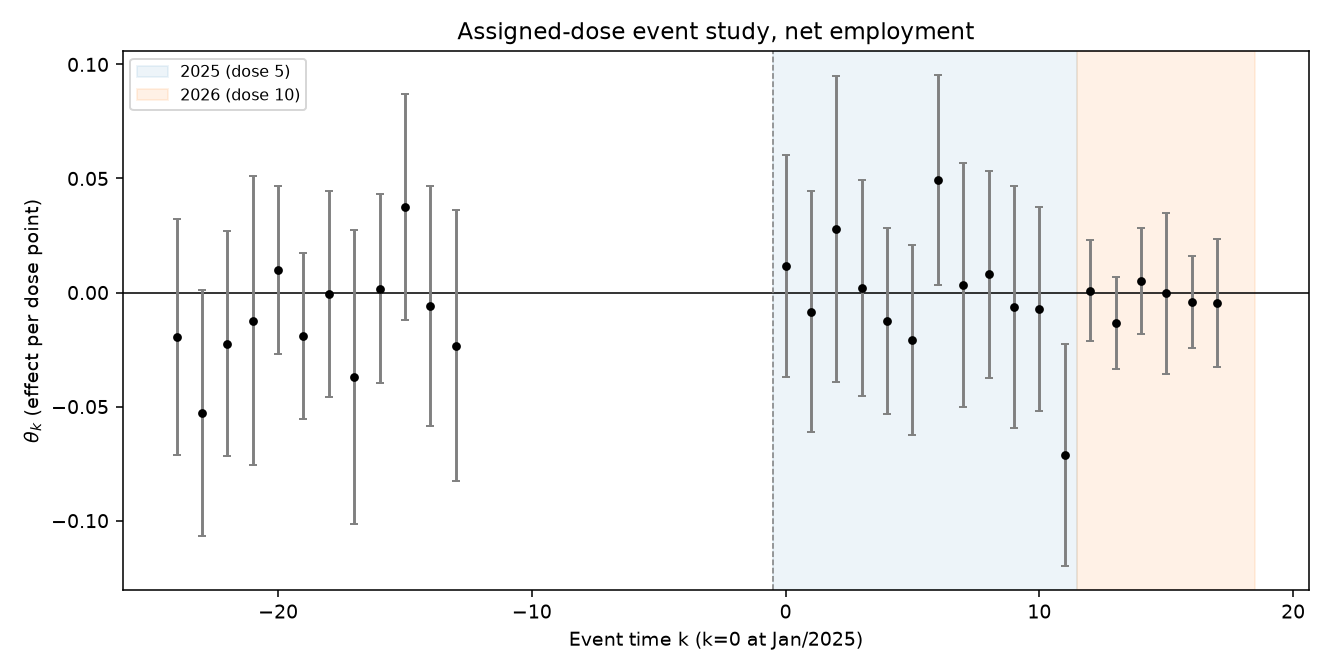

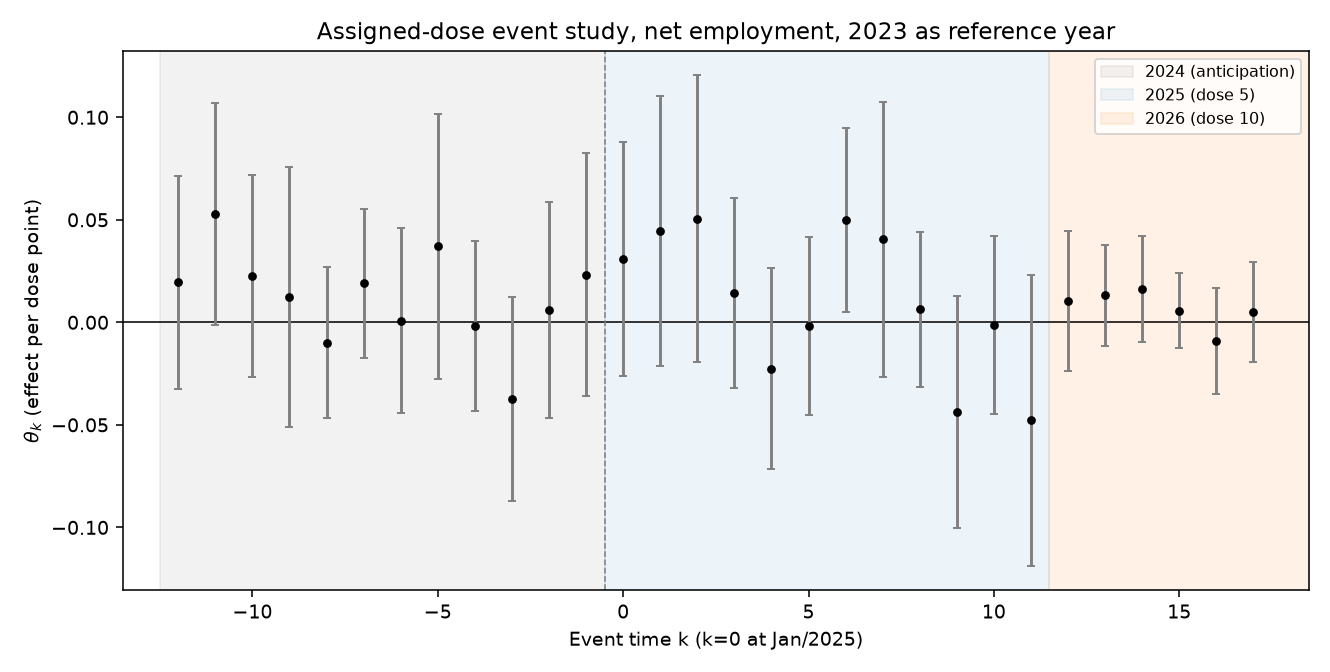

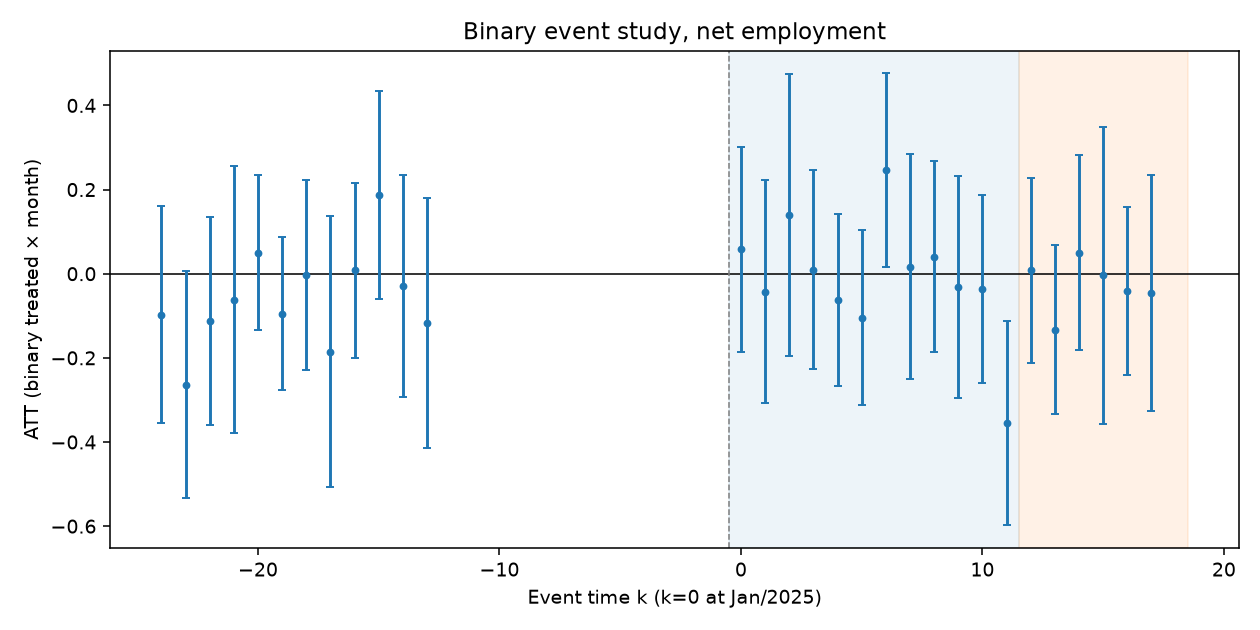

In [27]:
from IPython.display import Image, display
for f in ['fig_es_dose_base2024_saldo.png','fig_es_dose_base2023_saldo.png','fig_es_binario_base2024_saldo.png']:
    p='/workspace/notebook_outputs/figuras_en_v3/'+f
    import os
    if os.path.exists(p): display(Image(filename=p))
    else: print('não achei',p)